# ETTm1 End-to-End Forecasting Notebook

This notebook implements a full ETTm1 forecasting workflow with standardized splits, metrics, and reporting conventions for reproducible comparison.
It covers data quality checks, feature preparation, baseline and conventional machine models, deep models, interpretability, ablations, robustness tests, and deployment-oriented conclusions.

## Table of Contents
1. Data Loading and Setup
2. Exploratory Data Analysis
3. Preprocessing and Feature Engineering
4. Baseline and Conventional Machine Models (with Optuna Tuning)
5. Deep Learning Models (with Optuna Tuning)
6. Model Comparison and Visualization
7. Interpretability and Error Diagnostics
8. Ablation Studies
9. Robustness and Stress Testing
10. Final Conclusions and Deployment Recommendations

## Environment Setup

Before running this cell, ensure `requirements.txt` is placed in the **same directory** as this notebook.

If using Azure or JupyterHub, upload `requirements.txt` to the working directory first.

After installation completes, **restart the kernel** before proceeding to the next cell.

In [2]:
import subprocess
import sys
import importlib
import importlib.metadata
import os

# Fallback dependency list if requirements.txt is not found
REQUIREMENTS = [
    # Core
    'numpy',
    'pandas',
    'scikit-learn',
    'scipy',
    # Visualization
    'matplotlib',
    'seaborn',
    # Time-series
    'statsmodels',
    # Deep learning
    'torch',
    'torchvision',
    'pytorch-tcn',
    'reformer-pytorch',
    # ML baseline
    'catboost',
    'optuna',
    # Explainability
    'shap',
    'lime',
    # Notebook runtime
    'ipywidgets',
]

# Package name mapping: display_name -> (import_name, pip_name)
PACKAGES_TO_CHECK = {
    'numpy':       ('numpy',       'numpy'),
    'pandas':      ('pandas',      'pandas'),
    'sklearn':     ('sklearn',     'scikit-learn'),
    'scipy':       ('scipy',       'scipy'),
    'matplotlib':  ('matplotlib',  'matplotlib'),
    'seaborn':     ('seaborn',     'seaborn'),
    'statsmodels': ('statsmodels', 'statsmodels'),
    'torch':       ('torch',       'torch'),
    'optuna':      ('optuna',      'optuna'),
    'shap':        ('shap',        'shap'),
    'lime':        ('lime',        'lime'),
}

def install_from_file(req_path):
    """Install dependencies from requirements.txt."""
    return subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-r', req_path, '--quiet'],
        capture_output=True, text=True
    )

def install_from_list(req_list):
    """Install dependencies from inline list."""
    return subprocess.run(
        [sys.executable, '-m', 'pip', 'install'] + req_list + ['--quiet'],
        capture_output=True, text=True
    )

def verify_packages(packages):
    """Verify installed packages and return (installed_lines, missing_list)."""
    missing = []
    installed = []
    for display_name, (import_name, pip_name) in packages.items():
        try:
            importlib.import_module(import_name)
            try:
                version = importlib.metadata.version(pip_name)
            except importlib.metadata.PackageNotFoundError:
                mod = importlib.import_module(import_name)
                version = getattr(mod, '__version__', 'installed')
            installed.append(f'  {display_name:<14}: {version}')
        except ImportError:
            missing.append(display_name)
    return installed, missing

# Determine installation source
req_path = 'requirements.txt'
used_fallback = False

if os.path.exists(req_path):
    print(f'requirements.txt found at: {os.path.abspath(req_path)}')
    print('Installing dependencies from requirements.txt ...')
    result = install_from_file(req_path)
else:
    print('[WARNING] requirements.txt not found in the current directory.')
    print(f'          Current directory: {os.getcwd()}')
    print('          Falling back to inline dependency list ...')
    used_fallback = True
    result = install_from_list(REQUIREMENTS)

# Check installation result
if result.returncode != 0:
    print('\n[ERROR] pip install failed:')
    print(result.stderr)
    print('\nPlease check the error above and resolve manually.')
    raise RuntimeError('Dependency installation failed.')
else:
    if used_fallback:
        print('Fallback installation completed successfully.')
        print('[NOTE] For full reproducibility, please place requirements.txt')
        print(f'       in the same directory as this notebook: {os.getcwd()}')
    else:
        print('Installation from requirements.txt completed successfully.')

# Verify packages and print summary
print('\nPackage verification:')
installed_lines, missing = verify_packages(PACKAGES_TO_CHECK)

for line in installed_lines:
    print(line)

if missing:
    print(f'\n[WARNING] The following packages could not be imported: {missing}')
    print('          Please re-run this cell or manually install the missing packages.')
else:
    print('\nAll required packages are available.')

print('\n[REMINDER] If any package was freshly installed or upgraded,')
print('           please restart the kernel before running further cells.')

requirements.txt found at: e:\Desktop\WM9B7-ETTm-Forecasting\requirements.txt
Installing dependencies from requirements.txt ...
Installation from requirements.txt completed successfully.

Package verification:
  numpy         : 2.4.4
  pandas        : 3.0.2
  sklearn       : 1.8.0
  scipy         : 1.17.1
  matplotlib    : 3.10.8
  seaborn       : 0.13.2
  statsmodels   : 0.14.6
  torch         : 2.11.0+cu128
  optuna        : 4.8.0
  shap          : 0.51.0
  lime          : 0.2.0.1

All required packages are available.

[REMINDER] If any package was freshly installed or upgraded,
           please restart the kernel before running further cells.


# 1. Data Loading and Setup

This section configures reproducibility controls, runtime settings, and data paths, then loads the ETTm1 source data.
It establishes a deterministic and validated starting point for all downstream experiments.

In [3]:
# Data Loading and Setup
import os
import sys
import json
import time
import math
import hashlib
import random
import subprocess
import importlib
from pathlib import Path
from types import SimpleNamespace

# Data science and visualization stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML baseline models and preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor

# Deep Learning framework
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Time-series diagnostics and decomposition
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Optional dependencies for tuning and interpretability
try:
    import optuna
    OPTUNA_AVAILABLE = True
except Exception:
    OPTUNA_AVAILABLE = False

try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False

# Compute device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Global seed configuration for strict reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Environment logging for audit trails
print(f'Python: {sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'Pandas: {pd.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'CUDA: {torch.version.cuda}')
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print(f'Optuna available: {OPTUNA_AVAILABLE}')
print(f'SHAP available: {SHAP_AVAILABLE}')

Python: 3.13.12
PyTorch: 2.11.0+cu128
Pandas: 3.0.2
NumPy: 2.4.4
Device: cuda
CUDA: 12.8
GPU: NVIDIA GeForce GTX 1650 Ti
Optuna available: True
SHAP available: True


In [4]:
# Global experiment hyperparameters and model configurations
CONFIG = {
    'seed': SEED,
    'dataset_name': 'ETTm1',
    'paper_split': 'informer_ettm1_12_4_4',
    'task_mode': 'M',  # M: multivariate forecasting

    # Forecasting horizons (Windowing logic)
    'seq_len': 96,
    'label_len': 48,
    'pred_len': 96,

    'batch_size': 512,
    'epochs': 12,
    'patience': 3,
    'learning_rate': 1.0e-3,
    'weight_decay': 3e-3,
    'dropout': 0.30,
    'grad_clip_max_norm': 1.0,
    'use_amp': True,
    'dl_num_workers': 2,
    'dl_pin_memory': True,
    'max_train_seconds_per_model': 720,
    'global_max_epochs_cap': 12,
    'global_patience_cap': 3,
    'aggressive_regularization': True,
    'dl_full_epochs': 20,
    'dl_disable_early_stopping': True,
    'loss_plot_smoothing_window': 3,
    'loss_plot_ymin': 0.2,
    'loss_plot_ymax': 0.6,

    'dl_models': ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer'],

    # dl_tune_mode: 'auto' | 'on' | 'off'
    # - auto: if env supports tuning then tune; otherwise fallback to defaults
    # - on: force attempt tuning; if unavailable still fallback to defaults
    # - off: always skip tuning and use defaults
    'dl_tune_mode': 'auto',
    'dl_tune_enabled': True,
    'dl_tune_trials': 8,
    'dl_tune_timeout_sec': 240,
    'dl_tune_subsample_frac': 0.35,
    'dl_tune_max_samples': 8000,
    'dl_tune_batch_size': 512,
    'dl_tune_num_workers': 2,
    'dl_tune_max_train_seconds_per_trial': 120,
    'dl_tune_pruner': 'hyperband',
    'dl_tune_hb_min_resource': 4,
    'dl_tune_hb_reduction_factor': 2,
    'dl_use_revin_all_models': True,
    'dl_input_noise_std': 0.03,
    'dl_input_noise_scan': [0.03, 0.05, 0.08],
    'dl_early_stop_min_delta': 5e-4,
    'dl_loss': 'mse',
    'dl_scheduler': 'cosine',
    'dl_scheduler_tmax': 12,

    'lstm_hidden': 96,
    'lstm_layers': 1,
    'gru_hidden': 96,
    'gru_layers': 1,
    'lstm_gru_input_dropout': 0.33,
    'lstm_gru_head_dropout': 0.35,

    'informer_d_model': 96,
    'informer_nhead': 4,
    'informer_layers': 1,
    'informer_ffn': 128,
    'informer_dropout': 0.45,
    'informer_droppath': 0.15,
    'informer_pool_last_k': 16,

    'dlinear_ma_window': 37,

    'tcn_channels': 96,
    'tcn_levels': 3,
    'tcn_kernel_size': 3,

    'mlp_hidden': 192,
    'mlp_layers': 1,

    'itransformer_d_model': 96,
    'itransformer_nhead': 4,
    'itransformer_layers': 2,
    'itransformer_ffn': 192,
    'itransformer_dropout': 0.31,
    'itransformer_droppath': 0.06,
    'itransformer_learning_rate': 3.0e-4,

    'ridge_alpha': 1.0,
    'ridge_fit_intercept': True,
    'knn_n_neighbors': 12,
    'knn_weights': 'distance',
    'knn_leaf_size': 30,
    'knn_try_gpu': True,

    'tune_trials': 6,
    'tune_timeout_sec': 180,
    'tune_subsample_frac': 0.25,
    'max_tune_samples': 12000,

    'latency_warmup': 10,
    'latency_runs': 80,
    'xai_kernel_background': 20,
    'xai_kernel_explain': 4,
    'xai_kernel_nsamples': 40
}

# Directory management for experiment artifacts
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_SUBDIRS = {
    'configs': OUTPUT_DIR / 'configs',
    'figures': OUTPUT_DIR / 'figures',
    'models': OUTPUT_DIR / 'models',
    'tables': OUTPUT_DIR / 'tables',
    'xai': OUTPUT_DIR / 'xai'
}

# Initialize subdirectories
for _p in OUTPUT_SUBDIRS.values():
    _p.mkdir(parents=True, exist_ok=True)

def out_path(kind, filename):
    """Returns the full path for a specific output category."""
    return OUTPUT_SUBDIRS[str(kind)] / str(filename)

# Persistence of configuration for auditability
with open(out_path('configs', 'config.json'), 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2)

print('Configuration file written: outputs/configs/config.json')

Configuration file written: outputs/configs/config.json


In [5]:
# Dataset source and local persistence for reproducibility
dataset_name = 'ETTm1'
dataset_key = 'ettm1'
DATA_URL = 'https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv'
DATA_PATH = Path('ETTm1.csv')

print(f'Data source: {DATA_URL}')
df = pd.read_csv(DATA_URL)

# Optional local cache write for reproducibility metadata
if DATA_PATH.exists():
    print(f'Local cache exists, skip write: {DATA_PATH}')
else:
    df.to_csv(DATA_PATH, index=False)
    print(f'Local cache created: {DATA_PATH}')

# Standardize temporal index and enforce chronological order
if 'date' not in df.columns:
    raise ValueError('Expected a date column named "date" in the dataset.')
df['date'] = pd.to_datetime(df['date'])
duplicate_count = df.duplicated(subset='date').sum()
if duplicate_count > 0:
    print(f'Removed duplicate timestamps: {duplicate_count}')
    df = df.drop_duplicates(subset='date')
df = df.sort_values('date').reset_index(drop=True)

# Data integrity fingerprinting
sha256 = hashlib.sha256(df.to_csv(index=False).encode('utf-8')).hexdigest()
print(f'Dataset: {dataset_name}')
print(f'Data shape: {df.shape}')
print(f'Date range: {df.date.min()} -> {df.date.max()}')
print(f'SHA256 (current dataframe): {sha256[:16]}...')
print('Null counts:')
print(df.isnull().sum())

# Validate 15-min frequency and perform gap alignment
expected_freq = '15min'
actual_ts = pd.DatetimeIndex(df['date'])
expected_ts = pd.date_range(start=actual_ts.min(), end=actual_ts.max(), freq=expected_freq)
missing_ts = expected_ts.difference(actual_ts)
extra_ts = actual_ts.difference(expected_ts)

print(f'Expected freq: {expected_freq}')
print(f'Expected timestamps: {len(expected_ts)}, actual: {len(actual_ts)}')
print(f'Missing timestamps: {len(missing_ts)} | Extra timestamps: {len(extra_ts)}')

if len(missing_ts) > 0:
    print('First missing timestamps:', list(missing_ts[:5]))
if len(extra_ts) > 0:
    print('First extra timestamps:', list(extra_ts[:5]))
if len(missing_ts) > 0 or len(extra_ts) > 0:
    print(f'Data discontinuity detected. Expected: {len(expected_ts)}, Actual: {len(actual_ts)}')
    expected_ts.name = 'date'
    df = df.set_index('date').reindex(expected_ts)
    df = df.ffill().bfill().reset_index()
    print(f'Alignment complete. New shape: {df.shape}')
else:
    print('Timestamp continuity check: passed.')

# Define multivariate features and compute descriptive statistics
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
if all(c in df.columns for c in base_cols):
    numeric_cols = base_cols.copy()
else:
    numeric_cols = [c for c in df.columns if c != 'date' and pd.api.types.is_numeric_dtype(df[c])]

print(f'Numeric feature columns ({len(numeric_cols)}): {numeric_cols}')
print(df[numeric_cols].describe().T)

df.head()

Data source: https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv
Local cache exists, skip write: ETTm1.csv
Dataset: ETTm1
Data shape: (69680, 8)
Date range: 2016-07-01 00:00:00 -> 2018-06-26 19:45:00
SHA256 (current dataframe): b80f6e35ba995b87...
Null counts:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64
Expected freq: 15min
Expected timestamps: 69680, actual: 69680
Missing timestamps: 0 | Extra timestamps: 0
Timestamp continuity check: passed.
Numeric feature columns (7): ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
        count       mean       std        min    25%     50%     75%     max
HUFL  69680.0   7.413993  7.082928 -23.242001  5.827   8.841  11.788  24.180
HULL  69680.0   2.261418  2.041293  -5.693000  0.804   2.210   3.684  10.315
MUFL  69680.0   4.322226  6.829189 -26.367001  3.305   6.005   8.635  18.087
MULL  69680.0   0.896509  1.807239  -6.041000 -0.284   0.959   2.203   7.853
LUFL  6

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


Key Finding: The ETTm1 dataset (69,680 x 8) is temporally complete at a 15-minute frequency, with zero missing values and full timestamp continuity, while the seven numeric variables exhibit substantial cross-feature scale and dispersion heterogeneity.

# 2. Exploratory Data Analysis (EDA)

This section examines temporal behavior, scale characteristics, and cross-variable structure using summary statistics and visual diagnostics.
Its purpose is to validate data quality and inform subsequent feature and model design choices.

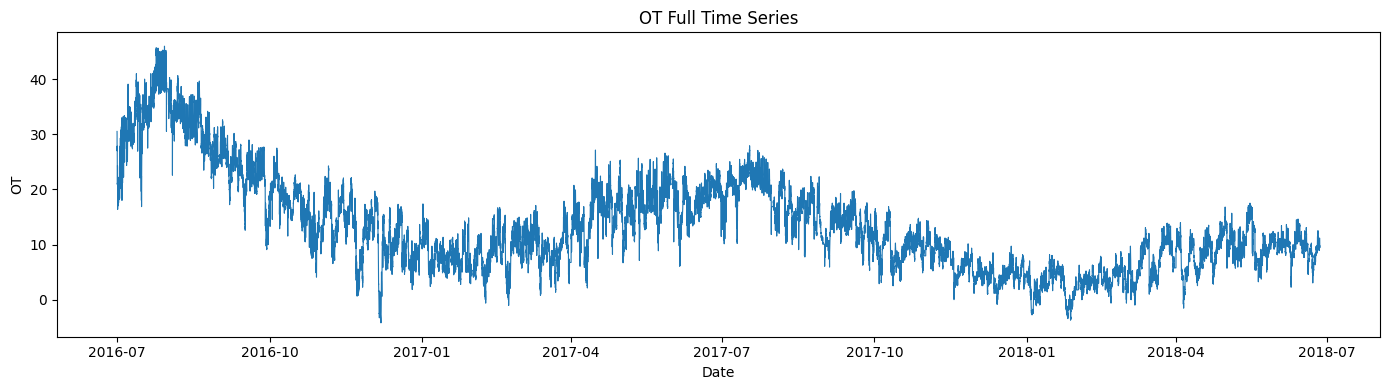

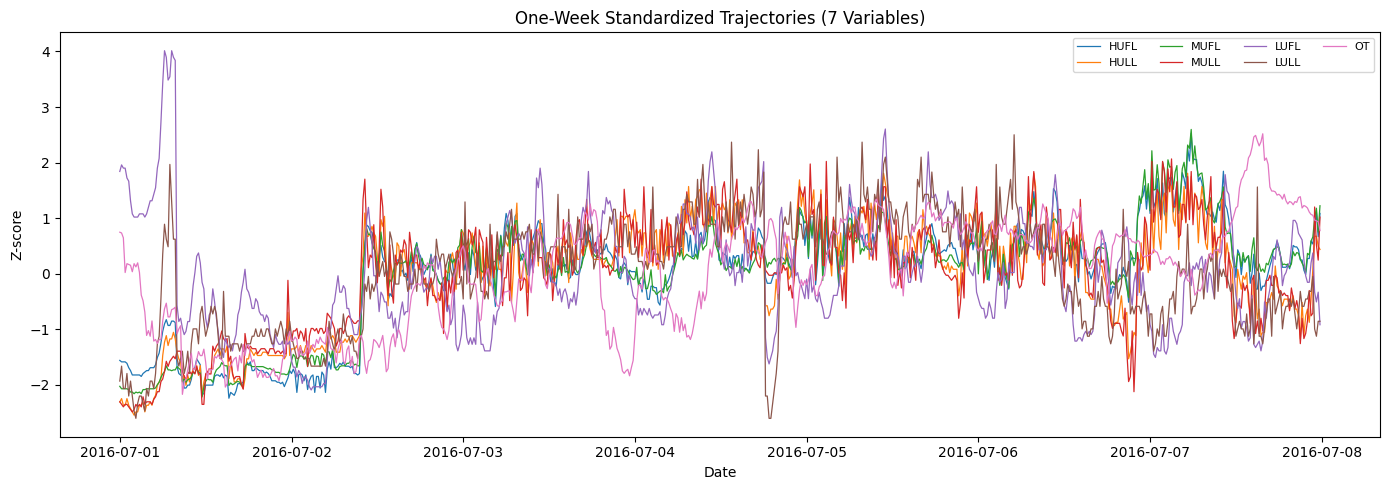

In [6]:
# EDA for multivariate M setting
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

# Visualise long-term temporal trends and seasonal variations for the target (OT)
plt.figure(figsize=(14, 4))
plt.plot(df['date'], df['OT'], linewidth=0.8)
plt.title('OT Full Time Series')
plt.xlabel('Date')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_full_series.png'), dpi=150)
plt.show()

# Isolate a high-resolution one-week window for granular periodicity analysis
week_points = 7 * 24 * 4
subset = df.iloc[:week_points].copy()

# Standardise via Z-score to compare cross-variable trajectories and synchronization
z = subset[base_cols].copy()
z = (z - z.mean()) / (z.std() + 1e-8)
plt.figure(figsize=(14, 5))
for c in base_cols:
    plt.plot(subset['date'], z[c], linewidth=0.9, label=c)
plt.title('One-Week Standardized Trajectories (7 Variables)')
plt.xlabel('Date')
plt.ylabel('Z-score')
plt.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_week_multivariate_standardized.png'), dpi=150)
plt.show()

Key Finding: The OT series shows clear long-horizon regime shifts with recurring seasonal-like oscillations, while one-week standardized trajectories reveal synchronized short-term co-movement across variables alongside distinct feature-specific volatility and amplitude profiles.

ADF stationarity test across all target variables
Variable  ADF Statistic  p-value     Status
    HUFL       -43.0398 0.00e+00 Stationary
    HULL       -19.6061 0.00e+00 Stationary
    MUFL       -44.1093 0.00e+00 Stationary
    MULL       -19.0080 0.00e+00 Stationary
    LUFL       -25.1735 0.00e+00 Stationary
    LULL       -11.8879 5.96e-22 Stationary
      OT        -6.8655 1.56e-09 Stationary


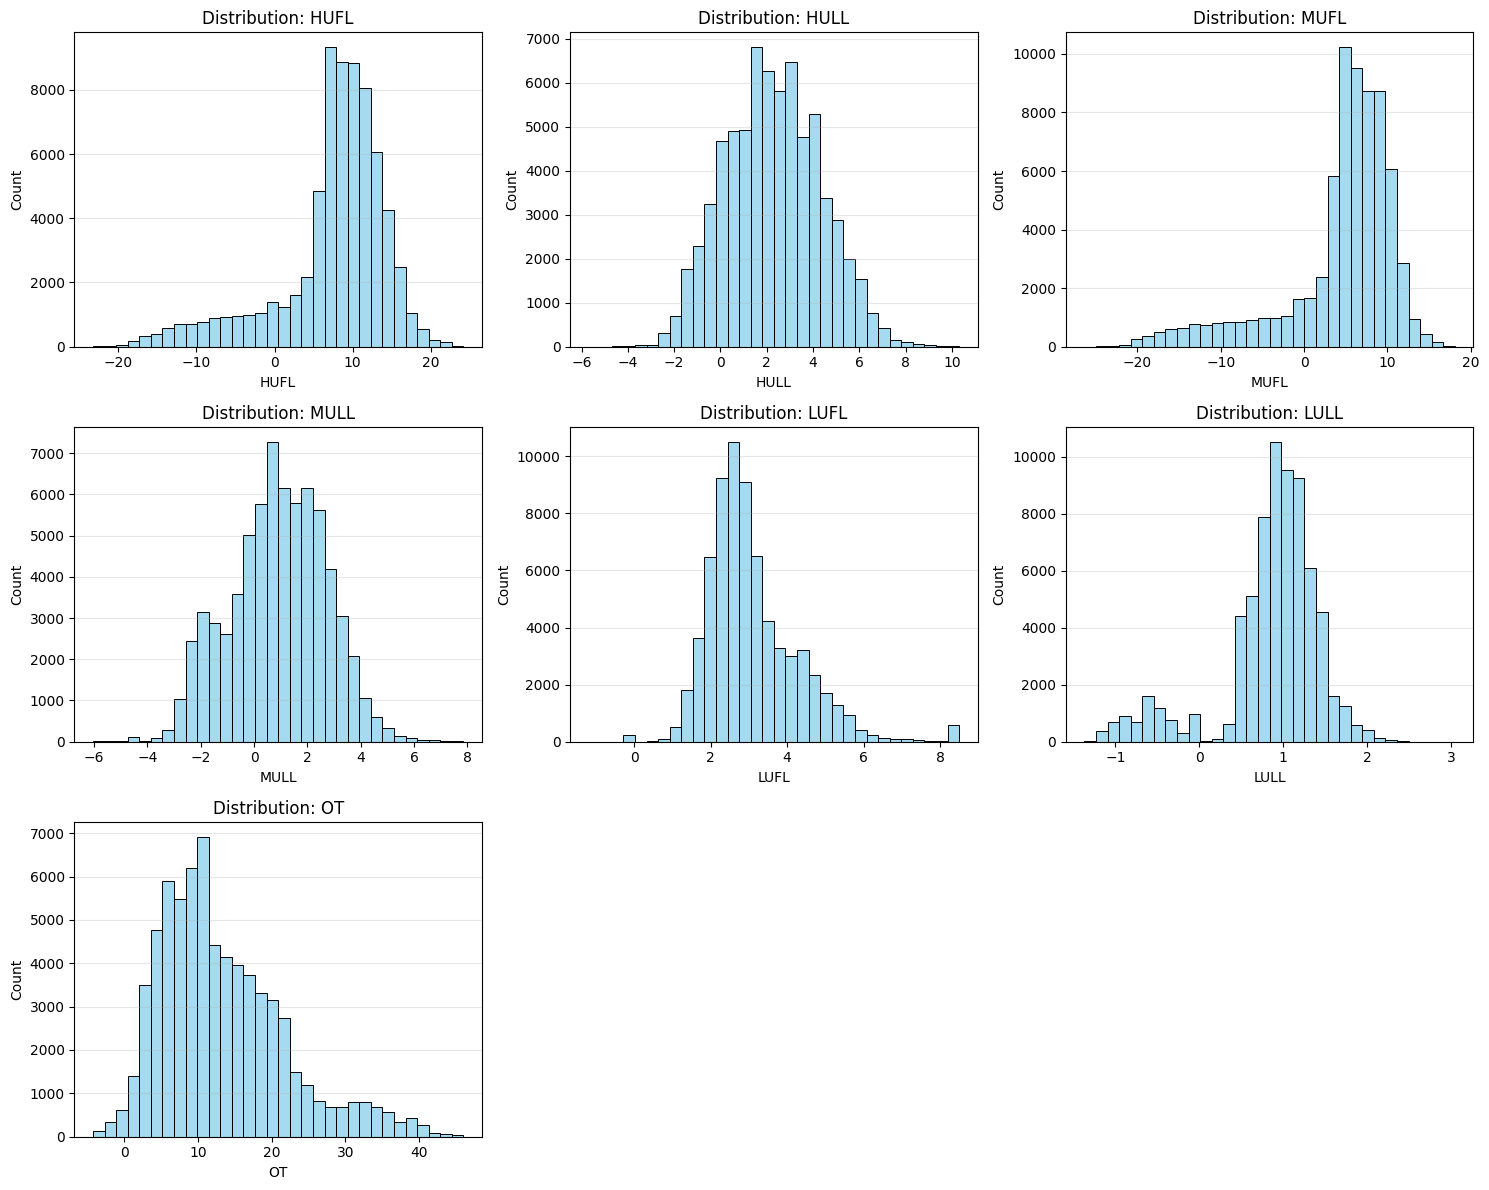

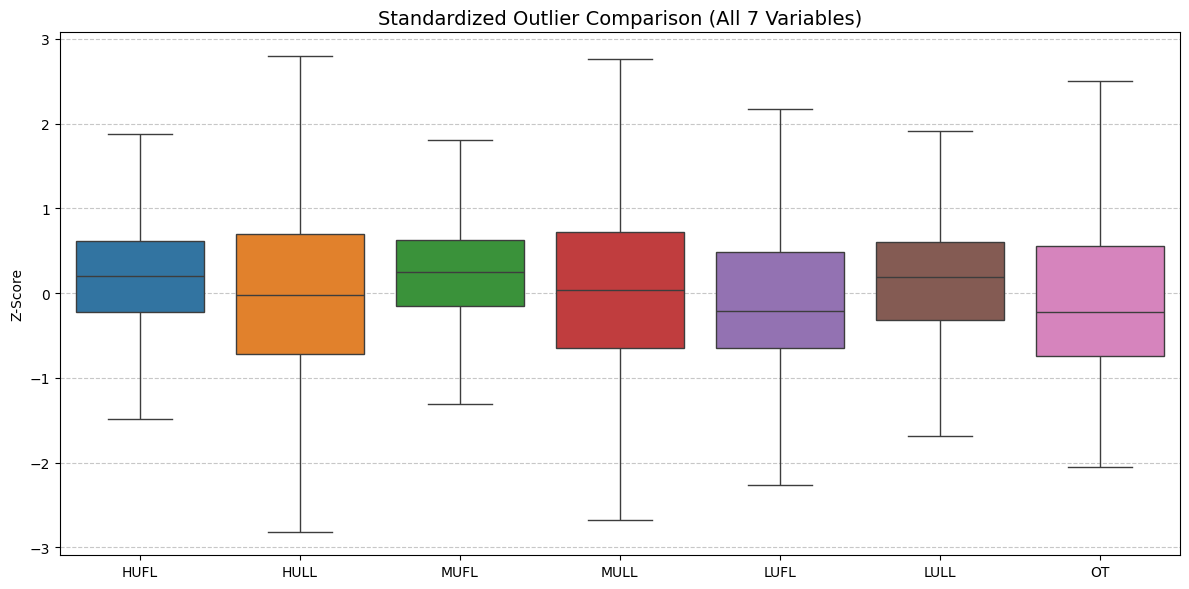

STL variables: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT'], window: 2688 points


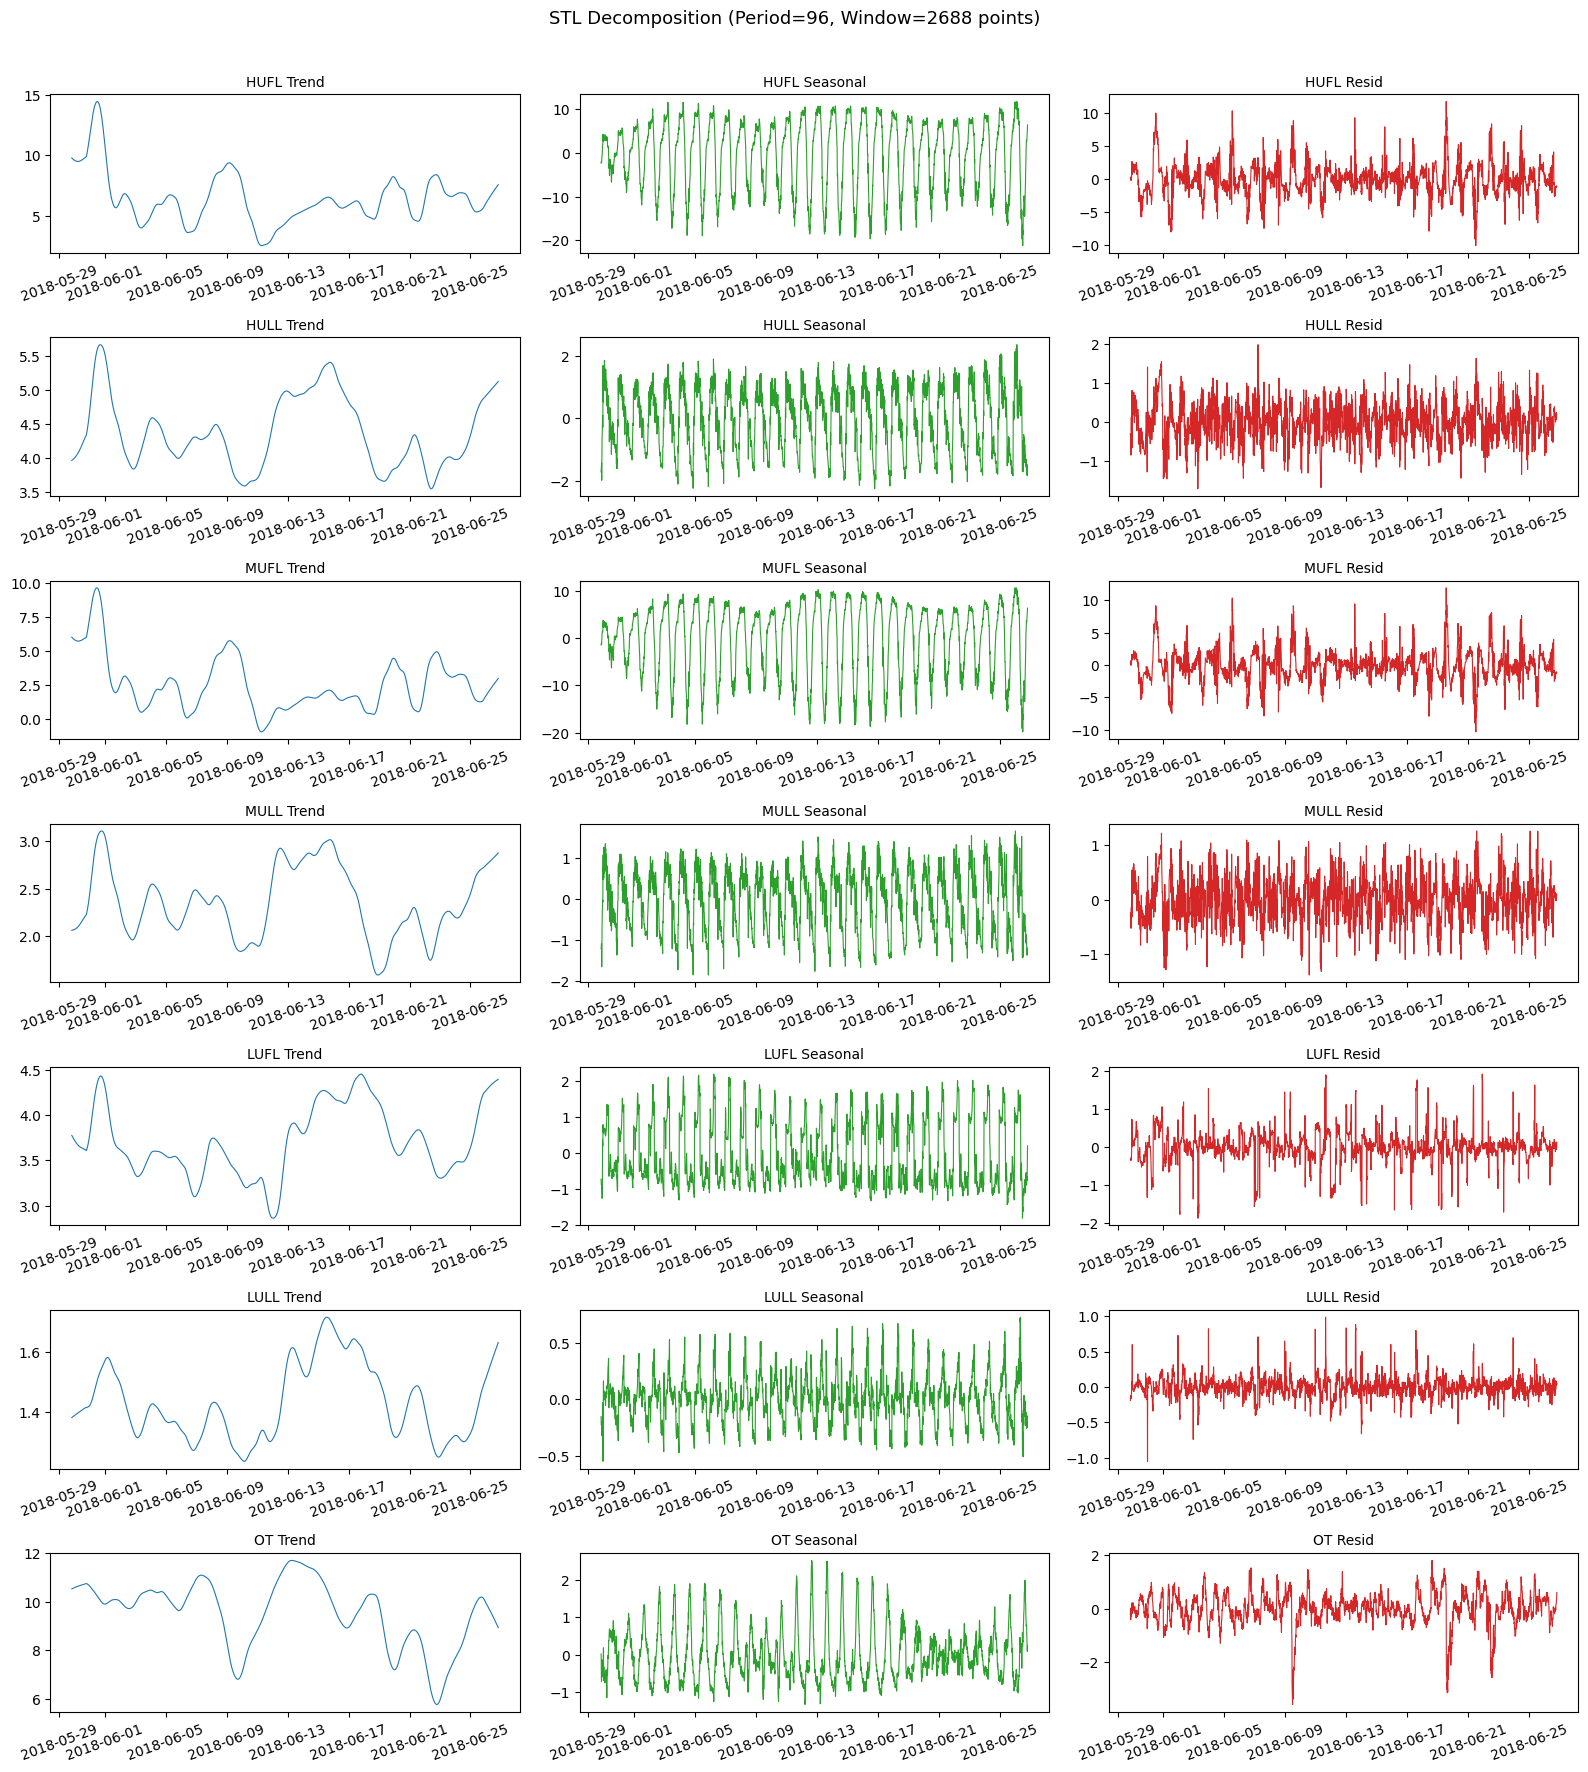

Seasonal strength summary (higher means stronger seasonality):
Variable  Seasonal Strength
    HUFL           0.913425
    MUFL           0.904844
    HULL           0.825719
    LUFL           0.809708
    MULL           0.776075
    LULL           0.694603
      OT           0.586192


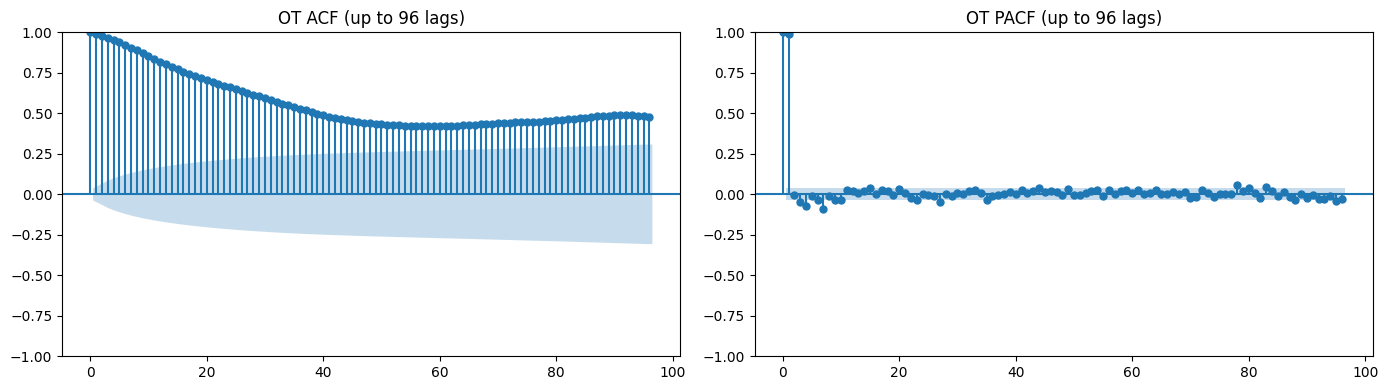

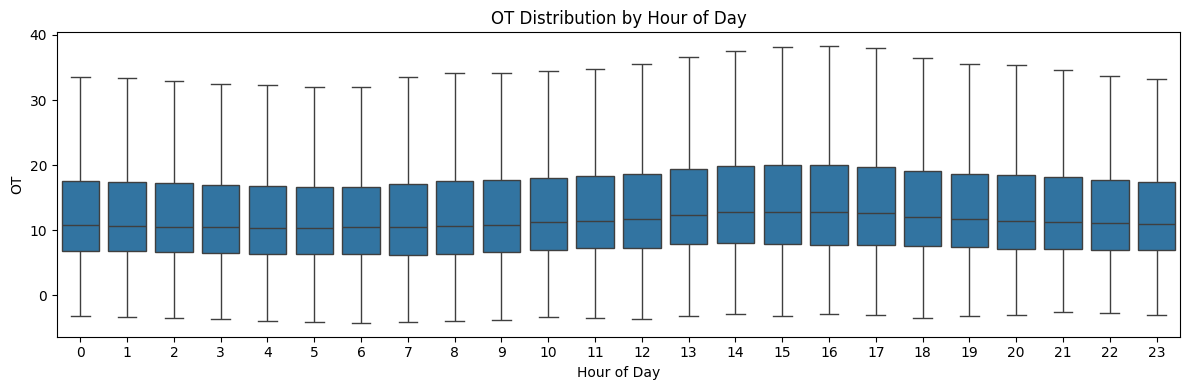

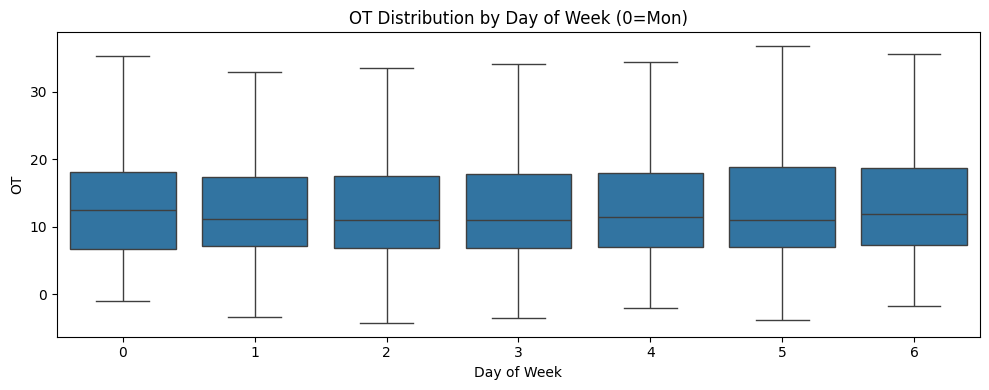

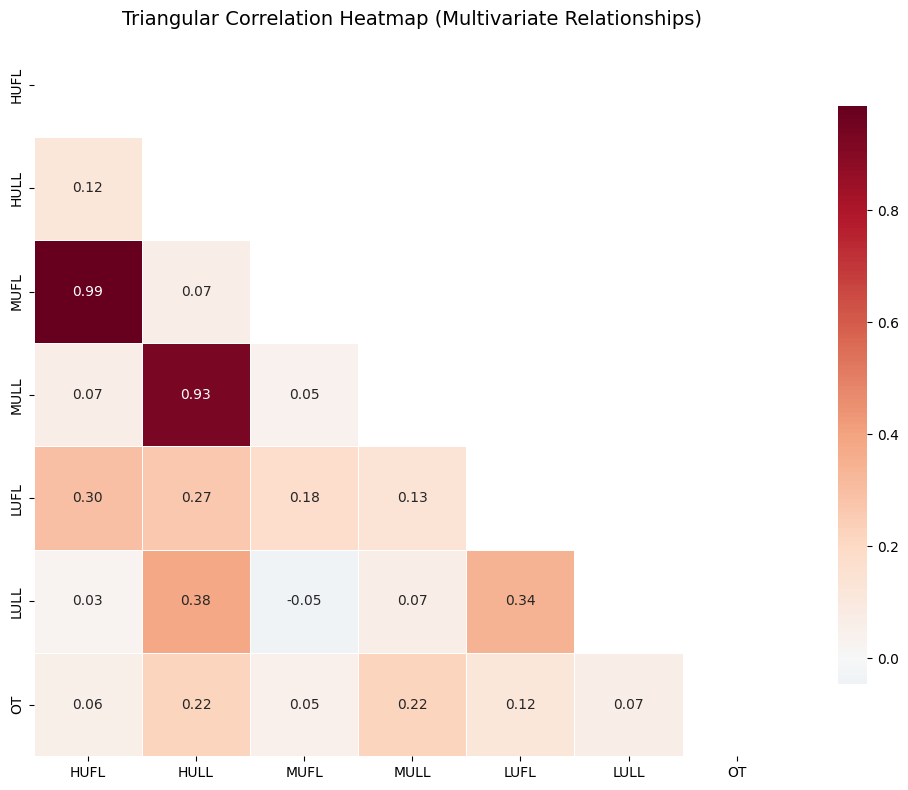

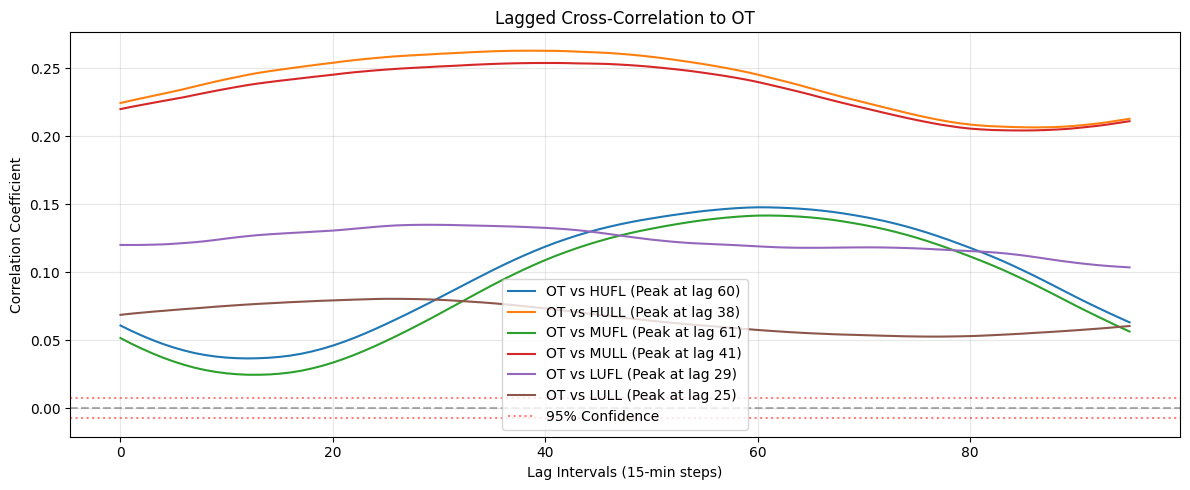

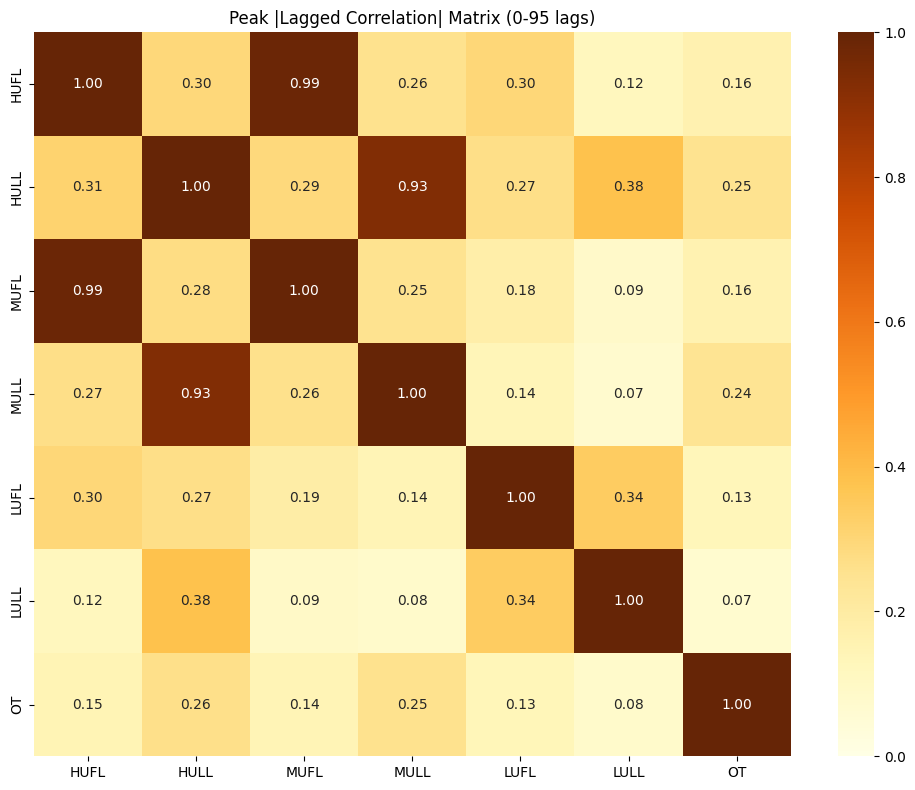

Strongest pair by peak lagged correlation: HUFL vs MUFL (0.987)
HUFL-HULL peak lagged correlation: 0.296. This may indicate feature redundancy.
EDA diagnostics completed in 26.96s


In [7]:
# Perform Augmented Dickey-Fuller (ADF) tests to verify feature stationarity and unit root presence
print('ADF stationarity test across all target variables')

if 'base_cols' not in globals():
    base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
if 'numeric_cols' not in globals():
    numeric_cols = [c for c in base_cols if c in df.columns]
if 'date' not in df.columns:
    raise ValueError('Expected date column in dataframe.')

missing_required = [c for c in base_cols if c not in df.columns]
if len(missing_required) > 0:
    raise ValueError(f'Missing expected base columns: {missing_required}')

numeric_cols = [c for c in numeric_cols if pd.api.types.is_numeric_dtype(df[c])]
if len(numeric_cols) == 0:
    raise ValueError('No numeric columns available for EDA.')

# Maintain consistent feature ordering for all subsequent diagnostic visualisations
ordered_cols = [c for c in base_cols if c in numeric_cols]
extra_cols = [c for c in numeric_cols if c not in ordered_cols]
numeric_cols = ordered_cols + extra_cols

t0 = time.perf_counter()

adf_results = []
for col in base_cols:
    res = adfuller(df[col].values, maxlag=24, autolag='AIC')
    is_stationary = res[1] < 0.05
    adf_results.append({
        'Variable': col,
        'ADF Statistic': float(f'{res[0]:.4f}'),
        'p-value': f'{res[1]:.2e}' if res[1] < 0.001 else f'{res[1]:.6f}',
        'Status': 'Stationary' if is_stationary else 'Non-Stationary'
    })

adf_df = pd.DataFrame(adf_results)
print(adf_df.to_string(index=False))

# Visualize marginal distributions to assess skewness and multi-modality
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes_flat = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, bins=32, kde=False, ax=axes_flat[i], color='skyblue')
    axes_flat[i].set_title(f'Distribution: {col}', fontsize=12)
    axes_flat[i].grid(axis='y', alpha=0.3)
for j in range(len(numeric_cols), len(axes_flat)):
    axes_flat[j].axis('off')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_distributions.png'), dpi=150)
plt.show()

# Compare feature variances and outlier profiles via standardized boxplots
plt.figure(figsize=(12, 6))
df_std = (df[numeric_cols] - df[numeric_cols].mean()) / (df[numeric_cols].std() + 1e-8)
sns.boxplot(data=df_std, showfliers=False)
plt.title('Standardized Outlier Comparison (All 7 Variables)', fontsize=14)
plt.ylabel('Z-Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_boxplot_standardized.png'), dpi=150)
plt.show()

# Execute STL decomposition to quantify trend, seasonality, and residual (noise) components
stl_period = 24 * 4
stl_cols = [c for c in base_cols if c in df.columns]
stl_points = min(len(df), stl_period * 7 * 4)  # last 4 weeks
stl_df = df[['date'] + stl_cols].iloc[-stl_points:].copy()
print(f'STL variables: {stl_cols}, window: {stl_points} points')

n_rows = len(stl_cols)
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 2.5 * n_rows), sharex=False)
if n_rows == 1:
    axes = np.array([axes])

seasonal_strength_rows = []
for i, col in enumerate(stl_cols):
    y = stl_df[col].astype(float).values
    if np.isnan(y).any():
        y = pd.Series(y).ffill().bfill().values
    stl_res = STL(y, period=stl_period, robust=False).fit()

    # Calculate seasonal strength metric: 1 - Var(resid) / Var(seasonal + resid)
    seasonal_var = np.var(stl_res.seasonal)
    resid_var = np.var(stl_res.resid)
    denom_var = seasonal_var + resid_var + 1e-8
    seasonal_strength = max(0.0, 1.0 - (resid_var / denom_var))
    seasonal_strength_rows.append({'Variable': col, 'Seasonal Strength': seasonal_strength})

    axes[i, 0].plot(stl_df['date'], stl_res.trend, linewidth=0.8, color='#1f77b4')
    axes[i, 0].set_title(f'{col} Trend', fontsize=10)
    axes[i, 1].plot(stl_df['date'], stl_res.seasonal, linewidth=0.8, color='#2ca02c')
    axes[i, 1].set_title(f'{col} Seasonal', fontsize=10)
    axes[i, 2].plot(stl_df['date'], stl_res.resid, linewidth=0.8, color='#d62728')
    axes[i, 2].set_title(f'{col} Resid', fontsize=10)
for ax in axes.flatten():
    ax.tick_params(axis='x', labelrotation=20)
plt.suptitle(f'STL Decomposition (Period=96, Window={stl_points} points)', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_stl_decomposition_all_variables.png'), dpi=150)
plt.show()

seasonal_strength_df = pd.DataFrame(seasonal_strength_rows).sort_values('Seasonal Strength', ascending=False)
print('Seasonal strength summary (higher means stronger seasonality):')
print(seasonal_strength_df.to_string(index=False))

# Analyze ACF/PACF to identify autoregressive structures and justify the 96-step look-back window
acf_lags = min(96, max(8, len(df) // 2 - 1))
ot_points = min(len(df), stl_period * 7 * 4)
ot_series = df['OT'].iloc[-ot_points:].astype(float).values

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ot_series, lags=acf_lags, ax=axes[0], alpha=0.05, title='OT ACF (up to 96 lags)')
plot_pacf(ot_series, lags=acf_lags, ax=axes[1], alpha=0.05, method='ywm', title='OT PACF (up to 96 lags)')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_acf_pacf_ot.png'), dpi=150)
plt.show()

# Examine intraday and weekly periodicities to confirm seasonal cyclic patterns for OT
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['date'].dt.hour, y=df['OT'], showfliers=False)
plt.title('OT Distribution by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_hour_of_day.png'), dpi=150)
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['date'].dt.dayofweek, y=df['OT'], showfliers=False)
plt.title('OT Distribution by Day of Week (0=Mon)')
plt.xlabel('Day of Week')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_day_of_week.png'), dpi=150)
plt.show()

# Compute contemporaneous Pearson correlations to identify feature redundancy and multi-collinearity
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, cmap='RdBu_r', center=0,
            fmt='.2f', linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Triangular Correlation Heatmap (Multivariate Relationships)', fontsize=14)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_correlation_heatmap.png'), dpi=150)
plt.show()

# Compute lagged cross-correlations to identify leading indicators for the target (OT)
arr = df[numeric_cols].astype(np.float32).values
arr_z = (arr - arr.mean(axis=0, keepdims=True)) / (arr.std(axis=0, keepdims=True) + 1e-8)
lags = min(96, len(arr_z) - 2)
if lags < 2:
    raise ValueError('Not enough samples for lagged correlation diagnostics.')

p = arr_z.shape[1]
lag_peak = np.full((p, p), -np.inf, dtype=np.float32)
other_idx = []
ot_curve_mat = None
if 'OT' in numeric_cols:
    ot_idx = numeric_cols.index('OT')
    other_idx = [i for i, c in enumerate(numeric_cols) if c != 'OT']
    ot_curve_mat = np.zeros((lags, len(other_idx)), dtype=np.float32)

for k in range(lags):
    x = arr_z[k:, :]
    y = arr_z[:len(arr_z) - k, :]
    corr_k = (x.T @ y) / max(1, x.shape[0])
    lag_peak = np.maximum(lag_peak, np.abs(corr_k))
    if ot_curve_mat is not None:
        ot_curve_mat[k, :] = corr_k[ot_idx, other_idx]

if ot_curve_mat is not None:
    plt.figure(figsize=(12, 5))
    for j, idx in enumerate(other_idx):
        curve = ot_curve_mat[:, j]
        max_lag = int(np.argmax(np.abs(curve)))
        col = numeric_cols[idx]
        plt.plot(range(lags), curve, label=f'OT vs {col} (Peak at lag {max_lag})')
    conf_level = 2.0 / np.sqrt(len(df))
    plt.axhline(conf_level, color='red', linestyle=':', alpha=0.5, label='95% Confidence')
    plt.axhline(-conf_level, color='red', linestyle=':', alpha=0.5)
    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.title('Lagged Cross-Correlation to OT')
    plt.xlabel('Lag Intervals (15-min steps)')
    plt.ylabel('Correlation Coefficient')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path('figures', 'Eda_lagged_cross_correlation_to_ot.png'), dpi=150)
    plt.show()

# Generate peak absolute lagged correlation matrix to summarize the global dependency structure
lag_peak_df = pd.DataFrame(lag_peak, index=numeric_cols, columns=numeric_cols)
plt.figure(figsize=(10, 8))
sns.heatmap(lag_peak_df, annot=True, cmap='YlOrBr', vmin=0, vmax=1, fmt='.2f')
plt.title('Peak |Lagged Correlation| Matrix (0-95 lags)')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_peak_lagged_correlation_matrix.png'), dpi=150)
plt.show()

pair_series = lag_peak_df.where(~np.eye(len(lag_peak_df), dtype=bool)).stack().sort_values(ascending=False)
if len(pair_series) > 0:
    top_pair = pair_series.index[0]
    top_val = pair_series.iloc[0]
    print(f'Strongest pair by peak lagged correlation: {top_pair[0]} vs {top_pair[1]} ({top_val:.3f})')

if 'HUFL' in lag_peak_df.index and 'HULL' in lag_peak_df.columns:
    hufl_hull = float(lag_peak_df.loc['HUFL', 'HULL'])
    print(f'HUFL-HULL peak lagged correlation: {hufl_hull:.3f}. This may indicate feature redundancy.')

print(f'EDA diagnostics completed in {time.perf_counter() - t0:.2f}s')

Key Finding: All seven variables are ADF-stationary, the series exhibits strong multi-scale seasonality with the highest seasonal strength in HUFL and MUFL and a comparatively weaker but still present seasonal component in OT, OT also shows persistent autocorrelation with distinct intraday structure (higher midday levels) and mild weekday variation, and the dependency structure is dominated by very strong coupled pairs (HUFL-MUFL and HULL-MULL) while OT maintains moderate lagged associations mainly with HULL and MULL.

Front vs Back drift summary:


,HUFL_front,HULL_front,MUFL_front,MULL_front,LUFL_front,LULL_front,OT_front,HUFL_back,HULL_back,MUFL_back,MULL_back,LUFL_back,LULL_back,OT_back
mean,7.971978,2.041194,5.086975,0.768985,2.809531,0.782098,17.152580,6.856009,2.481643,3.557478,1.024033,3.356246,0.933717,9.488703
std,5.841680,2.084099,5.533875,1.924083,1.039453,0.638211,9.142191,8.098718,1.973172,7.841141,1.672633,1.235707,0.549781,5.810876


Potential Data Drift Detected
Mean shift ratio (>10%):
OT      0.446806
MULL    0.331668
MUFL    0.300669
HULL    0.215780
LUFL    0.194593
LULL    0.193862
HUFL    0.139986


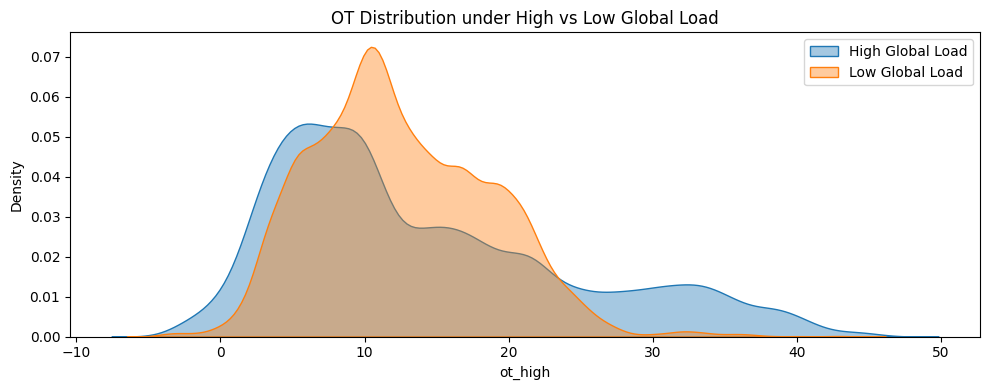

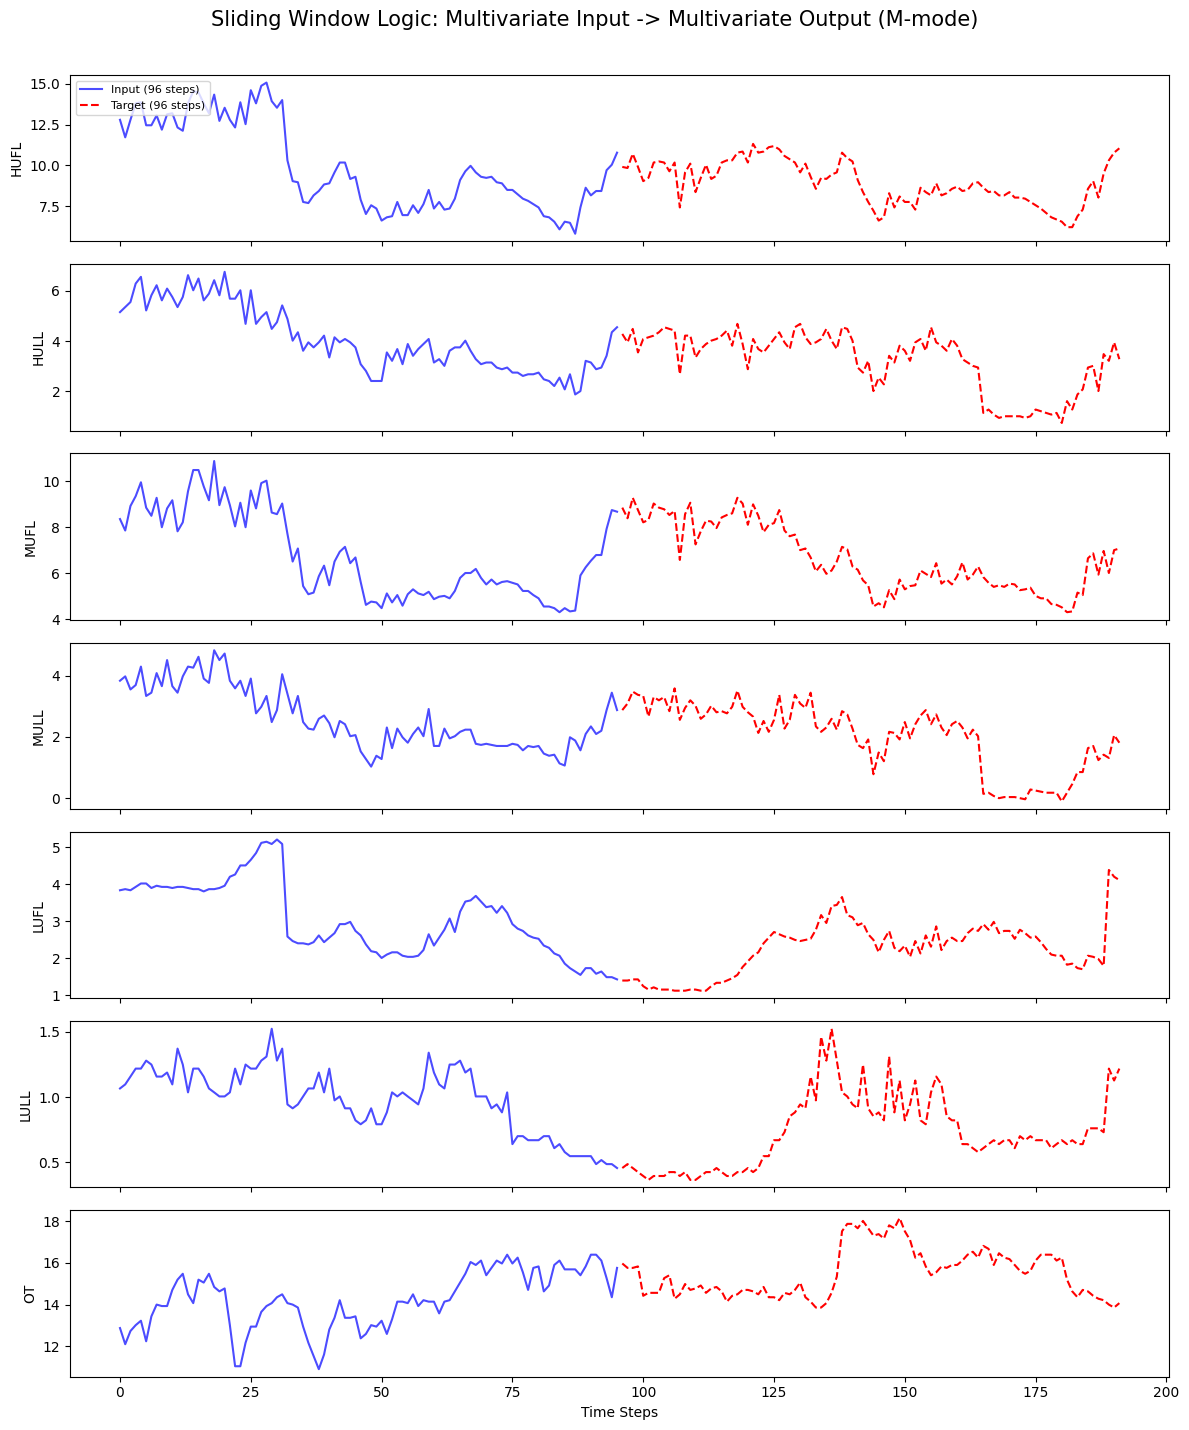

In [8]:
# Assess non-stationarity via statistical drift between temporal partitions
mid = len(df) // 2
front = df.iloc[:mid][numeric_cols].describe().loc[['mean', 'std']]
back = df.iloc[mid:][numeric_cols].describe().loc[['mean', 'std']]
drift_stats = pd.concat([front.add_suffix('_front'), back.add_suffix('_back')], axis=1)
print('Front vs Back drift summary:')
display(drift_stats)

# Detect significant covariate shift using a 10% mean-shift tolerance
mean_front = front.loc['mean']
mean_back = back.loc['mean']
mean_base = np.maximum(np.abs(mean_front.values), 1e-8)
mean_shift_ratio = np.abs(mean_back.values - mean_front.values) / mean_base
mean_shift_series = pd.Series(mean_shift_ratio, index=mean_front.index)
if (mean_shift_series > 0.10).any():
    flagged = mean_shift_series[mean_shift_series > 0.10].sort_values(ascending=False)
    print('Potential Data Drift Detected')
    print('Mean shift ratio (>10%):')
    print(flagged.to_string())
else:
    print('No significant mean drift detected (>10% threshold).')

# Evaluate target (OT) conditional distribution relative to system load intensity
load_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL']
global_load = df[load_cols].mean(axis=1)
high_load_flag = global_load > global_load.median()
high_df = df.loc[high_load_flag, ['OT']].rename(columns={'OT': 'ot_high'})
low_df = df.loc[~high_load_flag, ['OT']].rename(columns={'OT': 'ot_low'})

plt.figure(figsize=(10, 4))
sns.kdeplot(data=high_df, x='ot_high', label='High Global Load', fill=True, alpha=0.4)
sns.kdeplot(data=low_df, x='ot_low', label='Low Global Load', fill=True, alpha=0.4)
plt.title('OT Distribution under High vs Low Global Load')
plt.legend()
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_global_load_level.png'), dpi=150)
plt.show()

# Validate sliding window logic and multivariate synchronization (M-mode)
def visualize_input_output_window(df, config):
    """
    Validates multivariate input-target temporal alignment.
    """
    seq_len = config['seq_len']
    pred_len = config['pred_len']
    
    start_idx = random.randint(0, len(df) - seq_len - pred_len)
    window_data = df.iloc[start_idx : start_idx + seq_len + pred_len]
    
    fig, axes = plt.subplots(7, 1, figsize=(12, 15), sharex=True)
    cols = base_cols
    
    x_input = range(0, seq_len)
    x_output = range(seq_len, seq_len + pred_len)
    
    for i, col in enumerate(cols):
        axes[i].plot(x_input, window_data[col].iloc[:seq_len], 
                     color='blue', label='Input (96 steps)', alpha=0.7)
        axes[i].plot(x_output, window_data[col].iloc[seq_len:], 
                     color='red', label='Target (96 steps)', linestyle='--')
        axes[i].set_ylabel(col)
        if i == 0:
            axes[i].legend(loc='upper left', fontsize=8)
            
    plt.xlabel('Time Steps')
    plt.suptitle(f'Sliding Window Logic: Multivariate Input -> Multivariate Output (M-mode)', fontsize=15)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.savefig(out_path('figures', 'Eda_input_output_window.png'), dpi=150)
    plt.show()

visualize_input_output_window(df, CONFIG)

Key Finding: The dataset shows clear front-to-back drift, dominated by OT (44.7% mean shift), with higher global load linked to a heavier OT upper tail and greater spread, and the 96-to-96 sliding-window plot confirms a coherent multivariate input-output mapping.

# 3. Preprocessing and Feature Engineering

This section constructs model-ready inputs by applying chronological splits, cyclical time encoding, train-only scaling, and leakage-safe window generation.
The resulting M-96 tensors provide a consistent input/output interface for all later models.

In [9]:
df_feat = df.copy()

def encode_cyclical(df, col, max_val):
    """
    Encodes periodic temporal features into 2D circular space 
    to preserve cyclical continuity.
    """
    df[col + '_sin'] = np.sin(2 * np.pi * df[col] / max_val)
    df[col + '_cos'] = np.cos(2 * np.pi * df[col] / max_val)
    return df

# Temporal feature engineering: quarter-hour resolution
df_feat['month'] = df_feat.date.dt.month
df_feat['day'] = df_feat.date.dt.day
df_feat['weekday'] = df_feat.date.dt.weekday
df_feat['hour'] = df_feat.date.dt.hour
df_feat['minute'] = df_feat.date.dt.minute // 15 # quarter-hour index in {0,1,2,3}

df_feat = encode_cyclical(df_feat, 'month', 12)
df_feat = encode_cyclical(df_feat, 'day', 31)
df_feat = encode_cyclical(df_feat, 'weekday', 7)
df_feat = encode_cyclical(df_feat, 'hour', 24)
df_feat = encode_cyclical(df_feat, 'minute', 4)

time_cols = [
    'month_sin', 'month_cos', 'day_sin', 'day_cos', 
    'weekday_sin', 'weekday_cos', 'hour_sin', 'hour_cos',
    'minute_sin', 'minute_cos'
]

# Multivariate-to-Multivariate (M) task configuration
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
feature_cols = base_cols + time_cols
target_cols = base_cols.copy()

N = len(df_feat)
seq_len = CONFIG['seq_len']
pred_len = CONFIG['pred_len']
target_dim = len(target_cols)

assert len(feature_cols) == 17, "Input should have 7 physical + 10 cyclical time features"
assert len(target_cols) == 7, "M setting requires 7 target variables"

# Data partitioning based on ETT-standard protocol (12:4:4 months)
month_points = 30 * 24 * 4
paper_train_end = 12 * month_points
paper_val_end = 16 * month_points
paper_test_end = 20 * month_points

if N >= paper_test_end:
    train_end, val_end, test_end = paper_train_end, paper_val_end, paper_test_end
    split_mode = 'standard_12_4_4'
else:
    split_mode = 'adaptive_60_20_20'
    train_end = max(seq_len + pred_len + 1, int(N * 0.6))
    val_end = max(train_end + pred_len + 1, int(N * 0.8))
    test_end = N
    val_end = min(val_end, test_end - pred_len - 1)
    train_end = min(train_end, val_end - pred_len - 1)
    if train_end <= seq_len or val_end <= train_end or (test_end - val_end) <= pred_len:
        raise ValueError(f'Dataset too short for seq_len={seq_len}, pred_len={pred_len}: N={N}')
    print(f'Dataset length {N} is shorter than standard requirement {paper_test_end}; adaptive split is applied.')

date_diff = df_feat['date'].diff().dropna()
is_fixed_15min = bool((date_diff == pd.Timedelta(minutes=15)).all())
print(f'Fixed 15-minute intervals: {is_fixed_15min}')

# Inclusion of historical context (look-back window) for validation/test sets
border1_train, border2_train = 0, train_end
border1_val, border2_val = train_end - seq_len, val_end
border1_test, border2_test = val_end - seq_len, test_end

X_phys = df_feat[base_cols].values.astype(np.float32)
X_time = df_feat[time_cols].values.astype(np.float32)
y_raw = df_feat[target_cols].values.astype(np.float32)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

# Prevent data leakage: Fit scalers strictly on training distribution
x_scaler.fit(X_phys[border1_train:border2_train])
y_scaler.fit(y_raw[border1_train:border2_train])

X_phys_scaled = x_scaler.transform(X_phys)
X_scaled = np.concatenate([X_phys_scaled, X_time], axis=1).astype(np.float32)
y_scaled = y_scaler.transform(y_raw).astype(np.float32)

assert np.isfinite(X_scaled).all() and np.isfinite(y_scaled).all(), 'Found NaN/Inf after scaling'
print(f'Feature dim: {X_scaled.shape[1]} | Target dim: {target_dim}')
print('Task mode check: M(7->7), pred_len=96')

print(f'Split mode: {split_mode}')
print('Split boundaries (label space):')
print(f'train: [0, {train_end}) | val: [{train_end}, {val_end}) | test: [{val_end}, {test_end})')
print('Boundary timestamps:')
print(f'train end: {df_feat["date"].iloc[train_end - 1]}')
print(f'val start:  {df_feat["date"].iloc[train_end]}')
print(f'val end:    {df_feat["date"].iloc[val_end - 1]}')
print(f'test start: {df_feat["date"].iloc[val_end]}')

print('Context ranges (input space):')
print(f'train input: [{border1_train}, {border2_train})')
print(f'val input:   [{border1_val}, {border2_val})')
print(f'test input:  [{border1_test}, {border2_test})')
print(f'Forecast length (pred_len): {pred_len}')

Fixed 15-minute intervals: True
Feature dim: 17 | Target dim: 7
Task mode check: M(7->7), pred_len=96
Split mode: standard_12_4_4
Split boundaries (label space):
train: [0, 34560) | val: [34560, 46080) | test: [46080, 57600)
Boundary timestamps:
train end: 2017-06-25 23:45:00
val start:  2017-06-26 00:00:00
val end:    2017-10-23 23:45:00
test start: 2017-10-24 00:00:00
Context ranges (input space):
train input: [0, 34560)
val input:   [34464, 46080)
test input:  [45984, 57600)
Forecast length (pred_len): 96


In [10]:
def make_windows(features, target, start, end, seq_len=96, pred_len=96):
    """
    Generate sliding windows for time-series forecasting.
    Input (X): [t, t + seq_len)
    Target (Y): [t + seq_len, t + seq_len + pred_len)
    """
    xs, ys, t_idx = [], [], []
    max_i = end - seq_len - pred_len + 1
    for i in range(start, max_i):
        x = features[i:i + seq_len]
        y = target[i + seq_len:i + seq_len + pred_len] 
        xs.append(x)
        ys.append(y.reshape(-1))  
        t_idx.append(i + seq_len)
    return np.array(xs, dtype=np.float32), np.array(ys, dtype=np.float32), np.array(t_idx, dtype=np.int64)

# Multi-step windowing configuration
seq_len = CONFIG['seq_len']
pred_len = CONFIG['pred_len']

# Dataset instantiation with context-aware boundaries
X_train, y_train, idx_train = make_windows(X_scaled, y_scaled, border1_train, border2_train, seq_len, pred_len)
X_val, y_val, idx_val = make_windows(X_scaled, y_scaled, border1_val, border2_val, seq_len, pred_len)
X_test, y_test, idx_test = make_windows(X_scaled, y_scaled, border1_test, border2_test, seq_len, pred_len)

# Verification of non-overlapping splits and label-space integrity
assert idx_train.min() >= 0 and (idx_train.max() + pred_len - 1) < train_end
assert idx_val.min() >= train_end and (idx_val.max() + pred_len - 1) < val_end
assert idx_test.min() >= val_end and (idx_test.max() + pred_len - 1) < test_end
assert (idx_train.max() + pred_len - 1) < idx_val.min() < idx_test.min()

# Final data consistency check
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all(), 'NaN/Inf in windowed features'
assert y_train.shape[1] == pred_len * target_dim, 'Target flatten dim mismatch'

print('Window shapes (M->M, 96-step):')
print('Train:', X_train.shape, y_train.shape)
print('Val:  ', X_val.shape, y_val.shape)
print('Test: ', X_test.shape, y_test.shape)
print(f'Flattened target dim: {pred_len} x {target_dim} = {y_train.shape[1]}')

Window shapes (M->M, 96-step):
Train: (34369, 96, 17) (34369, 672)
Val:   (11425, 96, 17) (11425, 672)
Test:  (11425, 96, 17) (11425, 672)
Flattened target dim: 96 x 7 = 672


# 4. Baseline and Conventional Machine Models

This section trains and tunes conventional regressors (including Naive, Ridge and KNN) on flattened sequence windows under the shared M-96 protocol.
It reports comparable metrics, per-variable diagnostics, and efficiency indicators to establish non-DL reference performance.

In [11]:
def regression_metrics(y_true_scaled, y_pred_scaled):
    """Compute standard regression metrics in the normalized feature space."""
    y_true = np.asarray(y_true_scaled, dtype=np.float32)
    y_pred = np.asarray(y_pred_scaled, dtype=np.float32)
    mae = mean_absolute_error(y_true.reshape(-1), y_pred.reshape(-1))
    mse = mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1))
    rmse = np.sqrt(mse)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse}, y_true, y_pred


def inverse_scale_flat_targets(y_flat_scaled, scaler, target_dim):
    """Map flattened predictions back to the original physical scale."""
    y_flat_scaled = np.asarray(y_flat_scaled, dtype=np.float32)
    assert y_flat_scaled.ndim == 2 and y_flat_scaled.shape[1] % target_dim == 0, f"Expected 2D array with cols divisible by target_dim={target_dim}, got shape {y_flat_scaled.shape}"
    
    # Reshape to 2D for batch inverse transformation
    n = y_flat_scaled.shape[0]
    y_2d = y_flat_scaled.reshape(-1, target_dim)
    y_inv_2d = scaler.inverse_transform(y_2d)
    return y_inv_2d.reshape(n, -1).astype(np.float32)


def per_variable_metrics(y_true_flat, y_pred_flat, var_names, pred_len, target_dim):
    """Decompose global error into variable-specific performance reports."""
    y_true_3d = np.asarray(y_true_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)
    y_pred_3d = np.asarray(y_pred_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)

    rows = []
    for i, var in enumerate(var_names):
        yt = y_true_3d[:, :, i].reshape(-1)
        yp = y_pred_3d[:, :, i].reshape(-1)
        mae = mean_absolute_error(yt, yp)
        mse = mean_squared_error(yt, yp)
        rmse = np.sqrt(mse)
        rows.append({'Variable': var, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

    return pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)


def _subsample_xy(X, y, frac, seed, max_samples):
    """Execute stochastic subsampling for accelerated hyperparameter optimization."""
    frac = float(frac)
    if frac <= 0.0 or frac >= 1.0:
        idx = np.arange(len(X))
    else:
        rng = np.random.RandomState(int(seed))
        k = max(256, int(len(X) * frac))
        k = min(k, len(X))
        idx = rng.choice(len(X), size=k, replace=False)
    if max_samples is not None:
        idx = idx[:min(int(max_samples), len(idx))]
    return X[idx], y[idx]


def measure_ml_latency(model, x_single, warmup=30, runs=200):
    """Quantify inference latency via statistical profiling (warmup + Monte Carlo trials)."""
    for _ in range(int(warmup)):
        _ = model.predict(x_single)
    times = []
    for _ in range(int(runs)):
        t1 = time.perf_counter()
        _ = model.predict(x_single)
        t2 = time.perf_counter()
        times.append((t2 - t1) * 1000.0)
    return float(np.mean(times)), float(np.median(times)), float(np.percentile(times, 95))


X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

results = []
latency_records = {}
per_variable_reports = {}

BEST_CONFIG = {
    'M-96': {
        'Ridge': {'alpha': float(CONFIG['ridge_alpha'])},
        'KNN': {
            'n_neighbors': int(CONFIG['knn_n_neighbors']),
            'weights': CONFIG['knn_weights'],
            'leaf_size': int(CONFIG['knn_leaf_size'])
        }
    }
}

# Hyperparameter Optimization via Bayesian TPE Sampler
X_tune, y_tune = _subsample_xy(
    X_train_flat, y_train,
    CONFIG.get('tune_subsample_frac', 0.25),
    CONFIG.get('seed', 42),
    CONFIG.get('max_tune_samples', 12000)
)
print(f'Tuning subset size: {len(X_tune)} / {len(X_train_flat)}')

if OPTUNA_AVAILABLE:
    sampler = optuna.samplers.TPESampler(seed=int(CONFIG['seed']))

    def tune_ridge(trial):
        """Objective function for L2-regularized linear regression."""
        alpha = trial.suggest_float('alpha', 1.0, 1e2, log=True)
        model = Ridge(alpha=alpha, fit_intercept=bool(CONFIG['ridge_fit_intercept']), random_state=int(CONFIG['seed']))
        model.fit(X_tune, y_tune)
        pred = model.predict(X_val_flat)
        return mean_squared_error(y_val.reshape(-1), pred.reshape(-1))

    def tune_knn(trial):
        """Objective function for K-Nearest Neighbors regression."""
        n_neighbors = trial.suggest_int('n_neighbors', 2, 50)
        weights = trial.suggest_categorical('weights', ['uniform', 'distance'])
        leaf_size = trial.suggest_int('leaf_size', 20, 60)
        model = KNeighborsRegressor(
            n_neighbors=n_neighbors,
            weights=weights,
            leaf_size=leaf_size,
            n_jobs=-1
        )
        model.fit(X_tune, y_tune)
        pred = model.predict(X_val_flat)
        return mean_squared_error(y_val.reshape(-1), pred.reshape(-1))
    
    # Initialize and execute Bayesian optimization studies
    study_ridge = optuna.create_study(direction='minimize', sampler=sampler)
    study_ridge.optimize(tune_ridge, n_trials=int(CONFIG['tune_trials']), timeout=int(CONFIG['tune_timeout_sec']))
    BEST_CONFIG['M-96']['Ridge']['alpha'] = float(study_ridge.best_params['alpha'])

    study_knn = optuna.create_study(direction='minimize', sampler=sampler)
    study_knn.optimize(tune_knn, n_trials=int(CONFIG['tune_trials']), timeout=int(CONFIG['tune_timeout_sec']))
    BEST_CONFIG['M-96']['KNN'] = {
        'n_neighbors': int(study_knn.best_params['n_neighbors']),
        'weights': study_knn.best_params['weights'],
        'leaf_size': int(study_knn.best_params['leaf_size'])
    }

[I 2026-04-18 22:26:20,624] A new study created in memory with name: no-name-83ac1797-cd6b-4e89-8861-22d6a3b9a8f7


Tuning subset size: 8592 / 34369


[I 2026-04-18 22:26:21,056] Trial 0 finished with value: 1.0184459686279297 and parameters: {'alpha': 5.6115164153345045}. Best is trial 0 with value: 1.0184459686279297.
[I 2026-04-18 22:26:21,415] Trial 1 finished with value: 0.6536080241203308 and parameters: {'alpha': 79.69454818643933}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-18 22:26:21,799] Trial 2 finished with value: 0.7491687536239624 and parameters: {'alpha': 29.10635913133069}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-18 22:26:22,186] Trial 3 finished with value: 0.8463088870048523 and parameters: {'alpha': 15.75132049977973}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-18 22:26:22,866] Trial 4 finished with value: 1.1340374946594238 and parameters: {'alpha': 2.05133826308745}. Best is trial 1 with value: 0.6536080241203308.
[I 2026-04-18 22:26:23,462] Trial 5 finished with value: 1.13412344455719 and parameters: {'alpha': 2.0511104188433973}. Best is trial 1 with value: 0

In [12]:
print('\n=== Naive final training (M setting) ===')

t0 = time.perf_counter()

# Naive forecast: repeat the last time step of the input sequence pred_len times
# X_test_flat shape: (n_samples, seq_len * target_dim)
# y_test shape: (n_samples, pred_len * target_dim)
last_step = X_test[:, -1, :target_dim]
naive_pred_scaled = np.tile(last_step, (1, pred_len))


naive_train_time = time.perf_counter() - t0

# Performance evaluation in normalized feature space
naive_metrics_norm, naive_true_scaled, naive_pred_scaled_norm = regression_metrics(y_test, naive_pred_scaled)

# Map predictions back to physical scale and re-calculate metrics
naive_true_inv = inverse_scale_flat_targets(naive_true_scaled, y_scaler, target_dim)
naive_pred_inv = inverse_scale_flat_targets(naive_pred_scaled_norm, y_scaler, target_dim) 
naive_metrics_inv, _, _ = regression_metrics(naive_true_inv, naive_pred_inv)

# Decompose forecasting error by individual target variables
naive_pv_norm = per_variable_metrics(naive_true_scaled, naive_pred_scaled_norm, target_cols, pred_len, target_dim) 
naive_pv_inv = per_variable_metrics(naive_true_inv, naive_pred_inv, target_cols, pred_len, target_dim)
per_variable_reports['Naive_M96'] = {'normalized': naive_pv_norm, 'inverse': naive_pv_inv}

# Empirical latency profiling via Monte Carlo execution trials
x_single_3d = X_test[:1]
_times = []
for _ in range(CONFIG['latency_warmup']):
    np.tile(x_single_3d[:, -1, :target_dim], (1, pred_len))
for _ in range(CONFIG['latency_runs']):
    t1 = time.perf_counter()
    np.tile(x_single_3d[:, -1, :target_dim], (1, pred_len))
    t2 = time.perf_counter()
    _times.append((t2 - t1) * 1000.0)

# Record statistical latency metrics and global results
naive_lat_mean = float(np.mean(_times))
naive_lat_med = float(np.median(_times))
naive_lat_p95 = float(np.percentile(_times, 95))
latency_records['Naive_M96'] = {'mean_ms': naive_lat_mean, 'median_ms': naive_lat_med, 'p95_ms': naive_lat_p95}

print(f'Naive Train Time: {naive_train_time:.2f}s')
print('Naive metrics [normalized]:', naive_metrics_norm)
print('Naive metrics [inverse-scaled]:', naive_metrics_inv)
print('Naive per-variable metrics [normalized]:')
display(naive_pv_norm)
print('Naive per-variable metrics [inverse-scaled]:')
display(naive_pv_inv)

results.append({
    'Task': 'M-96',
    'Model': 'Naive',
    **naive_metrics_norm,
    'TrainTimeSec': naive_train_time,
    'LatencyMeanMs': naive_lat_mean,
    'LatencyP95Ms': naive_lat_p95,
    'Explainability': 'High (Last-step repeat)'
})



=== Naive final training (M setting) ===
Naive Train Time: 0.01s
Naive metrics [normalized]: {'MAE': 0.6647846102714539, 'MSE': 1.213896632194519, 'RMSE': np.float64(1.1017697727722062)}
Naive metrics [inverse-scaled]: {'MAE': 2.524484634399414, 'MSE': 29.652725219726562, 'RMSE': np.float64(5.445431591685508)}
Naive per-variable metrics [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.136473,0.033262,0.182377
1,LULL,0.332093,0.200423,0.447687
2,MULL,0.505289,0.451775,0.672142
3,HULL,0.553510,0.527162,0.726059
4,LUFL,0.789235,1.082785,1.040569
5,HUFL,1.152506,2.983129,1.727174
6,MUFL,1.184387,3.218741,1.794085


Naive per-variable metrics [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.210030,0.080166,0.283136
1,LUFL,0.821241,1.172388,1.082769
2,MULL,0.972257,1.672651,1.293310
3,HULL,1.156639,2.301913,1.517206
4,OT,1.251871,2.798778,1.672955
5,MUFL,6.536683,98.042320,9.901632
6,HUFL,6.722673,101.500877,10.074764


In [13]:
print('\n=== Ridge final training (M setting) ===')

# Initialize Ridge regressor with optimal hyperparameter alpha
ridge_alpha = float(BEST_CONFIG['M-96']['Ridge']['alpha'])
ridge_model = Ridge(alpha=ridge_alpha, fit_intercept=bool(CONFIG['ridge_fit_intercept']), random_state=int(CONFIG['seed']))

# Execute training on the flattened multivariate feature space
t0 = time.perf_counter()
ridge_model.fit(X_train_flat, y_train)
ridge_train_time = time.perf_counter() - t0

# Predict and evaluate performance in the normalized latent space
ridge_pred_scaled = ridge_model.predict(X_test_flat)
ridge_metrics_norm, ridge_true_scaled, ridge_pred_scaled = regression_metrics(y_test, ridge_pred_scaled)

# Project predictions back to the original physical scale for interpretability
ridge_true_inv = inverse_scale_flat_targets(ridge_true_scaled, y_scaler, target_dim)
ridge_pred_inv = inverse_scale_flat_targets(ridge_pred_scaled, y_scaler, target_dim)
ridge_metrics_inv, _, _ = regression_metrics(ridge_true_inv, ridge_pred_inv)

# Compute granular, variable-specific error distributions
ridge_pv_norm = per_variable_metrics(ridge_true_scaled, ridge_pred_scaled, target_cols, pred_len, target_dim)
ridge_pv_inv = per_variable_metrics(ridge_true_inv, ridge_pred_inv, target_cols, pred_len, target_dim)
per_variable_reports['Ridge_M96'] = {
    'normalized': ridge_pv_norm,
    'inverse': ridge_pv_inv
}

# Profile inference computational efficiency (latency)
ridge_lat_mean, ridge_lat_med, ridge_lat_p95 = measure_ml_latency(
    ridge_model, X_test_flat[:1], CONFIG['latency_warmup'], CONFIG['latency_runs']
)
latency_records['Ridge_M96'] = {'mean_ms': ridge_lat_mean, 'median_ms': ridge_lat_med, 'p95_ms': ridge_lat_p95}

# Aggregate global metrics and metadata for model comparison
results.append({
    'Task': 'M-96',
    'Model': 'Ridge',
    **ridge_metrics_norm,
    'TrainTimeSec': ridge_train_time,
    'LatencyMeanMs': ridge_lat_mean,
    'LatencyP95Ms': ridge_lat_p95,
    'Explainability': 'High (linear coefficients)'
})
print(f'Ridge alpha: {ridge_alpha}')
print('Ridge metrics [normalized]:', ridge_metrics_norm)
print('Ridge metrics [inverse-scaled]:', ridge_metrics_inv)
print('Ridge per-variable metrics [normalized]:')
display(ridge_pv_norm)
print('Ridge per-variable metrics [inverse-scaled]:')
display(ridge_pv_inv)
print(f'Ridge train time: {ridge_train_time:.2f}s')


=== Ridge final training (M setting) ===
Ridge alpha: 79.69454818643933
Ridge metrics [normalized]: {'MAE': 0.4476928114891052, 'MSE': 0.4376034438610077, 'RMSE': np.float64(0.661516019353279)}
Ridge metrics [inverse-scaled]: {'MAE': 1.429274559020996, 'MSE': 6.6659393310546875, 'RMSE': np.float64(2.581848045694147)}
Ridge per-variable metrics [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.151566,0.039521,0.198800
1,MULL,0.331980,0.191238,0.437307
2,LULL,0.363299,0.219547,0.468559
3,HULL,0.392638,0.265959,0.515712
4,MUFL,0.521251,0.622705,0.789117
5,HUFL,0.546677,0.623651,0.789716
6,LUFL,0.826438,1.100603,1.049096


Ridge per-variable metrics [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.229766,0.087815,0.296336
1,MULL,0.638783,0.708037,0.841449
2,HULL,0.820474,1.161342,1.077656
3,LUFL,0.859953,1.191681,1.091641
4,OT,1.390320,3.325505,1.823597
5,MUFL,2.876806,18.967493,4.355169
6,HUFL,3.188820,21.219702,4.606485


Ridge train time: 1.03s


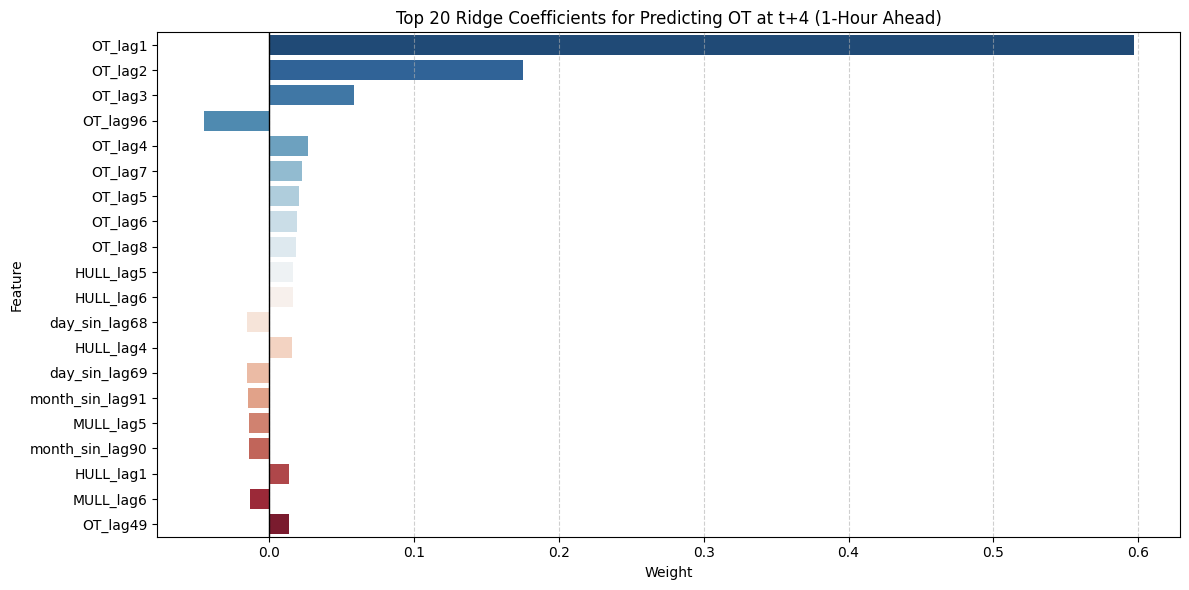

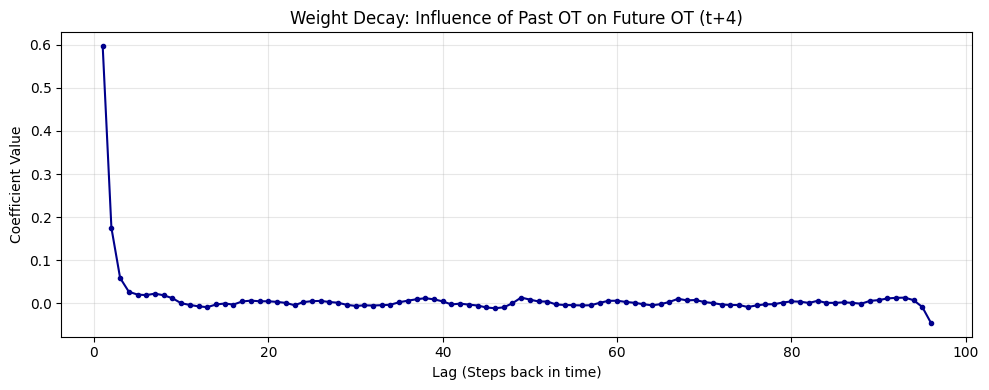

Most influential feature for OT at t+4: OT_lag1 (weight=0.5968)


In [14]:
# Ridge Coefficient-Based Local Interpretability Analysis

# Construct feature labels aligned with the flattened temporal-feature dimension
all_feature_names = base_cols + time_cols
feature_labels = []
for lag in range(CONFIG['seq_len'], 0, -1):
    for col in all_feature_names:
        feature_labels.append(f"{col}_lag{lag}")

# Isolate the specific coefficient vector for 'OT' at prediction horizon t+4
target_step = 4
ot_idx = target_cols.index('OT')
target_flattened_idx = (target_step - 1) * target_dim + ot_idx
weights = ridge_model.coef_[target_flattened_idx]

# Map and rank features by absolute magnitude to identify top predictors
importance_df = pd.DataFrame({'Feature': feature_labels, 'Weight': weights})
importance_df['AbsWeight'] = importance_df['Weight'].abs()
top_features = importance_df.sort_values('AbsWeight', ascending=False).head(20)

# Visualize global feature saliency via coefficient magnitudes
plt.figure(figsize=(12, 6))
sns.barplot(data=top_features, x='Weight', y='Feature', hue='Feature', palette='RdBu_r', dodge=False, legend=False)
plt.title(f'Top 20 Ridge Coefficients for Predicting OT at t+{target_step} (1-Hour Ahead)')
plt.axvline(0, color='black', lw=1)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(out_path('figures', 'ridge_feature_importance_top20.png'), dpi=150)
plt.show()

# Quantify temporal decay: analyze the influence of past OT lags on future predictions
ot_lags = [i for i, label in enumerate(feature_labels) if label.startswith('OT_lag')]
ot_weights = weights[ot_lags]

plt.figure(figsize=(10, 4))
plt.plot(range(len(ot_weights), 0, -1), ot_weights, marker='.', color='darkblue')
plt.title('Weight Decay: Influence of Past OT on Future OT (t+4)')
plt.xlabel('Lag (Steps back in time)')
plt.ylabel('Coefficient Value')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(out_path('figures', 'ridge_ot_weight_decay.png'), dpi=150)
plt.show()

# Extract and report the primary exogenous or endogenous driver
print(
    f"Most influential feature for OT at t+{target_step}: "
    f"{top_features.iloc[0]['Feature']} (weight={top_features.iloc[0]['Weight']:.4f})"
 )

In [15]:
print('\n=== KNN final training (M setting) ===')

# Initialize non-parametric K-Nearest Neighbors regressor with optimized hyperparameters
knn_cfg = BEST_CONFIG['M-96']['KNN']
knn_best = KNeighborsRegressor(
    n_neighbors=int(knn_cfg['n_neighbors']),
    weights=knn_cfg['weights'],
    leaf_size=int(knn_cfg['leaf_size']),
    n_jobs=-1
)

# Indexing training samples
t0 = time.perf_counter()
knn_best.fit(X_train_flat, y_train)
knn_train_time = time.perf_counter() - t0

# Execute inference and quantify performance in normalized feature space
knn_pred_scaled = knn_best.predict(X_test_flat)
knn_metrics_norm, knn_true_scaled, knn_pred_scaled = regression_metrics(y_test, knn_pred_scaled)

# Map predictions back to physical scale for real-world error analysis
knn_true_inv = inverse_scale_flat_targets(knn_true_scaled, y_scaler, target_dim)
knn_pred_inv = inverse_scale_flat_targets(knn_pred_scaled, y_scaler, target_dim)
knn_metrics_inv, _, _ = regression_metrics(knn_true_inv, knn_pred_inv)

# Compute variable-specific metrics and store disaggregated reports
knn_pv_norm = per_variable_metrics(knn_true_scaled, knn_pred_scaled, target_cols, pred_len, target_dim)
knn_pv_inv = per_variable_metrics(knn_true_inv, knn_pred_inv, target_cols, pred_len, target_dim)
per_variable_reports['KNN_M96'] = {'normalized': knn_pv_norm, 'inverse': knn_pv_inv}

# Profile instance-based inference latency (warmup + Monte Carlo trials)
knn_lat_mean, knn_lat_med, knn_lat_p95 = measure_ml_latency(
    knn_best, X_test_flat[:1], CONFIG['latency_warmup'], CONFIG['latency_runs']
)
latency_records['KNN_M96'] = {'mean_ms': knn_lat_mean, 'median_ms': knn_lat_med, 'p95_ms': knn_lat_p95}

print(f'KNN Train Time: {knn_train_time:.2f}s')
print('KNN metrics [normalized]:', knn_metrics_norm)
print('KNN metrics [inverse-scaled]:', knn_metrics_inv)
print('KNN per-variable metrics [normalized]:')
display(knn_pv_norm)
print('KNN per-variable metrics [inverse-scaled]:')
display(knn_pv_inv)

# Aggregate results with metadata for model comparative benchmarking
results.append({
    'Task': 'M-96',
    'Model': 'KNN',
    **knn_metrics_norm,
    'TrainTimeSec': knn_train_time,
    'LatencyMeanMs': knn_lat_mean,
    'LatencyP95Ms': knn_lat_p95,
    'Explainability': 'Low (Instance-based)'
})



=== KNN final training (M setting) ===
KNN Train Time: 0.06s
KNN metrics [normalized]: {'MAE': 0.653378963470459, 'MSE': 0.7606022953987122, 'RMSE': np.float64(0.8721251603976989)}
KNN metrics [inverse-scaled]: {'MAE': 2.516817808151245, 'MSE': 16.819347381591797, 'RMSE': np.float64(4.101139766161572)}
KNN per-variable metrics [normalized]:


,Variable,MAE,MSE,RMSE
0,LULL,0.423007,0.265808,0.515566
1,MUFL,0.649378,1.016156,1.008046
2,HULL,0.650720,0.683504,0.826743
3,MULL,0.651246,0.665621,0.815856
4,OT,0.684726,0.555250,0.745151
5,HUFL,0.687811,0.977228,0.988549
6,LUFL,0.826765,1.160649,1.077334


KNN per-variable metrics [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.267528,0.106319,0.326065
1,LUFL,0.860293,1.256696,1.121024
2,MULL,1.253101,2.464391,1.569838
3,HULL,1.359774,2.984599,1.727599
4,MUFL,3.583946,30.951944,5.563447
5,HUFL,4.012066,33.250168,5.766296
6,OT,6.281017,46.721313,6.835299


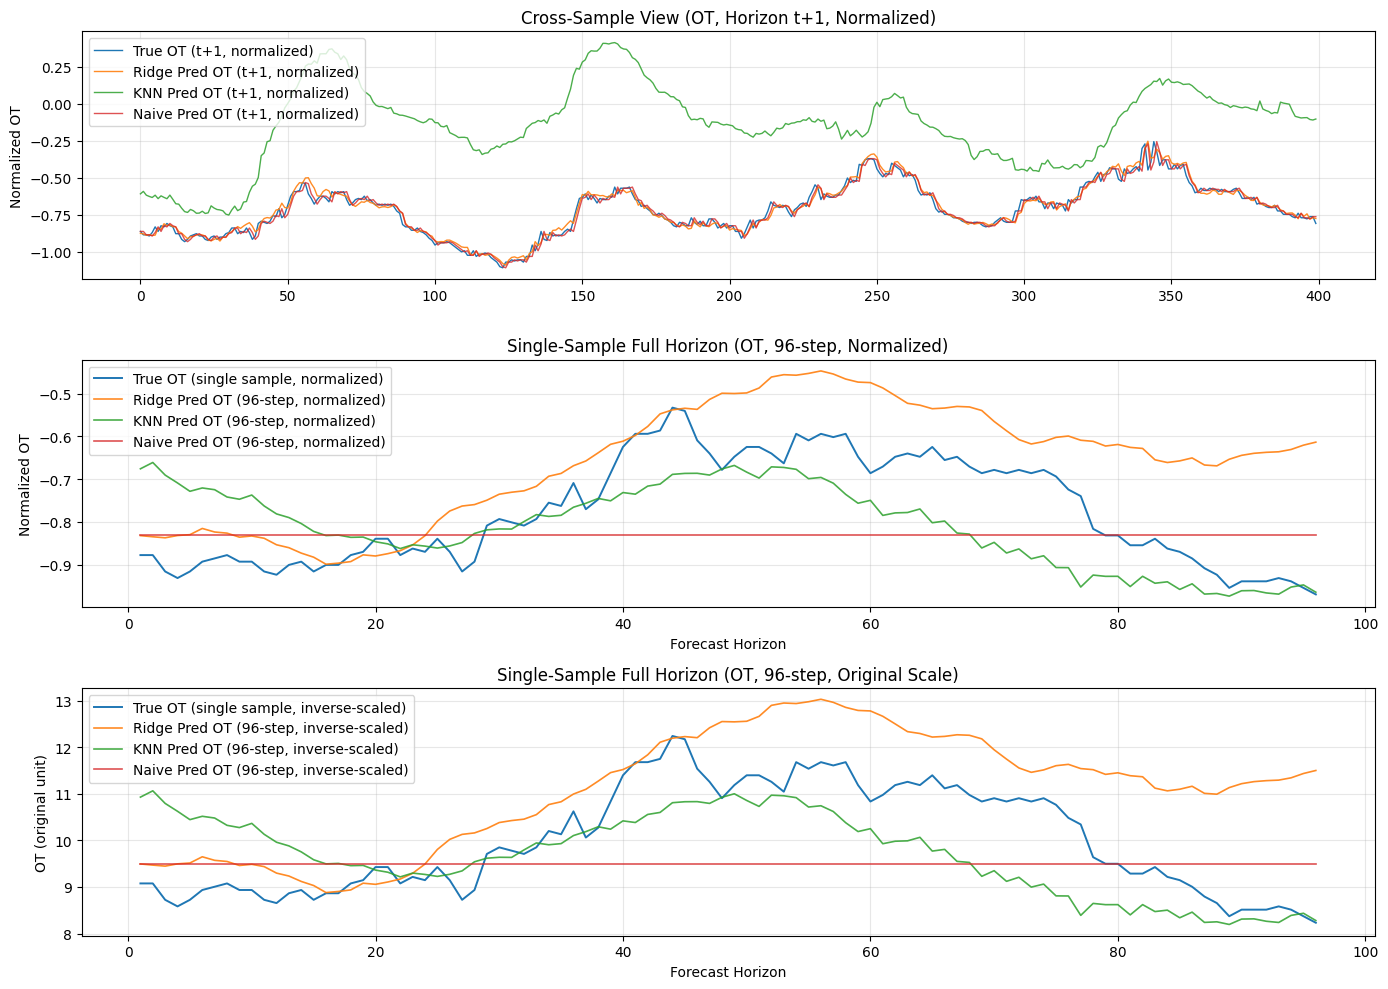

Visual sample index for 96-step plot: 12
Figure written: outputs/figures/ridge_visual_evidence_ot_h1_and_96step.png


In [16]:
# Visual Diagnostics: Multi-Model Baseline Comparison (OT Channel)
if 'ridge_pred_scaled' not in globals():
    print('Ridge outputs are unavailable. Execute the Ridge training cell first.')
else:
    n_show = min(400, len(ridge_true_scaled))
    ot_idx = target_cols.index('OT')
    ot_h1_col = 0 * target_dim + ot_idx  

    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)

    # Cross-sample validation at t+1: Assessing global bias and variance across the test set
    axes[0].plot(ridge_true_scaled[:n_show, ot_h1_col], label='True OT (t+1, normalized)', linewidth=1.0)
    axes[0].plot(ridge_pred_scaled[:n_show, ot_h1_col], label='Ridge Pred OT (t+1, normalized)', linewidth=1.0, alpha=0.9)
    if 'knn_pred_scaled' in globals():
        axes[0].plot(knn_pred_scaled[:n_show, ot_h1_col], label='KNN Pred OT (t+1, normalized)', linewidth=1.0, alpha=0.85)
    axes[0].plot(naive_pred_scaled_norm[:n_show, ot_h1_col], label='Naive Pred OT (t+1, normalized)', linewidth=1.0, alpha=0.8)
    axes[0].set_title('Cross-Sample View (OT, Horizon t+1, Normalized)')
    axes[0].set_ylabel('Normalized OT')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Multi-step error trajectory (Normalized): Analyzing forecast decay over a 96-step horizon
    sample_idx = min(12, len(ridge_true_scaled) - 1)
    
    # Extract temporal sequences for a representative sample
    true_seq_norm = ridge_true_scaled[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    ridge_seq_norm = ridge_pred_scaled[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    if 'knn_pred_scaled' in globals():
        knn_seq_norm = knn_pred_scaled[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    naive_seq_norm = naive_pred_scaled_norm[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    h = np.arange(1, pred_len + 1)

    axes[1].plot(h, true_seq_norm, label='True OT (single sample, normalized)', linewidth=1.4)
    axes[1].plot(h, ridge_seq_norm, label='Ridge Pred OT (96-step, normalized)', linewidth=1.2, alpha=0.9)
    if 'knn_pred_scaled' in globals():
        axes[1].plot(h, knn_seq_norm, label='KNN Pred OT (96-step, normalized)', linewidth=1.2, alpha=0.85)
    axes[1].plot(h, naive_seq_norm, label='Naive Pred OT (96-step, normalized)', linewidth=1.2, alpha=0.8)
    axes[1].set_title('Single-Sample Full Horizon (OT, 96-step, Normalized)')
    axes[1].set_xlabel('Forecast Horizon')
    axes[1].set_ylabel('Normalized OT')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Physical scale validation: Benchmarking forecasting performance in original units
    true_seq_inv = ridge_true_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    ridge_seq_inv = ridge_pred_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    if 'knn_pred_inv' in globals():
        knn_seq_inv = knn_pred_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    naive_seq_inv = naive_pred_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]

    axes[2].plot(h, true_seq_inv, label='True OT (single sample, inverse-scaled)', linewidth=1.4)
    axes[2].plot(h, ridge_seq_inv, label='Ridge Pred OT (96-step, inverse-scaled)', linewidth=1.2, alpha=0.9)
    if 'knn_pred_inv' in globals():
        axes[2].plot(h, knn_seq_inv, label='KNN Pred OT (96-step, inverse-scaled)', linewidth=1.2, alpha=0.85)
    axes[2].plot(h, naive_seq_inv, label='Naive Pred OT (96-step, inverse-scaled)', linewidth=1.2, alpha=0.8)
    axes[2].set_title('Single-Sample Full Horizon (OT, 96-step, Original Scale)')
    axes[2].set_xlabel('Forecast Horizon')
    axes[2].set_ylabel('OT (original unit)')
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(out_path('figures', 'ridge_visual_evidence_ot_h1_and_96step.png'), dpi=150)
    plt.show()

    print(f'Visual sample index for 96-step plot: {sample_idx}')
    print('Figure written: outputs/figures/ridge_visual_evidence_ot_h1_and_96step.png')

# 5. Deep Learning Models

This section defines and trains the deep learning candidates used in this notebook, including LSTM, GRU, Informer, DLinear, TCN, MLP, and iTransformer.
It also standardizes DL data loading, optimization, and evaluation logic for fair M-96 comparison.

In [17]:
# Scalar regression performance metrics for point-wise evaluation.

if 'mean_absolute_error' not in globals():
    from sklearn.metrics import mean_absolute_error, mean_squared_error
if 'regression_metrics' not in globals():
    def regression_metrics(y_true_scaled, y_pred_scaled):
        """Computes scalar regression metrics for a flattened target tensor."""
        y_true = np.asarray(y_true_scaled, dtype=np.float32)
        y_pred = np.asarray(y_pred_scaled, dtype=np.float32)
        mae = mean_absolute_error(y_true.reshape(-1), y_pred.reshape(-1))
        mse = mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1))
        rmse = np.sqrt(mse)
        return {'MAE': mae, 'MSE': mse, 'RMSE': rmse}, y_true, y_pred
if 'inverse_scale_flat_targets' not in globals():
    def inverse_scale_flat_targets(y_flat_scaled, scaler, target_dim):
        """Applies inverse scaling to a flattened target array using the provided scaler."""
        y_flat_scaled = np.asarray(y_flat_scaled, dtype=np.float32)
        n = y_flat_scaled.shape[0]
        y_2d = y_flat_scaled.reshape(-1, target_dim)
        y_inv_2d = scaler.inverse_transform(y_2d)
        return y_inv_2d.reshape(n, -1).astype(np.float32)
if 'per_variable_metrics' not in globals():
    def per_variable_metrics(y_true_flat, y_pred_flat, var_names, pred_len, target_dim):
        """Computes per-variable regression metrics by reshaping flattened targets."""
        y_true_3d = np.asarray(y_true_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)
        y_pred_3d = np.asarray(y_pred_flat, dtype=np.float32).reshape(-1, pred_len, target_dim)
        rows = []
        for i, var in enumerate(var_names):
            yt = y_true_3d[:, :, i].reshape(-1)
            yp = y_pred_3d[:, :, i].reshape(-1)
            mae = mean_absolute_error(yt, yp)
            mse = mean_squared_error(yt, yp)
            rmse = np.sqrt(mse)
            rows.append({'Variable': var, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})
        return pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)

def build_loaders(X_tr, y_tr, X_va, y_va, X_te, y_te, batch_size, run_device):
    """Constructs PyTorch DataLoaders for training, validation, and testing."""
    train_ds = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr))
    val_ds = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    test_ds = TensorDataset(torch.from_numpy(X_te), torch.from_numpy(y_te))

    use_workers = CONFIG['dl_num_workers'] if CONFIG['dl_num_workers'] > 0 else 0
    use_pin = bool(CONFIG['dl_pin_memory']) and (run_device.type == 'cuda')
    common = dict(batch_size=batch_size, num_workers=use_workers, pin_memory=use_pin)
    if use_workers > 0:
        common['persistent_workers'] = True

    train_loader = DataLoader(train_ds, shuffle=True, **common)
    val_loader = DataLoader(val_ds, shuffle=False, **common)
    test_loader = DataLoader(test_ds, shuffle=False, **common)
    return train_loader, val_loader, test_loader


class SequenceRegressor(nn.Module):
    """LSTM or GRU baseline with optional input and head dropout."""
    def __init__(self, input_dim, output_dim, hidden_dim=128, num_layers=2, dropout=0.2, input_dropout=0.0, head_dropout=0.0, rnn_type='lstm'):
        super().__init__()
        rnn_cls = nn.LSTM if rnn_type.lower() == 'lstm' else nn.GRU
        self.input_drop = nn.Dropout(float(input_dropout))
        self.rnn = rnn_cls(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.norm = nn.LayerNorm(hidden_dim)
        self.head_drop = nn.Dropout(float(head_dropout))
        self.head = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.rnn(self.input_drop(x))
        last = self.norm(out[:, -1, :])
        last = self.head_drop(last)
        return self.head(last)


class PositionalEncoding(nn.Module):
    """Positional encoding for transformer models."""
    def __init__(self, d_model, max_len=2048):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class InformerRegressor(nn.Module):
    """Informer regressor with optional pooling of last K time steps."""
    def __init__(self, input_dim, output_dim, d_model=128, nhead=8, num_layers=2, dropout=0.1, ff_dim=256, pool_last_k=24):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.pool_last_k = pool_last_k
        self.head = nn.Linear(d_model, output_dim)

    def forward(self, x):
        z = self.input_proj(x)
        z = self.pos_encoder(z)
        z = self.encoder(z)
        k = min(self.pool_last_k, z.size(1))
        return self.head(z[:, -k:, :].mean(dim=1))


class DLinearRegressor(nn.Module):
    """DLinear regressor with moving average seasonal decomposition."""
    def __init__(self, seq_len, pred_len, target_dim, ma_window=25):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.target_dim = target_dim
        self.avg = nn.AvgPool1d(kernel_size=ma_window, stride=1, padding=ma_window // 2)
        self.seasonal_linear = nn.Linear(seq_len, pred_len)
        self.trend_linear = nn.Linear(seq_len, pred_len)

    def forward(self, x):
        x_t = x[:, :, :self.target_dim]
        trend = self.avg(x_t.transpose(1, 2))[:, :, :x_t.size(1)].transpose(1, 2)
        seasonal = x_t - trend
        seasonal_out = self.seasonal_linear(seasonal.transpose(1, 2))
        trend_out = self.trend_linear(trend.transpose(1, 2))
        out = (seasonal_out + trend_out).transpose(1, 2)
        return out.reshape(out.size(0), -1)


class TemporalBlock(nn.Module):
    """Temporal convolution block for TCN."""
    def __init__(self, in_ch, out_ch, kernel_size=3, dilation=1, dropout=0.1):
        super().__init__()
        pad = (kernel_size - 1) * dilation
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.act = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Conv1d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else None

    def _trim(self, x, ref_len):
        return x[:, :, :ref_len]

    def forward(self, x):
        ref_len = x.size(-1)
        z = self._trim(self.conv1(x), ref_len)
        z = self.drop(self.act(z))
        z = self._trim(self.conv2(z), ref_len)
        z = self.drop(self.act(z))
        res = x if self.proj is None else self.proj(x)
        return z + res


class TCNRegressor(nn.Module):
    """TCN regressor with residual connections and dilated convolutions."""
    def __init__(self, input_dim, output_dim, channels=128, levels=4, kernel_size=3, dropout=0.1):
        super().__init__()
        blocks = []
        in_ch = input_dim
        for i in range(levels):
            blocks.append(TemporalBlock(in_ch, channels, kernel_size=kernel_size, dilation=2 ** i, dropout=dropout))
            in_ch = channels
        self.backbone = nn.Sequential(*blocks)
        self.head = nn.Linear(channels, output_dim)

    def forward(self, x):
        z = self.backbone(x.transpose(1, 2))
        return self.head(z[:, :, -1])


class MLPRegressor(nn.Module):
    """MLP regressor with GELU activations and dropout."""
    def __init__(self, input_dim, seq_len, output_dim, hidden=384, layers=3, dropout=0.1):
        super().__init__()
        in_dim = input_dim * seq_len
        blocks = []
        for _ in range(layers):
            blocks.extend([nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(dropout)])
            in_dim = hidden
        blocks.append(nn.Linear(in_dim, output_dim))
        self.net = nn.Sequential(*blocks)

    def forward(self, x):
        return self.net(x.reshape(x.size(0), -1))


class iTransformerRegressor(nn.Module):
    """iTransformer regressor with tokenized input and global averaging."""
    def __init__(self, input_dim, seq_len, output_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1):
        super().__init__()
        self.token_proj = nn.Linear(seq_len, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, output_dim)

    def forward(self, x):
        tokens = x.transpose(1, 2)
        z = self.token_proj(tokens)
        z = self.encoder(z)
        return self.head(z.mean(dim=1))


def build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
    """Factory function to build a specified deep learning model instance."""
    n = model_name.lower()
    if n == 'lstm':
        return SequenceRegressor(
            input_dim=input_dim, output_dim=output_dim, hidden_dim=int(params['hidden']),
            num_layers=int(params['layers']), dropout=float(params['dropout']),
            input_dropout=float(params.get('input_dropout', CONFIG.get('lstm_gru_input_dropout', 0.0))),
            head_dropout=float(params.get('head_dropout', CONFIG.get('lstm_gru_head_dropout', 0.0))),
            rnn_type='lstm'
        )
    if n == 'gru':
        return SequenceRegressor(
            input_dim=input_dim, output_dim=output_dim, hidden_dim=int(params['hidden']),
            num_layers=int(params['layers']), dropout=float(params['dropout']),
            input_dropout=float(params.get('input_dropout', CONFIG.get('lstm_gru_input_dropout', 0.0))),
            head_dropout=float(params.get('head_dropout', CONFIG.get('lstm_gru_head_dropout', 0.0))),
            rnn_type='gru'
        )
    if n == 'informer':
        return InformerRegressor(
            input_dim=input_dim, output_dim=output_dim, d_model=int(params['d_model']), nhead=int(params['nhead']),
            num_layers=int(params['layers']), dropout=float(params['dropout']), ff_dim=int(params['ffn']),
            pool_last_k=int(params['pool_last_k'])
        )
    if n == 'dlinear':
        return DLinearRegressor(
            seq_len=seq_len, pred_len=pred_len, target_dim=target_dim, ma_window=int(params['ma_window'])
        )
    if n == 'tcn':
        return TCNRegressor(
            input_dim=input_dim, output_dim=output_dim, channels=int(params['channels']),
            levels=int(params['levels']), kernel_size=int(params['kernel_size']), dropout=float(params['dropout'])
        )
    if n == 'mlp':
        return MLPRegressor(
            input_dim=input_dim, seq_len=seq_len, output_dim=output_dim, hidden=int(params['hidden']),
            layers=int(params['layers']), dropout=float(params['dropout'])
        )
    if n == 'itransformer':
        return iTransformerRegressor(
            input_dim=input_dim, seq_len=seq_len, output_dim=output_dim, d_model=int(params['d_model']),
            nhead=int(params['nhead']), num_layers=int(params['layers']), ff_dim=int(params['ffn']),
            dropout=float(params['dropout'])
        )
    raise ValueError(f'Unsupported model: {model_name}')


def get_default_dl_params(model_name):
    """Returns default hyperparameters for a given model name."""
    n = model_name.lower()
    if n == 'lstm':
        return {'hidden': CONFIG['lstm_hidden'], 'layers': CONFIG['lstm_layers'], 'dropout': CONFIG['dropout'], 'input_dropout': CONFIG.get('lstm_gru_input_dropout', 0.0), 'head_dropout': CONFIG.get('lstm_gru_head_dropout', 0.0), 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'gru':
        return {'hidden': CONFIG['gru_hidden'], 'layers': CONFIG['gru_layers'], 'dropout': CONFIG['dropout'], 'input_dropout': CONFIG.get('lstm_gru_input_dropout', 0.0), 'head_dropout': CONFIG.get('lstm_gru_head_dropout', 0.0), 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'informer':
        return {'d_model': CONFIG['informer_d_model'], 'nhead': CONFIG['informer_nhead'], 'layers': CONFIG['informer_layers'], 'ffn': CONFIG['informer_ffn'], 'dropout': CONFIG['informer_dropout'], 'pool_last_k': CONFIG['informer_pool_last_k'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'dlinear':
        return {'ma_window': CONFIG['dlinear_ma_window'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'tcn':
        return {'channels': CONFIG['tcn_channels'], 'levels': CONFIG['tcn_levels'], 'kernel_size': CONFIG['tcn_kernel_size'], 'dropout': CONFIG['dropout'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'mlp':
        return {'hidden': CONFIG['mlp_hidden'], 'layers': CONFIG['mlp_layers'], 'dropout': CONFIG['dropout'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    if n == 'itransformer':
        return {'d_model': CONFIG['itransformer_d_model'], 'nhead': CONFIG['itransformer_nhead'], 'layers': CONFIG['itransformer_layers'], 'ffn': CONFIG['itransformer_ffn'], 'dropout': CONFIG['itransformer_dropout'], 'lr': CONFIG['learning_rate'], 'epochs': CONFIG['epochs'], 'patience': CONFIG['patience']}
    raise ValueError(f'Unsupported model: {model_name}')


def evaluate_loader(model, loader, criterion, run_device):
    """Evaluates a model on a data loader."""
    model.eval()
    losses, preds, trues = [], [], []
    amp_enabled = CONFIG['use_amp'] and (run_device.type == 'cuda')
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(run_device, non_blocking=True)
            yb = yb.to(run_device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=amp_enabled):
                yhat = model(xb)
                loss = criterion(yhat, yb)
            losses.append(float(loss.item()))
            preds.append(yhat.detach().cpu().numpy())
            trues.append(yb.detach().cpu().numpy())
    return float(np.mean(losses)), np.concatenate(preds, axis=0), np.concatenate(trues, axis=0)


def train_with_early_stopping(model, train_loader_local, val_loader_local, model_name, epochs, patience, lr, run_device, max_train_seconds=None):
    """Trains a model with early stopping based on validation loss, using mixed precision if enabled."""
    criterion = nn.SmoothL1Loss(beta=0.5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.6, patience=2, min_lr=1e-5)
    amp_enabled = CONFIG['use_amp'] and (run_device.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)

    best_val = float('inf')
    best_state = None
    patience_counter = 0
    train_losses, val_losses = [], []
    cap_seconds = CONFIG['max_train_seconds_per_model'] if max_train_seconds is None else max_train_seconds

    t0 = time.perf_counter()
    for epoch in range(int(epochs)):
        if (time.perf_counter() - t0) > cap_seconds:
            print(f'{model_name}: runtime guard triggered at epoch {epoch + 1}')
            break

        model.train()
        epoch_losses = []
        for xb, yb in train_loader_local:
            xb = xb.to(run_device, non_blocking=True)
            yb = yb.to(run_device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=amp_enabled):
                pred = model(xb)
                loss = criterion(pred, yb)
            if not torch.isfinite(loss):
                print(f'{model_name}: non-finite loss, training stopped')
                break
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=CONFIG['grad_clip_max_norm'])
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(float(loss.item()))

        if len(epoch_losses) == 0:
            break

        train_loss = float(np.mean(epoch_losses))
        val_loss, _, _ = evaluate_loader(model, val_loader_local, criterion, run_device)
        scheduler.step(val_loss)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'{model_name} epoch {epoch + 1:02d}: train={train_loss:.5f}, val={val_loss:.5f}')
        if patience_counter >= int(patience):
            print(f'{model_name}: early stopping at epoch {epoch + 1}')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - t0
    return model, train_losses, val_losses, train_time


def measure_dl_latency(model, x_single, run_device, warmup=30, runs=200):
    """Measures the average, median, and 95th percentile latency of a model inference."""
    model.eval()
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(x_single)
        times = []
        for _ in range(runs):
            if run_device.type == 'cuda':
                torch.cuda.synchronize()
            t1 = time.perf_counter()
            _ = model(x_single)
            if run_device.type == 'cuda':
                torch.cuda.synchronize()
            t2 = time.perf_counter()
            times.append((t2 - t1) * 1000.0)
    return float(np.mean(times)), float(np.median(times)), float(np.percentile(times, 95))


def train_with_device_fallback(model_name, params, X_tr, y_tr, X_va, y_va, X_te, y_te, input_dim, output_dim, seq_len, pred_len, target_dim, max_train_seconds=None):
    """Trains a model with a fallback mechanism, and returns the trained model along with training history and test loader."""
    run_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    for try_idx in [0, 1]:
        try:
            train_loader_local, val_loader_local, test_loader_local = build_loaders(
                X_tr, y_tr, X_va, y_va, X_te, y_te, CONFIG['batch_size'], run_device
            )
            model = build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim).to(run_device)
            model, tr_losses, va_losses, train_time = train_with_early_stopping(
                model=model,
                train_loader_local=train_loader_local,
                val_loader_local=val_loader_local,
                model_name=model_name,
                epochs=params.get('epochs', CONFIG['epochs']),
                patience=params.get('patience', CONFIG['patience']),
                lr=params.get('lr', CONFIG['learning_rate']),
                run_device=run_device,
                max_train_seconds=max_train_seconds
            )
            return model, tr_losses, va_losses, train_time, test_loader_local, run_device
        except RuntimeError as e:
            is_cuda_error = (run_device.type == 'cuda') and ('cuda' in str(e).lower() or 'cudnn' in str(e).lower())
            if (try_idx == 0) and is_cuda_error:
                print(f'{model_name}: CUDA execution failed; fallback to CPU')
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                run_device = torch.device('cpu')
                continue
            raise

In [18]:
# Minimal corrective overrides for Informer/iTransformer and DL training policy.

class DropPath(nn.Module):
    """DropPath class used in Informer and iTransformer."""
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = float(drop_prob)

    def forward(self, x):
        if self.drop_prob <= 0.0 or (not self.training):
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor = random_tensor.floor()
        return x * random_tensor / keep_prob


class InformerRegressor(nn.Module):
    """Informer regressor with RevIN and optional DropPath support."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1, droppath=0.0):
        super().__init__()
        self.target_dim = int(target_dim)
        self.value_proj = nn.Linear(input_dim, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.droppath = DropPath(droppath)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(d_model, pred_len * self.target_dim)

    def forward(self, x):
        z = self.value_proj(x) + self.pos_emb[:, :x.size(1), :]
        z = self.encoder(z)
        z = self.droppath(z)
        z = self.dropout(z[:, -1, :])
        return self.head(z)


class iTransformerRegressor(nn.Module):
    """iTransformer regressor with RevIN and optional DropPath support."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1, droppath=0.0):
        super().__init__()
        self.target_dim = int(target_dim)
        self.pred_len = int(pred_len)
        self.token_proj = nn.Linear(seq_len, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=ff_dim, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.droppath = DropPath(droppath)
        self.head = nn.Linear(d_model, pred_len)

    def forward(self, x):
        tokens = x.transpose(1, 2)
        z = self.encoder(self.token_proj(tokens))
        z = self.droppath(z)
        z_target = z[:, :self.target_dim, :]
        pred = self.head(z_target)
        pred = pred.transpose(1, 2).contiguous()
        return pred.reshape(pred.size(0), -1)


class RevINWrapper(nn.Module):
    """Reversible Instance Normalization wrapper for all models."""
    def __init__(self, base_model, target_dim, pred_len, eps=1e-5):
        super().__init__()
        self.base_model = base_model
        self.target_dim = int(target_dim)
        self.pred_len = int(pred_len)
        self.eps = float(eps)

    def forward(self, x):
        x_t = x[:, :, :self.target_dim]
        mean = x_t.mean(dim=1, keepdim=True)
        std = x_t.std(dim=1, keepdim=True, unbiased=False).clamp_min(self.eps)
        x_norm = x.clone()
        x_norm[:, :, :self.target_dim] = (x_t - mean) / std

        pred_norm = self.base_model(x_norm)
        b = pred_norm.size(0)
        pred_3d = pred_norm.reshape(b, self.pred_len, self.target_dim)
        pred = pred_3d * std + mean
        return pred.reshape(b, -1)


def _resolve_base_fn(current_fn, storage_key):
    """Resolves the base function for overrides, preventing infinite recursion."""
    cached = globals().get(storage_key)
    if callable(cached) and not getattr(cached, '_is_dl_override', False):
        return cached
    if callable(current_fn) and not getattr(current_fn, '_is_dl_override', False):
        globals()[storage_key] = current_fn
        return current_fn
    if callable(cached):
        return cached
    raise RuntimeError(f'Missing base function for {storage_key}. Run previous DL definition cells first.')


_BASE_BUILD_DL_MODEL = _resolve_base_fn(globals().get('build_dl_model'), '_BASE_BUILD_DL_MODEL')


def build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
    """Builds a deep learning model with optional RevIN wrapper."""
    n = model_name.lower()
    if n == 'informer':
        model = InformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params['d_model']),
            nhead=int(params['nhead']),
            num_layers=int(params['layers']),
            ff_dim=int(params['ffn']),
            dropout=float(params['dropout']),
            droppath=float(params.get('droppath', CONFIG.get('informer_droppath', 0.0)))
        )
    elif n == 'itransformer':
        model = iTransformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params['d_model']),
            nhead=int(params['nhead']),
            num_layers=int(params['layers']),
            ff_dim=int(params['ffn']),
            dropout=float(params['dropout']),
            droppath=float(params.get('droppath', CONFIG.get('itransformer_droppath', 0.0)))
        )
    else:
        model = _BASE_BUILD_DL_MODEL(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim)

    if bool(CONFIG.get('dl_use_revin_all_models', True)):
        model = RevINWrapper(model, target_dim=target_dim, pred_len=pred_len)
    return model


build_dl_model._is_dl_override = True


_BASE_GET_DEFAULT_DL_PARAMS = _resolve_base_fn(globals().get('get_default_dl_params'), '_BASE_GET_DEFAULT_DL_PARAMS')


def get_default_dl_params(model_name):
    """Returns default hyperparameters for a given model name, including Informer/iTransformer overrides."""
    n = model_name.lower()
    if n == 'informer':
        return {
            'd_model': CONFIG['informer_d_model'],
            'nhead': CONFIG['informer_nhead'],
            'layers': CONFIG['informer_layers'],
            'ffn': CONFIG['informer_ffn'],
            'dropout': CONFIG['informer_dropout'],
            'pool_last_k': CONFIG['informer_pool_last_k'],
            'droppath': float(CONFIG.get('informer_droppath', 0.0)),
            'lr': CONFIG['learning_rate'],
            'epochs': CONFIG['epochs'],
            'patience': CONFIG['patience']
        }
    if n == 'itransformer':
        return {
            'd_model': CONFIG['itransformer_d_model'],
            'nhead': CONFIG['itransformer_nhead'],
            'layers': CONFIG['itransformer_layers'],
            'ffn': CONFIG['itransformer_ffn'],
            'dropout': CONFIG['itransformer_dropout'],
            'droppath': float(CONFIG.get('itransformer_droppath', 0.0)),
            'lr': CONFIG['learning_rate'],
            'epochs': CONFIG['epochs'],
            'patience': CONFIG['patience']
        }
    return _BASE_GET_DEFAULT_DL_PARAMS(model_name)


get_default_dl_params._is_dl_override = True


def train_with_early_stopping(model, train_loader_local, val_loader_local, model_name, epochs, patience, lr, run_device, max_train_seconds=None, trial=None):
    """Trains a model with early stopping based on validation loss, using mixed precision if enabled, and supports Optuna pruning."""
    criterion = nn.SmoothL1Loss(beta=0.5)
    eval_criterion = criterion
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])

    scheduler_mode = str(CONFIG.get('dl_scheduler_mode', 'plateau')).lower()
    if scheduler_mode == 'cosine':
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=max(1, int(epochs)),
            eta_min=float(CONFIG.get('dl_cosine_min_lr', 1e-5))
        )
    else:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='min',
            factor=float(CONFIG.get('dl_plateau_factor', 0.6)),
            patience=int(CONFIG.get('dl_plateau_patience', 2)),
            min_lr=float(CONFIG.get('dl_min_lr', 1e-5))
        )

    amp_enabled = bool(CONFIG['use_amp']) and (run_device.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)

    best_val = float('inf')
    best_state = None
    patience_counter = 0
    train_losses, val_losses = [], []
    cap_seconds = CONFIG['max_train_seconds_per_model'] if max_train_seconds is None else max_train_seconds
    min_delta = float(CONFIG.get('dl_earlystop_min_delta', 0.0))

    t0 = time.perf_counter()
    for epoch in range(int(epochs)):
        if (time.perf_counter() - t0) > cap_seconds:
            print(f'{model_name}: runtime guard triggered at epoch {epoch + 1}')
            break

        model.train()
        epoch_losses = []
        for xb, yb in train_loader_local:
            xb = xb.to(run_device, non_blocking=True)
            yb = yb.to(run_device, non_blocking=True)

            noise_std = float(CONFIG.get('dl_input_noise_std', 0.0))
            if noise_std > 0.0:
                xb = xb + torch.randn_like(xb) * noise_std

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=amp_enabled):
                pred = model(xb)
                loss = criterion(pred, yb)

            if not torch.isfinite(loss):
                print(f'{model_name}: non-finite loss, training stopped')
                break

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=CONFIG['grad_clip_max_norm'])
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(float(loss.item()))

        if len(epoch_losses) == 0:
            break

        train_loss = float(np.mean(epoch_losses))
        val_loss, _, _ = evaluate_loader(model, val_loader_local, eval_criterion, run_device)

        if scheduler_mode == 'cosine':
            scheduler.step()
        else:
            scheduler.step(val_loss)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < (best_val - min_delta):
            best_val = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'{model_name} epoch {epoch + 1:02d}: train={train_loss:.5f}, val={val_loss:.5f}')

        if trial is not None:
            trial.report(val_loss, step=epoch)
            if trial.should_prune():
                raise optuna.TrialPruned(f'{model_name} pruned at epoch {epoch + 1}')

        if patience_counter >= int(patience):
            print(f'{model_name}: early stopping at epoch {epoch + 1}')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - t0
    return model, train_losses, val_losses, train_time


train_with_early_stopping._is_dl_override = True


def train_with_device_fallback(model_name, params, X_tr, y_tr, X_va, y_va, X_te, y_te, input_dim, output_dim, seq_len, pred_len, target_dim, max_train_seconds=None, trial=None):
    """Trains a model with a fallback mechanism for device selection, and returns the trained model along with training history and test loader. Supports Optuna pruning."""
    run_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    for try_idx in [0, 1]:
        try:
            train_loader_local, val_loader_local, test_loader_local = build_loaders(
                X_tr, y_tr, X_va, y_va, X_te, y_te, CONFIG['batch_size'], run_device
            )
            model = build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim).to(run_device)
            model, tr_losses, va_losses, train_time = train_with_early_stopping(
                model=model,
                train_loader_local=train_loader_local,
                val_loader_local=val_loader_local,
                model_name=model_name,
                epochs=params.get('epochs', CONFIG['epochs']),
                patience=params.get('patience', CONFIG['patience']),
                lr=params.get('lr', CONFIG['learning_rate']),
                run_device=run_device,
                max_train_seconds=max_train_seconds,
                trial=trial
            )
            return model, tr_losses, va_losses, train_time, test_loader_local, run_device
        except RuntimeError as e:
            is_cuda_error = (run_device.type == 'cuda') and ('cuda' in str(e).lower() or 'cudnn' in str(e).lower())
            if (try_idx == 0) and is_cuda_error:
                print(f'{model_name}: CUDA execution failed; fallback to CPU')
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                run_device = torch.device('cpu')
                continue
            raise


train_with_device_fallback._is_dl_override = True

In [19]:
# Official model loader and build_dl_model override from THUML Time-Series-Library, with error handling and status tracking.

from pathlib import Path
from types import SimpleNamespace
import importlib
import subprocess
import sys

if 'DL_PIPELINE_STATUS' not in globals():
    DL_PIPELINE_STATUS = {}

if 'DL_PIPELINE_ISSUES' not in globals():
    DL_PIPELINE_ISSUES = []


def _set_stage(stage, ok, message, **extra):
    """Sets the status of a pipeline stage."""
    rec = {'ok': bool(ok), 'message': str(message)}
    rec.update(extra)
    DL_PIPELINE_STATUS[stage] = rec
    tag = 'OK' if ok else 'FAIL'
    print(f'[DL-STAGE][{tag}] {stage}: {message}')


def _warn(msg):
    """Issues a warning message."""
    print(f'[DL-WARN] {msg}')


def _ensure_thuml_tsl_repo():
    """Ensures the THUML Time-Series-Library repository is available."""
    repo_dir = Path('outputs') / '_thuml_tsl'
    repo_root = repo_dir / 'Time-Series-Library'
    repo_dir.mkdir(parents=True, exist_ok=True)

    if repo_root.exists():
        return repo_root

    print('Cloning THUML Time-Series-Library ...')
    try:
        subprocess.run(
            ['git', 'clone', 'https://github.com/thuml/Time-Series-Library.git', str(repo_root)],
            check=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            text=True
        )
        return repo_root
    except Exception as e:
        _warn(f'THUML repo clone failed: {e}. Official models will fallback to local.')
        return None


THUML_REPO_ROOT = _ensure_thuml_tsl_repo()
THUML_MODEL_MODULES = {
    'informer': 'Informer',
    'itransformer': 'iTransformer',
    'dlinear': 'DLinear'
}
THUML_MODEL_STATUS = {}
THUML_IMPORT_ERRORS = {}
THUMLInformer = None
THUMLiTransformer = None
THUMLDLinear = None
OFFICIAL_MODEL_ERRORS = {}

if THUML_REPO_ROOT is not None:
    if str(THUML_REPO_ROOT) not in sys.path:
        sys.path.insert(0, str(THUML_REPO_ROOT))

    for model_key, module_name in THUML_MODEL_MODULES.items():
        try:
            module = importlib.import_module(f'models.{module_name}')
            THUML_MODEL_STATUS[model_key] = True
            if model_key == 'informer':
                THUMLInformer = module
            elif model_key == 'itransformer':
                THUMLiTransformer = module
            elif model_key == 'dlinear':
                THUMLDLinear = module
            print(f'[DL-INFO] Official {module_name} loaded.')
        except Exception as e:
            THUML_MODEL_STATUS[model_key] = False
            THUML_IMPORT_ERRORS[model_key] = e
            _warn(f'Official {module_name} import failed: {e}')
else:
    for model_key in THUML_MODEL_MODULES:
        THUML_MODEL_STATUS[model_key] = False
        THUML_IMPORT_ERRORS[model_key] = RuntimeError('THUML repo unavailable')

try:
    from torchvision.ops import MLP as OFFICIAL_MLP_CLASS
    THUML_MODEL_STATUS['mlp'] = True
except Exception as e:
    THUML_MODEL_STATUS['mlp'] = False
    OFFICIAL_MODEL_ERRORS['mlp'] = e
    OFFICIAL_MLP_CLASS = None

try:
    from pytorch_tcn import TCN as OFFICIAL_TCN_CLASS
    THUML_MODEL_STATUS['tcn'] = True
except Exception as e1:
    try:
        from tcn import TCN as OFFICIAL_TCN_CLASS
        THUML_MODEL_STATUS['tcn'] = True
    except Exception as e2:
        THUML_MODEL_STATUS['tcn'] = False
        OFFICIAL_MODEL_ERRORS['tcn'] = e1
        OFFICIAL_TCN_CLASS = None
        _warn(f'Official TCN import failed: {e1}; fallback import failed: {e2}')

THUML_AVAILABLE = any(
    THUML_MODEL_STATUS.get(k, False) for k in ['informer', 'itransformer', 'dlinear', 'tcn', 'mlp']
)

if THUML_REPO_ROOT is None:
    _set_stage('model_pull', False, 'THUML repository clone/load failed')
else:
    _set_stage('model_pull', True, f'THUML repository ready at {THUML_REPO_ROOT}')

_official_check_list = ['informer', 'itransformer', 'dlinear', 'tcn', 'mlp']
_ok_cnt = int(sum(1 for _k in _official_check_list if THUML_MODEL_STATUS.get(_k, False)))
_tot_cnt = int(len(_official_check_list))
if _ok_cnt > 0:
    _set_stage('model_check', True, f'Official models available: {_ok_cnt}/{_tot_cnt}', available=_ok_cnt, total=_tot_cnt)
else:
    _set_stage('model_check', False, 'No official model could be imported, all will fallback to local', available=_ok_cnt, total=_tot_cnt)


class RevINWrapper(nn.Module):
    """Reversible Instance Normalization for accurate time-series forecasting."""
    def __init__(self, base_model, target_dim, pred_len, eps=1e-5):
        super().__init__()
        self.base_model = base_model
        self.target_dim = int(target_dim)
        self.pred_len = int(pred_len)
        self.eps = float(eps)

    def forward(self, x):
        x_t = x[:, :, :self.target_dim]
        mean = x_t.mean(dim=1, keepdim=True)
        std = x_t.std(dim=1, keepdim=True, unbiased=False).clamp_min(self.eps)
        x_norm = x.clone()
        x_norm[:, :, :self.target_dim] = (x_t - mean) / std

        pred_norm = self.base_model(x_norm)
        b = pred_norm.size(0)
        pred_3d = pred_norm.reshape(b, self.pred_len, self.target_dim)
        pred = pred_3d * std + mean
        return pred.reshape(b, -1)


class OfficialInformerRegressor(nn.Module):
    """Official Informer model from THUML."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=4, num_layers=2, ff_dim=256, dropout=0.1, label_len=48, time_feat_dim=5):
        super().__init__()
        cfg = SimpleNamespace(
            task_name='long_term_forecast',
            seq_len=int(seq_len),
            label_len=int(label_len),
            pred_len=int(pred_len),
            enc_in=int(input_dim),
            dec_in=int(input_dim),
            c_out=int(target_dim),
            d_model=int(d_model),
            n_heads=int(nhead),
            e_layers=int(num_layers),
            d_layers=1,
            d_ff=int(ff_dim),
            factor=3,
            dropout=float(dropout),
            embed='timeF',
            freq='t',
            activation='gelu',
            distil=True,
            num_class=1
        )
        self.model = THUMLInformer.Model(cfg)
        self.seq_len = int(seq_len)
        self.label_len = int(label_len)
        self.pred_len = int(pred_len)
        self.input_dim = int(input_dim)
        self.time_feat_dim = int(time_feat_dim)

    def forward(self, x):
        b = x.size(0)
        if x.size(-1) >= self.time_feat_dim:
            x_mark_enc = x[:, :, -self.time_feat_dim:]
        else:
            x_mark_enc = torch.zeros((b, self.seq_len, self.time_feat_dim), device=x.device, dtype=x.dtype)
            x_mark_enc[:, :, :x.size(-1)] = x

        x_dec = torch.zeros((b, self.label_len + self.pred_len, self.input_dim), device=x.device, dtype=x.dtype)
        x_dec[:, :self.label_len, :] = x[:, -self.label_len:, :]

        x_mark_dec = torch.zeros((b, self.label_len + self.pred_len, self.time_feat_dim), device=x.device, dtype=x.dtype)
        x_mark_dec[:, :self.label_len, :] = x_mark_enc[:, -self.label_len:, :]
        x_mark_dec[:, self.label_len:, :] = x_mark_enc[:, -1:, :].expand(-1, self.pred_len, -1)

        y = self.model(x, x_mark_enc, x_dec, x_mark_dec)
        return y.reshape(b, -1)


class OfficialITransformerRegressor(nn.Module):
    """Official iTransformer model from THUML."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=128, nhead=8, num_layers=2, ff_dim=256, dropout=0.1, time_feat_dim=5):
        super().__init__()
        self.target_dim = int(target_dim)
        cfg = SimpleNamespace(
            task_name='long_term_forecast',
            seq_len=int(seq_len),
            label_len=int(seq_len // 2),
            pred_len=int(pred_len),
            enc_in=int(input_dim),
            dec_in=int(input_dim),
            c_out=int(target_dim),
            d_model=int(d_model),
            n_heads=int(nhead),
            e_layers=int(num_layers),
            d_layers=1,
            d_ff=int(ff_dim),
            factor=3,
            dropout=float(dropout),
            embed='timeF',
            freq='t',
            activation='gelu',
            num_class=1
        )
        self.model = THUMLiTransformer.Model(cfg)
        self.seq_len = int(seq_len)
        self.pred_len = int(pred_len)
        self.time_feat_dim = int(time_feat_dim)

    def forward(self, x):
        b = x.size(0)
        if x.size(-1) >= self.time_feat_dim:
            x_mark = x[:, :, -self.time_feat_dim:]
        else:
            x_mark = torch.zeros((b, self.seq_len, self.time_feat_dim), device=x.device, dtype=x.dtype)
            x_mark[:, :, :x.size(-1)] = x

        x_dec = torch.zeros((b, self.pred_len, x.size(-1)), device=x.device, dtype=x.dtype)
        x_mark_dec = x_mark[:, -1:, :].expand(-1, self.pred_len, -1).contiguous()
        y = self.model(x, x_mark, x_dec, x_mark_dec)
        y = y[:, :, :self.target_dim]
        return y.reshape(b, -1)


class OfficialDLinearRegressor(nn.Module):
    """Official DLinear model from THUML."""
    def __init__(self, input_dim, seq_len, pred_len, target_dim, ma_window=25):
        super().__init__()
        self.target_dim = int(target_dim)
        cfg = SimpleNamespace(
            task_name='long_term_forecast',
            seq_len=int(seq_len),
            pred_len=int(pred_len),
            enc_in=int(input_dim),
            moving_avg=int(ma_window),
            num_class=1
        )
        cfg.individual = False
        self.model = THUMLDLinear.Model(cfg)

    def forward(self, x):
        b = x.size(0)
        y = self.model(x, None, None, None)
        y = y[:, :, :self.target_dim]
        return y.reshape(b, -1)


class OfficialTCNRegressor(nn.Module):
    """Official TCN model from pytorch-tcn."""
    def __init__(self, input_dim, output_dim, channels=96, levels=3, kernel_size=3, dropout=0.3):
        super().__init__()
        num_channels = [int(channels)] * int(levels)
        self.tcn = OFFICIAL_TCN_CLASS(num_inputs=int(input_dim), num_channels=num_channels, kernel_size=int(kernel_size), dropout=float(dropout))
        self.head = nn.Linear(int(channels), int(output_dim))

    def forward(self, x):
        z = self.tcn(x.transpose(1, 2))
        feat = z[:, :, -1] if z.ndim == 3 else z
        return self.head(feat)


class OfficialMLPRegressor(nn.Module):
    """MLP regressor using torchvision's MLP class."""
    def __init__(self, input_dim, seq_len, output_dim, hidden=256, layers=2, dropout=0.3):
        super().__init__()
        in_dim = int(input_dim) * int(seq_len)
        hidden = int(hidden)
        depth = max(1, int(layers))
        self.backbone = OFFICIAL_MLP_CLASS(
            in_channels=in_dim,
            hidden_channels=[hidden] * depth,
            norm_layer=None,
            activation_layer=nn.GELU,
            dropout=float(dropout)
        )
        self.head = nn.Linear(hidden, int(output_dim))

    def forward(self, x):
        z = self.backbone(x.reshape(x.size(0), -1))
        return self.head(z)


_BASE_BUILD_DL_MODEL = globals().get('_BASE_BUILD_DL_MODEL', None)
if not callable(_BASE_BUILD_DL_MODEL):
    _BASE_BUILD_DL_MODEL = globals().get('build_dl_model')

_WARNED_MODEL_FALLBACK = set()

def build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
    """Build deep learning model with support for official THUML implementations."""
    n = str(model_name).lower()
    use_official = False

    if n == 'informer' and THUML_MODEL_STATUS.get('informer', False):
        use_official = True
        model = OfficialInformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params.get('d_model', 128)),
            nhead=int(params.get('nhead', 4)),
            num_layers=int(params.get('layers', 2)),
            ff_dim=int(params.get('ffn', 256)),
            dropout=float(params.get('dropout', 0.1)),
            label_len=int(CONFIG.get('label_len', 48)),
            time_feat_dim=int(CONFIG.get('thuml_time_feat_dim', 5))
        )
    elif n == 'itransformer' and THUML_MODEL_STATUS.get('itransformer', False):
        use_official = True
        model = OfficialITransformerRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            d_model=int(params.get('d_model', 128)),
            nhead=int(params.get('nhead', 8)),
            num_layers=int(params.get('layers', 2)),
            ff_dim=int(params.get('ffn', 256)),
            dropout=float(params.get('dropout', 0.1)),
            time_feat_dim=int(CONFIG.get('thuml_time_feat_dim', 5))
        )
    elif n == 'dlinear' and THUML_MODEL_STATUS.get('dlinear', False):
        use_official = True
        model = OfficialDLinearRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            pred_len=pred_len,
            target_dim=target_dim,
            ma_window=int(params.get('ma_window', CONFIG.get('dlinear_ma_window', 25)))
        )
    elif n == 'tcn' and THUML_MODEL_STATUS.get('tcn', False) and (OFFICIAL_TCN_CLASS is not None):
        use_official = True
        model = OfficialTCNRegressor(
            input_dim=input_dim,
            output_dim=output_dim,
            channels=int(params.get('channels', 96)),
            levels=int(params.get('levels', 3)),
            kernel_size=int(params.get('kernel_size', 3)),
            dropout=float(params.get('dropout', 0.30))
        )
    elif n == 'mlp' and THUML_MODEL_STATUS.get('mlp', False) and (OFFICIAL_MLP_CLASS is not None):
        use_official = True
        model = OfficialMLPRegressor(
            input_dim=input_dim,
            seq_len=seq_len,
            output_dim=output_dim,
            hidden=int(params.get('hidden', 256)),
            layers=int(params.get('layers', 2)),
            dropout=float(params.get('dropout', 0.30))
        )
    else:
        official_names = {'informer', 'itransformer', 'dlinear', 'tcn', 'mlp'}
        if n in official_names and n not in _WARNED_MODEL_FALLBACK:
            err = THUML_IMPORT_ERRORS.get(n, OFFICIAL_MODEL_ERRORS.get(n))
            if err is not None:
                _warn(f'{model_name}: official implementation unavailable, fallback to local. Reason: {err}')
            else:
                _warn(f'{model_name}: official implementation unavailable, fallback to local.')
            _WARNED_MODEL_FALLBACK.add(n)
        model = _BASE_BUILD_DL_MODEL(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim)

    if use_official:
        print(f'[DL-INFO] {model_name}: using official THUML implementation.')

    use_revin = bool(CONFIG.get('dl_use_revin_all_models', True))
    if use_revin:
        model = RevINWrapper(model, target_dim=target_dim, pred_len=pred_len)
    return model


build_dl_model._is_dl_override = True
print('DL official override is active before tuning/training.')
print('Official model status:', {k: ('ok' if v else 'missing') for k, v in THUML_MODEL_STATUS.items()})

[DL-INFO] Official Informer loaded.
[DL-INFO] Official iTransformer loaded.
[DL-INFO] Official DLinear loaded.
[DL-STAGE][OK] model_pull: THUML repository ready at outputs\_thuml_tsl\Time-Series-Library
[DL-STAGE][OK] model_check: Official models available: 5/5
DL official override is active before tuning/training.
Official model status: {'informer': 'ok', 'itransformer': 'ok', 'dlinear': 'ok', 'mlp': 'ok', 'tcn': 'ok'}


In [20]:
# DL tuning phase with checks for prerequisites, runtime setup, and Optuna integration.

print('DL tuning started.')
if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
    _set_stage('bayes_opt', False, 'running')

required_vars = [
    'CONFIG', 'OPTUNA_AVAILABLE', 'X_train', 'y_train', 'X_val', 'y_val',
    'target_dim', 'BEST_CONFIG', 'OUTPUT_DIR'
]
required_funcs = ['get_default_dl_params', 'train_with_device_fallback', 'evaluate_loader']

missing_vars = [k for k in required_vars if k not in globals()]
missing_funcs = [k for k in required_funcs if k not in globals()]

if missing_vars or missing_funcs:
    print('Missing prerequisites for DL tuning. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_funcs:
        print('Missing functions:', missing_funcs)
    if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
        _set_stage('bayes_opt', False, 'Missing prerequisites', missing_vars=missing_vars, missing_funcs=missing_funcs)
else:
    if 'results' not in globals():
        results = []
    if 'latency_records' not in globals():
        latency_records = {}
    if 'per_variable_reports' not in globals():
        per_variable_reports = {}

    active_dl_models = [
        m for m in CONFIG['dl_models']
        if m in ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer']
    ]
    print(f'Active DL models: {active_dl_models}')

    def safe_default_params(model_name):
        """Safely get default parameters for a model, with fallback to empty dict."""
        try:
            p = get_default_dl_params(model_name)
            return p.copy() if isinstance(p, dict) else {}
        except Exception as e:
            print(f'{model_name}: get_default_dl_params failed, fallback to empty defaults: {e}')
            return {}

    DL_BEST_CONFIG = {'DL-M96': {m: safe_default_params(m) for m in active_dl_models}}
    BEST_CONFIG['DL-M96'] = DL_BEST_CONFIG['DL-M96']

    tune_mode = str(CONFIG.get('dl_tune_mode', 'auto')).lower()
    if tune_mode not in ['auto', 'on', 'off']:
        print(f'Unknown dl_tune_mode={tune_mode}, fallback to auto.')
        tune_mode = 'auto'

    if tune_mode == 'off':
        tune_requested = False
    elif tune_mode == 'on':
        tune_requested = True
    else:
        tune_requested = bool(CONFIG.get('dl_tune_enabled', True))

    can_tune = True
    tune_block_reasons = []

    if not tune_requested:
        can_tune = False
        if tune_mode == 'off':
            tune_block_reasons.append('dl_tune_mode=off')
        else:
            tune_block_reasons.append('tuning disabled by config')
    if not bool(OPTUNA_AVAILABLE):
        can_tune = False
        tune_block_reasons.append('Optuna unavailable')
    if len(active_dl_models) == 0:
        can_tune = False
        tune_block_reasons.append('No active DL models')
    if not callable(globals().get('train_with_device_fallback', None)):
        can_tune = False
        tune_block_reasons.append('train_with_device_fallback unavailable')

    if can_tune:
        _orig_batch_size = CONFIG.get('batch_size', 160)
        _orig_dl_workers = CONFIG.get('dl_num_workers', 2)
        _orig_dl_pin = CONFIG.get('dl_pin_memory', True)

        CONFIG['batch_size'] = int(CONFIG.get('dl_tune_batch_size', max(_orig_batch_size, 192)))
        CONFIG['dl_num_workers'] = int(CONFIG.get('dl_tune_num_workers', 0))
        CONFIG['dl_pin_memory'] = bool(CONFIG.get('dl_tune_pin_memory', _orig_dl_pin))
        print(f'Tuning runtime setup: batch_size={CONFIG["batch_size"]}, workers={CONFIG["dl_num_workers"]}')

        pruner_name = str(CONFIG.get('dl_tune_pruner', 'hyperband')).lower()
        if pruner_name == 'hyperband':
            pruner = optuna.pruners.HyperbandPruner(
                min_resource=int(CONFIG.get('dl_tune_hb_min_resource', 3)),
                reduction_factor=int(CONFIG.get('dl_tune_hb_reduction_factor', 3))
            )
        elif pruner_name == 'median':
            pruner = optuna.pruners.MedianPruner(n_warmup_steps=2)
        else:
            pruner = optuna.pruners.NopPruner()

        rng = np.random.RandomState(CONFIG['seed'])
        n_train = len(X_train)
        n_val = len(X_val)
        k_train = min(CONFIG['dl_tune_max_samples'], max(256, int(n_train * CONFIG['dl_tune_subsample_frac'])))
        k_val = min(max(128, int(n_val * CONFIG['dl_tune_subsample_frac'])), n_val)
        tr_idx = rng.choice(n_train, size=k_train, replace=False)
        va_idx = rng.choice(n_val, size=k_val, replace=False)

        X_tr_tune = X_train[tr_idx]
        y_tr_tune = y_train[tr_idx]
        X_va_tune = X_val[va_idx]
        y_va_tune = y_val[va_idx]

        input_dim = X_train.shape[-1]
        output_dim = y_train.shape[1]

        noise_scan = CONFIG.get('dl_input_noise_scan', [0.01, 0.02, 0.05])
        if not isinstance(noise_scan, (list, tuple)) or len(noise_scan) == 0:
            noise_scan = [0.01, 0.02, 0.05]

        def suggest_dl_params(model_name, trial):
            """Suggests hyperparameters for a given model using Optuna trial, with safe defaults and model-specific search spaces."""
            p = safe_default_params(model_name)
            n = model_name.lower()

            if n in ['lstm', 'gru']:
                p['hidden'] = trial.suggest_categorical('hidden', [80, 96])
                p['layers'] = trial.suggest_categorical('layers', [1])
                p['dropout'] = trial.suggest_float('dropout', 0.38, 0.58)
                p['input_dropout'] = trial.suggest_float('input_dropout', 0.20, 0.35)
                p['head_dropout'] = trial.suggest_float('head_dropout', 0.25, 0.42)
                p['lr'] = trial.suggest_float('lr', 7e-5, 3.2e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 6, 8)
                p['patience'] = trial.suggest_int('patience', 2, 2)
            elif n == 'informer':
                p['d_model'] = trial.suggest_categorical('d_model', [96])
                p['nhead'] = trial.suggest_categorical('nhead', [4])
                p['layers'] = trial.suggest_categorical('layers', [1])
                p['ffn'] = trial.suggest_categorical('ffn', [128])
                p['dropout'] = trial.suggest_float('dropout', 0.42, 0.56)
                p['droppath'] = trial.suggest_float('droppath', 0.10, 0.20)
                p['pool_last_k'] = trial.suggest_categorical('pool_last_k', [16])
                p['lr'] = trial.suggest_float('lr', 8e-5, 1.6e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 6, 8)
                p['patience'] = trial.suggest_int('patience', 2, 2)
            elif n == 'dlinear':
                p['ma_window'] = trial.suggest_categorical('ma_window', [37])
                p['lr'] = trial.suggest_float('lr', 2e-4, 7e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 5, 7)
                p['patience'] = trial.suggest_int('patience', 2, 3)
            elif n == 'tcn':
                p['channels'] = trial.suggest_categorical('channels', [64, 80])
                p['levels'] = trial.suggest_categorical('levels', [2])
                p['kernel_size'] = trial.suggest_categorical('kernel_size', [3, 5])
                p['dropout'] = trial.suggest_float('dropout', 0.30, 0.50)
                p['lr'] = trial.suggest_float('lr', 1.5e-4, 6e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 8, 10)
                p['patience'] = trial.suggest_int('patience', 2, 3)
            elif n == 'mlp':
                p['hidden'] = trial.suggest_categorical('hidden', [192, 256])
                p['layers'] = trial.suggest_int('layers', 1, 2)
                p['dropout'] = trial.suggest_float('dropout', 0.28, 0.48)
                p['lr'] = trial.suggest_float('lr', 2e-4, 8e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 6, 8)
                p['patience'] = trial.suggest_int('patience', 2, 3)
            elif n == 'itransformer':
                p['d_model'] = trial.suggest_categorical('d_model', [96])
                p['nhead'] = trial.suggest_categorical('nhead', [4])
                p['layers'] = trial.suggest_categorical('layers', [1, 2])
                p['ffn'] = trial.suggest_categorical('ffn', [160, 192])
                p['dropout'] = trial.suggest_float('dropout', 0.22, 0.38)
                p['droppath'] = trial.suggest_float('droppath', 0.05, 0.20)
                p['lr'] = trial.suggest_float('lr', 1e-4, 4e-4, log=True)
                p['epochs'] = trial.suggest_int('epochs', 7, 10)
                p['patience'] = trial.suggest_int('patience', 3, 4)
            p['input_noise_std'] = trial.suggest_categorical('input_noise_std', [float(x) for x in noise_scan])
            return p

        def objective_dl(trial, model_name):
            """Objective function for Optuna tuning of a specific model."""
            params = suggest_dl_params(model_name, trial)
            _orig_noise_std = float(CONFIG.get('dl_input_noise_std', 0.0))
            trial_cap = min(int(CONFIG.get('dl_tune_max_train_seconds_per_trial', 120)), int(CONFIG.get('max_train_seconds_per_model', 720)))
            CONFIG['dl_input_noise_std'] = float(params.get('input_noise_std', _orig_noise_std))
            try:
                model, _, _, _, tune_val_loader, run_device = train_with_device_fallback(
                    model_name=model_name,
                    params=params,
                    X_tr=X_tr_tune, y_tr=y_tr_tune,
                    X_va=X_va_tune, y_va=y_va_tune,
                    X_te=X_va_tune, y_te=y_va_tune,
                    input_dim=input_dim, output_dim=output_dim,
                    seq_len=CONFIG['seq_len'], pred_len=CONFIG['pred_len'], target_dim=target_dim,
                    max_train_seconds=trial_cap,
                    trial=trial
                )
                if str(CONFIG.get('dl_loss', 'mse')).lower() == 'mse':
                    criterion = nn.MSELoss()
                else:
                    criterion = nn.SmoothL1Loss(beta=0.5)
                val_loss, _, _ = evaluate_loader(model, tune_val_loader, criterion, run_device)
                return float(val_loss)
            finally:
                CONFIG['dl_input_noise_std'] = _orig_noise_std

        optuna.logging.set_verbosity(optuna.logging.WARNING)
        try:
            for model_name in active_dl_models:
                print(f'Tuning {model_name} ...')
                tuned = safe_default_params(model_name)

                # Create an independent pruner for each model
                if pruner_name == 'hyperband':
                    model_pruner = optuna.pruners.HyperbandPruner(
                        min_resource=int(CONFIG.get('dl_tune_hb_min_resource', 3)),
                        reduction_factor=int(CONFIG.get('dl_tune_hb_reduction_factor', 3))
                    )
                elif pruner_name == 'median':
                    model_pruner = optuna.pruners.MedianPruner(n_warmup_steps=2)
                else:
                    model_pruner = optuna.pruners.NopPruner()
                try:
                    study = optuna.create_study(
                        direction='minimize',
                        sampler=optuna.samplers.TPESampler(seed=CONFIG['seed']),
                        pruner=model_pruner
                    )

                    study.optimize(
                        lambda trial: objective_dl(trial, model_name),
                        n_trials=CONFIG['dl_tune_trials'],
                        timeout=CONFIG['dl_tune_timeout_sec'],
                        gc_after_trial=True
                    )

                    completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
                    if len(completed_trials) > 0:
                        tuned.update(study.best_params)
                        print(f'{model_name} best val objective: {study.best_value:.6f}')
                    else:
                        print(f'{model_name}: all trials pruned/failed, fallback to default params.')
                except Exception as e:
                    print(f'{model_name}: tuning failed, keep default params. err={e}')

                DL_BEST_CONFIG['DL-M96'][model_name] = tuned
        finally:
            CONFIG['batch_size'] = _orig_batch_size
            CONFIG['dl_num_workers'] = _orig_dl_workers
            CONFIG['dl_pin_memory'] = _orig_dl_pin
            print('Tuning runtime setup restored to training defaults.')
    else:
        print('DL tuning is unavailable; use default params directly.')
        if len(tune_block_reasons) > 0:
            print('Reasons:', tune_block_reasons)

    BEST_CONFIG['DL-M96'] = DL_BEST_CONFIG['DL-M96']
    with open(out_path('configs', 'best_config_dl.json'), 'w', encoding='utf-8') as f:
        json.dump(DL_BEST_CONFIG, f, indent=2)
    print('DL configuration file written: outputs/configs/best_config_dl.json')
    if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
        if can_tune:
            _set_stage('bayes_opt', True, f'Bayesian optimization step finished for {len(active_dl_models)} models')
        else:
            _set_stage('bayes_opt', False, 'Bayesian optimization skipped, defaults used', reasons=tune_block_reasons)

DL tuning started.
[DL-STAGE][FAIL] bayes_opt: running
Active DL models: ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer']
Tuning runtime setup: batch_size=512, workers=2
Tuning LSTM ...
LSTM epoch 01: train=0.36183, val=0.46143
LSTM epoch 05: train=0.32550, val=0.40591
LSTM epoch 01: train=0.36249, val=0.45998
LSTM epoch 05: train=0.32459, val=0.40263
LSTM epoch 01: train=0.36793, val=0.45987
LSTM epoch 05: train=0.30200, val=0.35509
LSTM epoch 01: train=0.37261, val=0.44845
LSTM epoch 05: train=0.31080, val=0.34932
LSTM epoch 01: train=0.36129, val=0.44745
LSTM epoch 05: train=0.29508, val=0.34349
LSTM epoch 01: train=0.36517, val=0.44080
LSTM epoch 05: train=0.29520, val=0.33299
LSTM epoch 01: train=0.36739, val=0.46145
LSTM epoch 05: train=0.31723, val=0.38417
LSTM epoch 01: train=0.37096, val=0.45447
LSTM epoch 05: train=0.31134, val=0.35859
LSTM best val objective: 0.541364
Tuning GRU ...
GRU epoch 01: train=0.36643, val=0.47206
GRU epoch 05: train=0.32954, val

In [21]:
# DL final training phase with checks for prerequisites, model building, training, evaluation, and result recording.

print('DL final training setup.')
if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
    _set_stage('train', False, 'running setup')
    _set_stage('evaluate', False, 'pending')

required_vars = [
    'CONFIG', 'X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test',
    'target_dim', 'target_cols', 'pred_len', 'y_scaler', 'BEST_CONFIG',
    'OUTPUT_DIR', 'active_dl_models'
 ]
required_funcs = [
    'get_default_dl_params', 'train_with_device_fallback', 'evaluate_loader',
    'regression_metrics', 'inverse_scale_flat_targets', 'per_variable_metrics',
    'measure_dl_latency'
 ]

missing_vars = [k for k in required_vars if k not in globals()]
missing_funcs = [k for k in required_funcs if k not in globals()]

if missing_vars or missing_funcs:
    print('Missing prerequisites for DL final training. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_funcs:
        print('Missing functions:', missing_funcs)
    if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
        _set_stage('train', False, 'Missing prerequisites', missing_vars=missing_vars, missing_funcs=missing_funcs)
        _set_stage('evaluate', False, 'Skipped because training prerequisites are missing')
else:
    if 'results' not in globals():
        results = []
    if 'latency_records' not in globals():
        latency_records = {}
    if 'per_variable_reports' not in globals():
        per_variable_reports = {}
    if 'dl_histories' not in globals():
        dl_histories = {}
    if 'dl_outputs' not in globals():
        dl_outputs = {}
    if 'dl_models_trained' not in globals():
        dl_models_trained = {}

    input_dim = X_train.shape[-1]
    output_dim = y_train.shape[1]

    def _posthoc_dl_adjustments(model_name, params):
        """Applies post-hoc adjustments to DL model parameters for improved stability and performance."""
        p = dict(params)
        n = model_name.lower()
        if n in ['lstm', 'gru']:
            p['dropout'] = max(float(p.get('dropout', CONFIG.get('dropout', 0.30))), 0.44)
            p['input_dropout'] = max(float(p.get('input_dropout', CONFIG.get('lstm_gru_input_dropout', 0.25))), float(CONFIG.get('lstm_gru_input_dropout', 0.25)))
            p['head_dropout'] = max(float(p.get('head_dropout', CONFIG.get('lstm_gru_head_dropout', 0.30))), float(CONFIG.get('lstm_gru_head_dropout', 0.30)))
            p['hidden'] = min(int(p.get('hidden', 96)), 96)
            p['layers'] = 1
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 3.2e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'informer':
            p['d_model'] = min(max(int(p.get('d_model', CONFIG.get('informer_d_model', 128))), 96), 128)
            p['nhead'] = 4
            p['layers'] = 1
            p['ffn'] = min(max(int(p.get('ffn', CONFIG.get('informer_ffn', 256))), 128), 160)
            p['dropout'] = min(max(float(p.get('dropout', CONFIG.get('informer_dropout', 0.15))), 0.30), 0.45)
            p['droppath'] = min(max(float(p.get('droppath', CONFIG.get('informer_droppath', 0.03))), 0.10), 0.25)
            p['pool_last_k'] = min(max(int(p.get('pool_last_k', CONFIG.get('informer_pool_last_k', 24))), 16), 24)
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 5.0e-5)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 2)
            p['weight_decay'] = max(float(p.get('weight_decay', CONFIG.get('weight_decay', 3e-3))), 8e-3)
        elif n == 'dlinear':
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 3e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'tcn':
            p['dropout'] = max(float(p.get('dropout', CONFIG.get('dropout', 0.30))), 0.30)
            p['levels'] = min(int(p.get('levels', CONFIG.get('tcn_levels', 3))), 2)
            p['channels'] = min(int(p.get('channels', CONFIG.get('tcn_channels', 96))), 80)
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 6e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'mlp':
            p['dropout'] = max(float(p.get('dropout', CONFIG.get('dropout', 0.30))), 0.32)
            p['hidden'] = min(int(p.get('hidden', CONFIG.get('mlp_hidden', 256))), 256)
            p['layers'] = min(int(p.get('layers', CONFIG.get('mlp_layers', 2))), 2)
            p['lr'] = min(float(p.get('lr', CONFIG.get('learning_rate', 1e-3))), 8e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
        elif n == 'itransformer':
            p['d_model'] = 96
            p['nhead'] = 4
            p['layers'] = min(int(p.get('layers', 1)), 2)
            p['ffn'] = min(int(p.get('ffn', 192)), 192)
            p['lr'] = min(float(p.get('lr', CONFIG.get('itransformer_learning_rate', 3e-4))), 3.2e-4)
            p['epochs'] = max(int(CONFIG.get('dl_full_epochs', 20)), int(p.get('epochs', CONFIG['epochs'])))
            p['patience'] = min(max(int(p.get('patience', CONFIG['patience'])), 2), 3)
            p['dropout'] = min(max(float(p.get('dropout', CONFIG.get('itransformer_dropout', 0.25))), 0.26), 0.38)
            p['droppath'] = min(max(float(p.get('droppath', CONFIG.get('itransformer_droppath', 0.10))), 0.05), 0.20)
        p['input_noise_std'] = float(p.get('input_noise_std', CONFIG.get('dl_input_noise_std', 0.01)))
        if n == 'informer':
            p['input_noise_std'] = min(max(p['input_noise_std'], 0.07), 0.10)
        else:
            p['input_noise_std'] = min(max(p['input_noise_std'], 0.02), 0.08)
        return p

    def _export_compatibility_aliases(model_name, model, pred_scaled, true_scaled, pred_inv, true_inv):
        """Exports compatibility aliases for trained DL models."""
        key = model_name.lower().replace('-', '_')
        globals()[f'{key}_model'] = model
        globals()[f'{key}_pred_scaled'] = pred_scaled
        globals()[f'{key}_true_scaled'] = true_scaled
        globals()[f'{key}_pred_inv'] = pred_inv
        globals()[f'{key}_true_inv'] = true_inv

        if model_name == 'Informer':
            globals()['inf_pred_scaled'] = pred_scaled
            globals()['inf_true_scaled'] = true_scaled
            globals()['inf_pred_inv'] = pred_inv
            globals()['inf_true_inv'] = true_inv

    def train_single_dl_model(model_name):
        """Trains a single DL model with full configuration, handles errors, and records results."""
        if model_name not in active_dl_models:
            print(f'{model_name} is disabled in CONFIG["dl_models"].')
            return

        base_params = BEST_CONFIG.get('DL-M96', {}).get(model_name, get_default_dl_params(model_name))
        params = _posthoc_dl_adjustments(model_name, base_params)
        print(f'Training {model_name}')
        print(f'Config: {params}')

        _orig_noise_std = float(CONFIG.get('dl_input_noise_std', 0.0))
        _orig_weight_decay = float(CONFIG.get('weight_decay', 3e-3))
        CONFIG['dl_input_noise_std'] = float(params.get('input_noise_std', _orig_noise_std))
        if str(model_name).lower() == 'informer':
            CONFIG['weight_decay'] = float(params.get('weight_decay', max(_orig_weight_decay, 8e-3)))

        try:
            model, tr_losses, va_losses, train_time, test_loader_local, run_device = train_with_device_fallback(
                model_name=model_name,
                params=params,
                X_tr=X_train, y_tr=y_train,
                X_va=X_val, y_va=y_val,
                X_te=X_test, y_te=y_test,
                input_dim=input_dim, output_dim=output_dim,
                seq_len=CONFIG['seq_len'], pred_len=CONFIG['pred_len'], target_dim=target_dim,
                max_train_seconds=CONFIG['max_train_seconds_per_model']
            )

            if str(CONFIG.get('dl_loss', 'mse')).lower() == 'mse':
                criterion = nn.MSELoss()
            else:
                criterion = nn.SmoothL1Loss(beta=0.5)
            _, pred_scaled, true_scaled = evaluate_loader(model, test_loader_local, criterion, run_device)

            metrics_norm, _, _ = regression_metrics(true_scaled, pred_scaled)
            true_inv = inverse_scale_flat_targets(true_scaled, y_scaler, target_dim)
            pred_inv = inverse_scale_flat_targets(pred_scaled, y_scaler, target_dim)
            metrics_inv, _, _ = regression_metrics(true_inv, pred_inv)

            pv_norm = per_variable_metrics(true_scaled, pred_scaled, target_cols, pred_len, target_dim)
            pv_inv = per_variable_metrics(true_inv, pred_inv, target_cols, pred_len, target_dim)
            per_variable_reports[f'{model_name}_M96'] = {'normalized': pv_norm, 'inverse': pv_inv}

            x_single = torch.from_numpy(X_test[:1]).to(run_device)
            lat_mean, lat_med, lat_p95 = measure_dl_latency(
                model, x_single, run_device, CONFIG['latency_warmup'], CONFIG['latency_runs']
            )
            latency_records[f'{model_name}_M96'] = {'mean_ms': lat_mean, 'median_ms': lat_med, 'p95_ms': lat_p95}

            results[:] = [r for r in results if not (r.get('Task') == 'M-96' and r.get('Model') == model_name)]
            results.append({
                'Task': 'M-96',
                'Model': model_name,
                **metrics_norm,
                'TrainTimeSec': train_time,
                'LatencyMeanMs': lat_mean,
                'LatencyP95Ms': lat_p95,
                'Explainability': 'Model-dependent (post-hoc)'
            })

            dl_histories[model_name] = {'train': tr_losses, 'val': va_losses}
            dl_outputs[model_name] = {
                'pred_scaled': pred_scaled,
                'true_scaled': true_scaled,
                'pred_inv': pred_inv,
                'true_inv': true_inv,
                'device': str(run_device),
                'metrics_norm': metrics_norm,
                'metrics_inv': metrics_inv
            }
            dl_models_trained[model_name] = model

            _export_compatibility_aliases(model_name, model, pred_scaled, true_scaled, pred_inv, true_inv)

            torch.save(model.state_dict(), out_path('models', f"{model_name.lower()}_best.pt"))
            if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
                _set_stage('train', True, f'{model_name} training finished', model=model_name, device=str(run_device))
                _set_stage('evaluate', True, f'{model_name} evaluation finished', model=model_name, metrics=metrics_norm)
            print('Metrics [normalized]:', metrics_norm)
            print('Metrics [inverse-scaled]:', metrics_inv)
            print('Per-variable [normalized]:')
            display(pv_norm)
            print('Per-variable [inverse-scaled]:')
            display(pv_inv)
            print(f'Train time: {train_time:.2f}s | Device: {run_device}')
        except Exception as e:
            if 'DL_PIPELINE_STATUS' in globals() and '_set_stage' in globals():
                _set_stage('train', False, f'{model_name} failed: {e}', model=model_name)
                _set_stage('evaluate', False, f'{model_name} evaluation failed: {e}', model=model_name)
            raise
        finally:
            CONFIG['dl_input_noise_std'] = _orig_noise_std
            CONFIG['weight_decay'] = _orig_weight_decay

    print(f'Prepared models: {sorted(dl_models_trained.keys())}')
    print('Run per-model training cells below.')

DL final training setup.
[DL-STAGE][FAIL] train: running setup
[DL-STAGE][FAIL] evaluate: pending
Prepared models: []
Run per-model training cells below.


In [22]:
# DL implementation source check (official vs local)

model_candidates = ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer']
active = globals().get('active_dl_models', model_candidates)
status = globals().get('THUML_MODEL_STATUS', {})
has_override = bool(getattr(globals().get('build_dl_model', None), '_is_dl_override', False))

rows = []
for m in model_candidates:
    if m not in active:
        source = 'disabled'
    else:
        key = m.lower()
        if key in ['informer', 'itransformer', 'dlinear', 'tcn', 'mlp']:
            if has_override and bool(status.get(key, False)):
                source = 'official (THUML)'
            elif has_override:
                source = 'local fallback'
            else:
                source = 'local implementation'
        else:
            source = 'local implementation'
    rows.append({'Model': m, 'SourceUsed': source})

impl_df = pd.DataFrame(rows)
print(f'build_dl_model override active: {has_override}')
display(impl_df)

if has_override:
    print('Note: For official-capable models, runtime still falls back to local when official init/import fails.')
else:
    print('Note: Official override is not active in current session. All models are local implementations.')

build_dl_model override active: True


,Model,SourceUsed
0,LSTM,local implementation
1,GRU,local implementation
2,Informer,official (THUML)
3,DLinear,official (THUML)
4,TCN,official (THUML)
5,MLP,official (THUML)
6,iTransformer,official (THUML)


Note: For official-capable models, runtime still falls back to local when official init/import fails.


In [23]:
# Empirical verification of the architecture DNA for all instantiated models.
# Peels back the RevIN normalization layer to inspect the underlying regressor class.

if 'dl_models_trained' not in globals() or len(dl_models_trained) == 0:
    print('No trained DL models found yet. Run training cells first.')
else:
    rows = []
    for name, model in dl_models_trained.items():
        core = getattr(model, 'base_model', model)
        cls = core.__class__.__name__
        src = 'official (THUML/wrapper)' if cls.startswith('Official') else 'local implementation'
        rows.append({'Model': name, 'ActualSourceUsed': src, 'CoreClass': cls})
    src_df = pd.DataFrame(rows).sort_values('Model').reset_index(drop=True)
    display(src_df)

No trained DL models found yet. Run training cells first.


In [24]:
# Train a single DL model (LSTM) 

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('LSTM')

Training LSTM
Config: {'hidden': 80, 'layers': 1, 'dropout': 0.5678997883128378, 'input_dropout': 0.3342241025641473, 'head_dropout': 0.35164299639788443, 'lr': 0.00028417306778086434, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
LSTM epoch 01: train=0.32995, val=0.34206
LSTM epoch 05: train=0.23208, val=0.26474
LSTM: early stopping at epoch 7
[DL-STAGE][OK] train: LSTM training finished
[DL-STAGE][OK] evaluate: LSTM evaluation finished
Metrics [normalized]: {'MAE': 0.4086546003818512, 'MSE': 0.39049774408340454, 'RMSE': np.float64(0.6248981869740098)}
Metrics [inverse-scaled]: {'MAE': 1.4833078384399414, 'MSE': 8.12215805053711, 'RMSE': np.float64(2.849940008234754)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.137837,0.032765,0.181010
1,LULL,0.251242,0.112146,0.334883
2,MULL,0.318740,0.182186,0.426832
3,HULL,0.359719,0.224058,0.473347
4,LUFL,0.557840,0.576388,0.759202
5,MUFL,0.607039,0.803856,0.896580
6,HUFL,0.628164,0.802087,0.895593


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.158896,0.044857,0.211794
1,LUFL,0.580463,0.624085,0.789991
2,MULL,0.613308,0.674523,0.821293
3,HULL,0.751685,0.978375,0.989128
4,OT,1.264387,2.756979,1.660415
5,MUFL,3.350274,24.485317,4.948264
6,HUFL,3.664142,27.290970,5.224076


Train time: 24.51s | Device: cuda


In [25]:
# Train a single DL model (GRU)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('GRU')

Training GRU
Config: {'hidden': 80, 'layers': 1, 'dropout': 0.5678997883128378, 'input_dropout': 0.3342241025641473, 'head_dropout': 0.35164299639788443, 'lr': 0.00028417306778086434, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
GRU epoch 01: train=0.32874, val=0.34069
GRU epoch 05: train=0.23549, val=0.26248
GRU epoch 10: train=0.20771, val=0.25081
GRU: early stopping at epoch 12
[DL-STAGE][OK] train: GRU training finished
[DL-STAGE][OK] evaluate: GRU evaluation finished
Metrics [normalized]: {'MAE': 0.39248326420783997, 'MSE': 0.3620656132698059, 'RMSE': np.float64(0.6017188822613148)}
Metrics [inverse-scaled]: {'MAE': 1.420121431350708, 'MSE': 7.525599479675293, 'RMSE': np.float64(2.7432826102454873)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.129375,0.029469,0.171667
1,LULL,0.248069,0.108947,0.330072
2,MULL,0.312436,0.175731,0.419203
3,HULL,0.352760,0.216214,0.464988
4,LUFL,0.521953,0.514440,0.717245
5,MUFL,0.584520,0.752113,0.867244
6,HUFL,0.598271,0.737545,0.858804


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.156890,0.043577,0.208751
1,LUFL,0.543120,0.557011,0.746332
2,MULL,0.601176,0.650626,0.806614
3,HULL,0.737143,0.944123,0.971660
4,OT,1.186760,2.479690,1.574703
5,MUFL,3.225990,22.909231,4.786359
6,HUFL,3.489772,25.094942,5.009485


Train time: 31.19s | Device: cuda


In [26]:
# Train a single DL model (Informer)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('Informer')

Training Informer
Config: {'d_model': 96, 'nhead': 4, 'layers': 1, 'ffn': 128, 'dropout': 0.45, 'pool_last_k': 16, 'droppath': 0.19507143064099164, 'lr': 5e-05, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.07, 'weight_decay': 0.008}
[DL-INFO] Informer: using official THUML implementation.
Informer epoch 01: train=0.32339, val=0.36795
Informer epoch 05: train=0.26055, val=0.31248
Informer epoch 10: train=0.23340, val=0.29630
Informer epoch 15: train=0.22172, val=0.28820
Informer: early stopping at epoch 19
[DL-STAGE][OK] train: Informer training finished
[DL-STAGE][OK] evaluate: Informer evaluation finished
Metrics [normalized]: {'MAE': 0.43448153138160706, 'MSE': 0.43693816661834717, 'RMSE': np.float64(0.6610129852115971)}
Metrics [inverse-scaled]: {'MAE': 1.5852259397506714, 'MSE': 9.17147445678711, 'RMSE': np.float64(3.028444230423785)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.148552,0.036945,0.192212
1,LULL,0.272661,0.131021,0.361968
2,MULL,0.328822,0.194758,0.441314
3,HULL,0.377939,0.246861,0.496851
4,LUFL,0.587983,0.632649,0.795392
5,MUFL,0.649848,0.910353,0.954124
6,HUFL,0.675566,0.905980,0.951830


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.172443,0.052406,0.228924
1,LUFL,0.611828,0.685002,0.827649
2,MULL,0.632707,0.721070,0.849158
3,HULL,0.789759,1.077948,1.038243
4,OT,1.362672,3.108755,1.763166
5,MUFL,3.586536,27.729204,5.265853
6,HUFL,3.940638,30.825937,5.552111


Train time: 644.44s | Device: cuda


In [27]:
# Train a single DL model (DLinear)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('DLinear')

Training DLinear
Config: {'ma_window': 37, 'lr': 0.0003, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.25473, val=0.26281
DLinear epoch 05: train=0.21678, val=0.23847
DLinear epoch 10: train=0.21530, val=0.23709
DLinear: early stopping at epoch 11
[DL-STAGE][OK] train: DLinear training finished
[DL-STAGE][OK] evaluate: DLinear evaluation finished
Metrics [normalized]: {'MAE': 0.35735002160072327, 'MSE': 0.33784019947052, 'RMSE': np.float64(0.5812402252687954)}
Metrics [inverse-scaled]: {'MAE': 1.2785512208938599, 'MSE': 6.6898417472839355, 'RMSE': np.float64(2.5864728390771736)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.139023,0.034051,0.184530
1,LULL,0.251903,0.124163,0.352367
2,MULL,0.287599,0.158028,0.397527
3,HULL,0.326091,0.190999,0.437034
4,LUFL,0.478020,0.556611,0.746064
5,MUFL,0.508711,0.666248,0.816240
6,HUFL,0.510103,0.634782,0.796732


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.159314,0.049663,0.222852
1,LUFL,0.497406,0.602672,0.776319
2,MULL,0.553387,0.585083,0.764907
3,HULL,0.681414,0.834019,0.913246
4,OT,1.275265,2.865225,1.692698
5,MUFL,2.807595,20.293787,4.504863
6,HUFL,2.975478,21.598446,4.647413


Train time: 13.31s | Device: cuda


In [28]:
# Train a single DL model (TCN)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('TCN')

Training TCN
Config: {'channels': 80, 'levels': 2, 'kernel_size': 3, 'dropout': 0.31953442280127675, 'lr': 0.0003872938396247323, 'epochs': 20, 'patience': 2, 'input_noise_std': 0.08}
[DL-INFO] TCN: using official THUML implementation.
TCN epoch 01: train=0.29164, val=0.34687
TCN epoch 05: train=0.20736, val=0.27007
TCN: early stopping at epoch 7
[DL-STAGE][OK] train: TCN training finished
[DL-STAGE][OK] evaluate: TCN evaluation finished
Metrics [normalized]: {'MAE': 0.40760746598243713, 'MSE': 0.39040544629096985, 'RMSE': np.float64(0.624824332345476)}
Metrics [inverse-scaled]: {'MAE': 1.4855881929397583, 'MSE': 8.185050010681152, 'RMSE': np.float64(2.8609526404121324)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.129660,0.029839,0.172738
1,LULL,0.250166,0.112155,0.334896
2,MULL,0.317733,0.181655,0.426210
3,HULL,0.359246,0.224040,0.473329
4,LUFL,0.541400,0.556705,0.746127
5,MUFL,0.619970,0.819501,0.905263
6,HUFL,0.635078,0.808943,0.899413


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.158215,0.044860,0.211802
1,LUFL,0.563356,0.602774,0.776385
2,MULL,0.611370,0.672560,0.820097
3,HULL,0.750696,0.978297,0.989089
4,OT,1.189372,2.510748,1.584534
5,MUFL,3.421639,24.961845,4.996183
6,HUFL,3.704470,27.524267,5.246358


Train time: 53.07s | Device: cuda


In [29]:
# Train a single DL model (MLP)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('MLP')

Training MLP
Config: {'hidden': 192, 'layers': 1, 'dropout': 0.4430922856909668, 'lr': 0.0005328445424574021, 'epochs': 20, 'patience': 3, 'input_noise_std': 0.05}
[DL-INFO] MLP: using official THUML implementation.
MLP epoch 01: train=0.24703, val=0.25317
MLP epoch 05: train=0.20168, val=0.24293
MLP: early stopping at epoch 9
[DL-STAGE][OK] train: MLP training finished
[DL-STAGE][OK] evaluate: MLP evaluation finished
Metrics [normalized]: {'MAE': 0.3679283857345581, 'MSE': 0.33772459626197815, 'RMSE': np.float64(0.581140771467618)}
Metrics [inverse-scaled]: {'MAE': 1.3014086484909058, 'MSE': 6.744393348693848, 'RMSE': np.float64(2.5969969866547493)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.127717,0.028689,0.169378
1,LULL,0.251578,0.114425,0.338268
2,MULL,0.296343,0.160820,0.401023
3,HULL,0.334282,0.197043,0.443896
4,LUFL,0.512881,0.537198,0.732938
5,MUFL,0.521287,0.673220,0.820500
6,HUFL,0.531411,0.652677,0.807884


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.159108,0.045768,0.213935
1,LUFL,0.533680,0.581652,0.762661
2,MULL,0.570211,0.595417,0.771633
3,HULL,0.698531,0.860413,0.927584
4,OT,1.171554,2.414006,1.553707
5,MUFL,2.877007,20.506182,4.528375
6,HUFL,3.099768,22.207319,4.712464


Train time: 11.81s | Device: cuda


In [30]:
# Train a single DL model (iTransformer)

if 'train_single_dl_model' not in globals():
    print('train_single_dl_model is not available. Run the previous DL final-training setup cell first.')
else:
    train_single_dl_model('iTransformer')

Training iTransformer
Config: {'d_model': 96, 'nhead': 4, 'layers': 1, 'ffn': 160, 'dropout': 0.3703198306502703, 'droppath': 0.18422410256414734, 'lr': 0.00022907181456849684, 'epochs': 20, 'patience': 3, 'input_noise_std': 0.08}
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.29002, val=0.27822
iTransformer epoch 05: train=0.22958, val=0.23686
iTransformer epoch 10: train=0.21831, val=0.23124
iTransformer epoch 15: train=0.21256, val=0.22840
iTransformer epoch 20: train=0.20892, val=0.22730
[DL-STAGE][OK] train: iTransformer training finished
[DL-STAGE][OK] evaluate: iTransformer evaluation finished
Metrics [normalized]: {'MAE': 0.35282981395721436, 'MSE': 0.32614240050315857, 'RMSE': np.float64(0.5710887851316628)}
Metrics [inverse-scaled]: {'MAE': 1.254017949104309, 'MSE': 6.546446800231934, 'RMSE': np.float64(2.5586025092288045)}
Per-variable [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.138325,0.033815,0.183889
1,LULL,0.251210,0.118574,0.344346
2,MULL,0.292182,0.164852,0.406019
3,HULL,0.328227,0.196193,0.442937
4,LUFL,0.471202,0.498581,0.706102
5,MUFL,0.493437,0.650654,0.806631
6,HUFL,0.495225,0.620328,0.787609


Per-variable [inverse-scaled]:


,Variable,MAE,MSE,RMSE
0,LULL,0.158876,0.047428,0.217779
1,LUFL,0.490312,0.539840,0.734738
2,MULL,0.562205,0.610346,0.781247
3,HULL,0.685878,0.856699,0.925581
4,OT,1.268864,2.845361,1.686820
5,MUFL,2.723299,19.818808,4.451832
6,HUFL,2.888693,21.106646,4.594197


Train time: 61.10s | Device: cuda


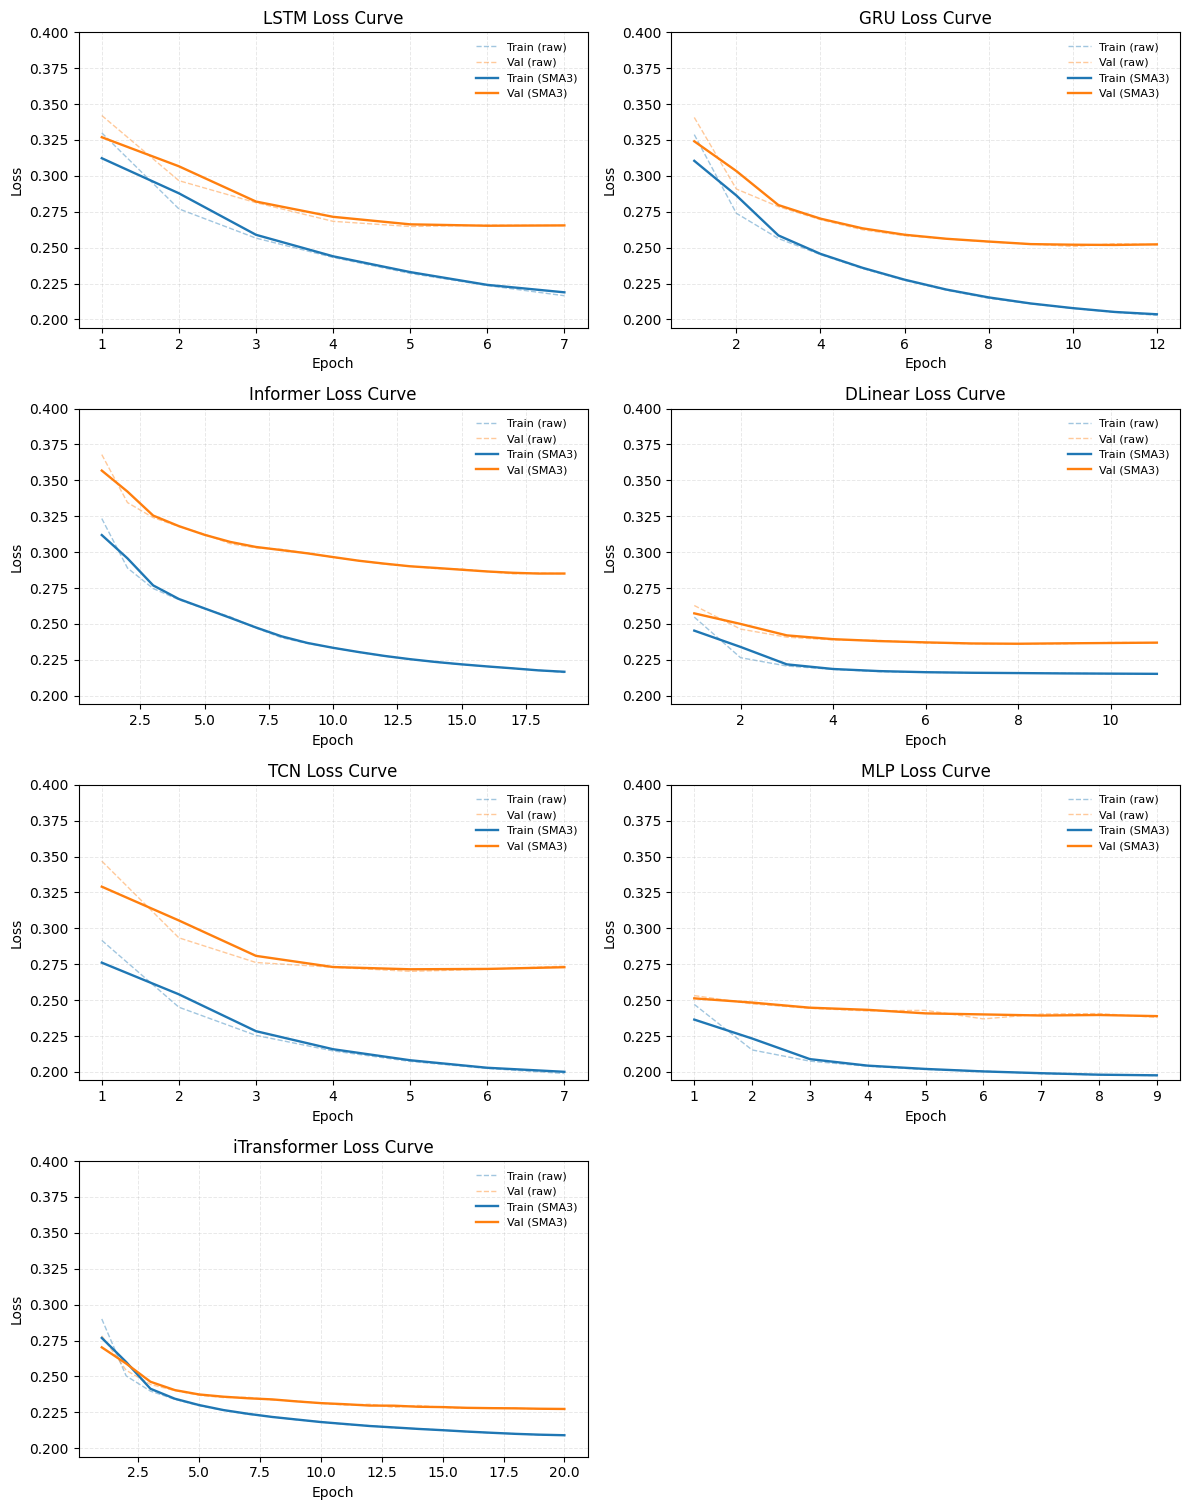

Figure written: outputs/figures/dl_loss_curves_all_models.png
Plot options -> smoothing window: 3, unified_y_axis: True, padding_ratio: 0.02, y_round_step: 0.05, use_manual_ylim: False
Unified y-limits -> [0.1940, 0.4000]


In [31]:
# Visualize training and validation loss curves for all trained DL models, with consistent y-axis scaling for fair comparison.

if 'dl_histories' not in globals() or len(dl_histories) == 0:
    print('DL histories are unavailable. Run one or more per-model DL training cells first.')
else:
    def _sma(arr, window=3):
        """Simple moving average."""
        arr = np.asarray(arr, dtype=np.float32)
        w = int(max(1, window))
        if (w <= 1) or (arr.size < w):
            return arr
        kernel = np.ones(w, dtype=np.float32) / float(w)
        pad_l = w // 2
        pad_r = w - 1 - pad_l
        padded = np.pad(arr, (pad_l, pad_r), mode='edge')
        return np.convolve(padded, kernel, mode='valid')

    def _round_up_to_step(v, step=0.05, eps=1e-6):
        """Rounds up a value to the nearest multiple of step."""
        step = float(max(1e-6, step))
        # Subtract a tiny epsilon to avoid floating-point boundary inflation,
        return float(np.ceil((float(v) - float(eps)) / step) * step)

    n_models = len(dl_histories)
    n_cols = 2
    n_rows = int(np.ceil(n_models / n_cols))

    smooth_w = int(CONFIG.get('loss_plot_smoothing_window', 3))
    y_min_cfg = CONFIG.get('loss_plot_ymin', None)
    y_max_cfg = CONFIG.get('loss_plot_ymax', None)
    y_pad_ratio = float(CONFIG.get('loss_plot_padding_ratio', 0.02))
    y_round_step = float(CONFIG.get('loss_plot_y_round_step', 0.05))
    use_manual_ylim = bool(CONFIG.get('loss_plot_use_manual_ylim', False))

    # Use a unified y-axis across all model subplots for fair visual comparison.
    share_y = True
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.8 * n_rows), squeeze=False, sharey=share_y)

    global_vals = []
    global_vals_for_top = []
    for _, hist in dl_histories.items():
        tr_raw = np.asarray(hist.get('train', []), dtype=np.float32)
        va_raw = np.asarray(hist.get('val', []), dtype=np.float32)
        if tr_raw.size and va_raw.size:
            n_ep = min(len(tr_raw), len(va_raw))
            tr_raw = tr_raw[:n_ep]
            va_raw = va_raw[:n_ep]
            global_vals.append(tr_raw)
            global_vals.append(va_raw)
            # Use smoothed curves to determine top bound for cleaner visual framing.
            global_vals_for_top.append(_sma(tr_raw, smooth_w))
            global_vals_for_top.append(_sma(va_raw, smooth_w))

    if len(global_vals) > 0:
        all_vals = np.concatenate(global_vals)
        gmin = float(np.nanmin(all_vals))
        gspan = max(1e-6, float(np.nanmax(all_vals)) - gmin)
        gpad = max(1e-6, y_pad_ratio * gspan)
        global_ymin = gmin - gpad

        top_vals = np.concatenate(global_vals_for_top) if len(global_vals_for_top) > 0 else all_vals
        gmax_top = float(np.nanmax(top_vals))
        global_ymax = _round_up_to_step(gmax_top, y_round_step)
    else:
        global_ymin, global_ymax = 0.0, 1.0

    if use_manual_ylim:
        if y_min_cfg is not None:
            global_ymin = float(y_min_cfg)
        if y_max_cfg is not None:
            global_ymax = float(y_max_cfg)

    if global_ymin >= global_ymax:
        global_ymin = global_ymax - max(1e-3, 0.2 * max(abs(global_ymax), 1.0))

    for i, (name, hist) in enumerate(dl_histories.items()):
        r, c = divmod(i, n_cols)
        ax = axes[r][c]

        tr_raw = np.asarray(hist.get('train', []), dtype=np.float32)
        va_raw = np.asarray(hist.get('val', []), dtype=np.float32)
        if tr_raw.size == 0 or va_raw.size == 0:
            ax.set_title(f'{name} Loss Curve (no data)')
            ax.axis('off')
            continue

        n_ep = min(len(tr_raw), len(va_raw))
        tr_raw = tr_raw[:n_ep]
        va_raw = va_raw[:n_ep]

        tr = _sma(tr_raw, smooth_w)
        va = _sma(va_raw, smooth_w)
        ep = np.arange(1, n_ep + 1)

        ax.plot(ep, tr_raw, color='#1f77b4', alpha=0.42, linewidth=1.0, linestyle='--', label='Train (raw)', zorder=1)
        ax.plot(ep, va_raw, color='#ff7f0e', alpha=0.42, linewidth=1.0, linestyle='--', label='Val (raw)', zorder=1)
        ax.plot(ep, tr, color='#1f77b4', linewidth=1.7, label=f'Train (SMA{smooth_w})', zorder=2)
        ax.plot(ep, va, color='#ff7f0e', linewidth=1.7, label=f'Val (SMA{smooth_w})', zorder=2)

        ax.set_ylim(global_ymin, global_ymax)
        ax.set_title(f'{name} Loss Curve')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.tick_params(axis='y', labelleft=True)
        ax.grid(alpha=0.28, linestyle='--', linewidth=0.7)
        ax.legend(fontsize=8, loc='best', frameon=False)

    for j in range(n_models, n_rows * n_cols):
        r, c = divmod(j, n_cols)
        axes[r][c].axis('off')

    plt.tight_layout()
    plt.savefig(out_path('figures', 'dl_loss_curves_all_models.png'), dpi=150)
    plt.show()
    print('Figure written: outputs/figures/dl_loss_curves_all_models.png')
    print(f'Plot options -> smoothing window: {smooth_w}, unified_y_axis: {share_y}, padding_ratio: {y_pad_ratio}, y_round_step: {y_round_step}, use_manual_ylim: {use_manual_ylim}')
    print(f'Unified y-limits -> [{global_ymin:.4f}, {global_ymax:.4f}]')

DL comparison table (normalized metrics):


,Model,MAE,MSE,RMSE,TrainTimeSec,LatencyMeanMs,LatencyP95Ms,SkillScore_MAE (%)
0,iTransformer,0.352830,0.326142,0.571089,61.104970,1.886005,2.609780,46.925695
1,DLinear,0.357350,0.337840,0.581240,13.310861,0.762325,1.047440,46.245744
2,MLP,0.367928,0.337725,0.581141,11.813582,0.494463,0.808285,44.654497
3,GRU,0.392483,0.362066,0.601719,31.190606,0.700789,0.888885,40.960838
4,TCN,0.407607,0.390405,0.624824,53.072150,1.393195,1.824805,38.685785
5,LSTM,0.408655,0.390498,0.624898,24.512219,0.640314,0.742305,38.528270
6,Informer,0.434482,0.436938,0.661013,644.441214,7.465490,9.681685,34.643263
7,Naive,0.664785,1.213897,1.101770,0.008345,0.005075,0.005400,0.000000


Best DL model by MAE: iTransformer
Per-variable metrics of the best DL model [normalized]:


,Variable,MAE,MSE,RMSE
0,OT,0.138325,0.033815,0.183889
1,LULL,0.251210,0.118574,0.344346
2,MULL,0.292182,0.164852,0.406019
3,HULL,0.328227,0.196193,0.442937
4,LUFL,0.471202,0.498581,0.706102
5,MUFL,0.493437,0.650654,0.806631
6,HUFL,0.495225,0.620328,0.787609


Figure written: outputs/figures/iTransformer_top_20_difficult_variables.png


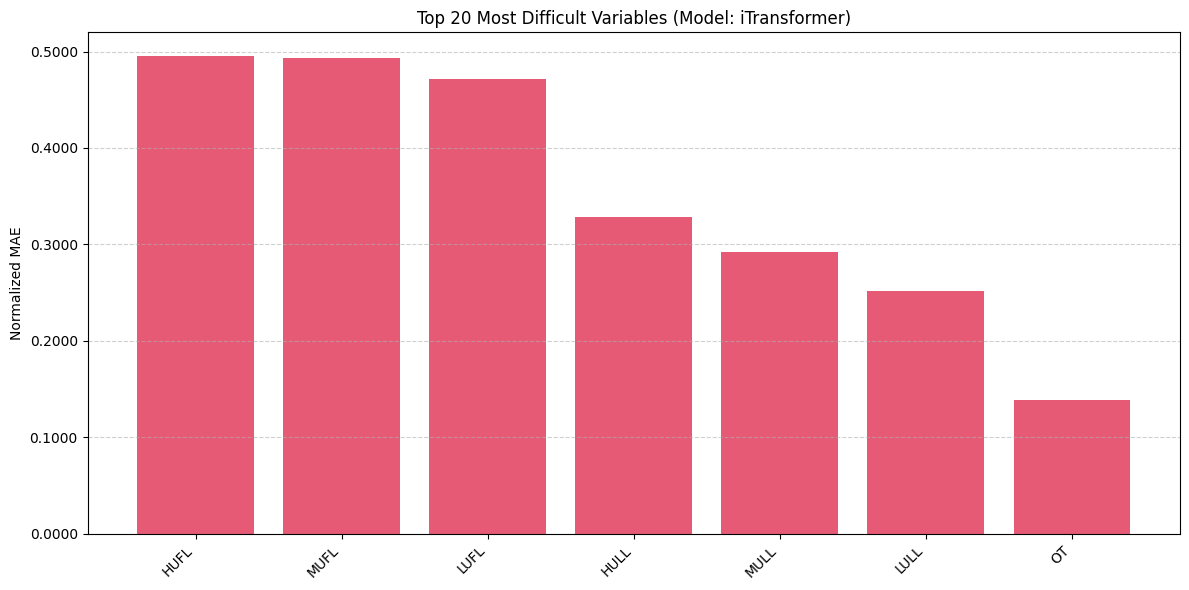

In [32]:
# Compile DL results into a comparison table, identify the best model by MAE, and display per-variable metrics for the best model.

dl_result_df = pd.DataFrame(results)
compare_models = list(active_dl_models) + ['Naive']
dl_result_df = dl_result_df[dl_result_df['Model'].isin(compare_models)].copy()
dl_result_df = dl_result_df.sort_values(['MAE', 'MSE']).reset_index(drop=True)
if 'Naive' in dl_result_df['Model'].values:
    naive_mae = dl_result_df.loc[dl_result_df['Model'] == 'Naive', 'MAE'].values[0]
    dl_result_df['SkillScore_MAE (%)'] = (1 - dl_result_df['MAE'] / naive_mae) * 100

if len(dl_result_df) == 0:
    print('No DL results found.')
else:
    print('DL comparison table (normalized metrics):')
    display(dl_result_df.reindex(columns=['Model', 'MAE', 'MSE', 'RMSE', 'TrainTimeSec', 'LatencyMeanMs', 'LatencyP95Ms', 'SkillScore_MAE (%)']).dropna(axis=1, how='all'))    
    best_dl_model = dl_result_df.iloc[0]['Model']
    print(f'Best DL model by MAE: {best_dl_model}')

    if f"{best_dl_model}_M96" in per_variable_reports:
        print('Per-variable metrics of the best DL model [normalized]:')
        display(per_variable_reports[f"{best_dl_model}_M96"]['normalized'])

        pv_df = per_variable_reports[f"{best_dl_model}_M96"]['normalized']
        top_n = 20
        plot_df = pv_df.sort_values('MAE', ascending=False).head(top_n)

        plt.figure(figsize=(12, 6))
        plt.bar(plot_df['Variable'], plot_df['MAE'], color='crimson', alpha=0.7)
        plt.xticks(rotation=45, ha='right')
        plt.gca().yaxis.set_major_formatter(plt.FormatStrFormatter('%.4f'))
        plt.title(f'Top {top_n} Most Difficult Variables (Model: {best_dl_model})')
        plt.ylabel('Normalized MAE')
        plt.grid(axis='y', linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.savefig(out_path('figures', f'{best_dl_model}_top_{top_n}_difficult_variables.png'), dpi=150)
        print(f'Figure written: outputs/figures/{best_dl_model}_top_{top_n}_difficult_variables.png')
        plt.show()

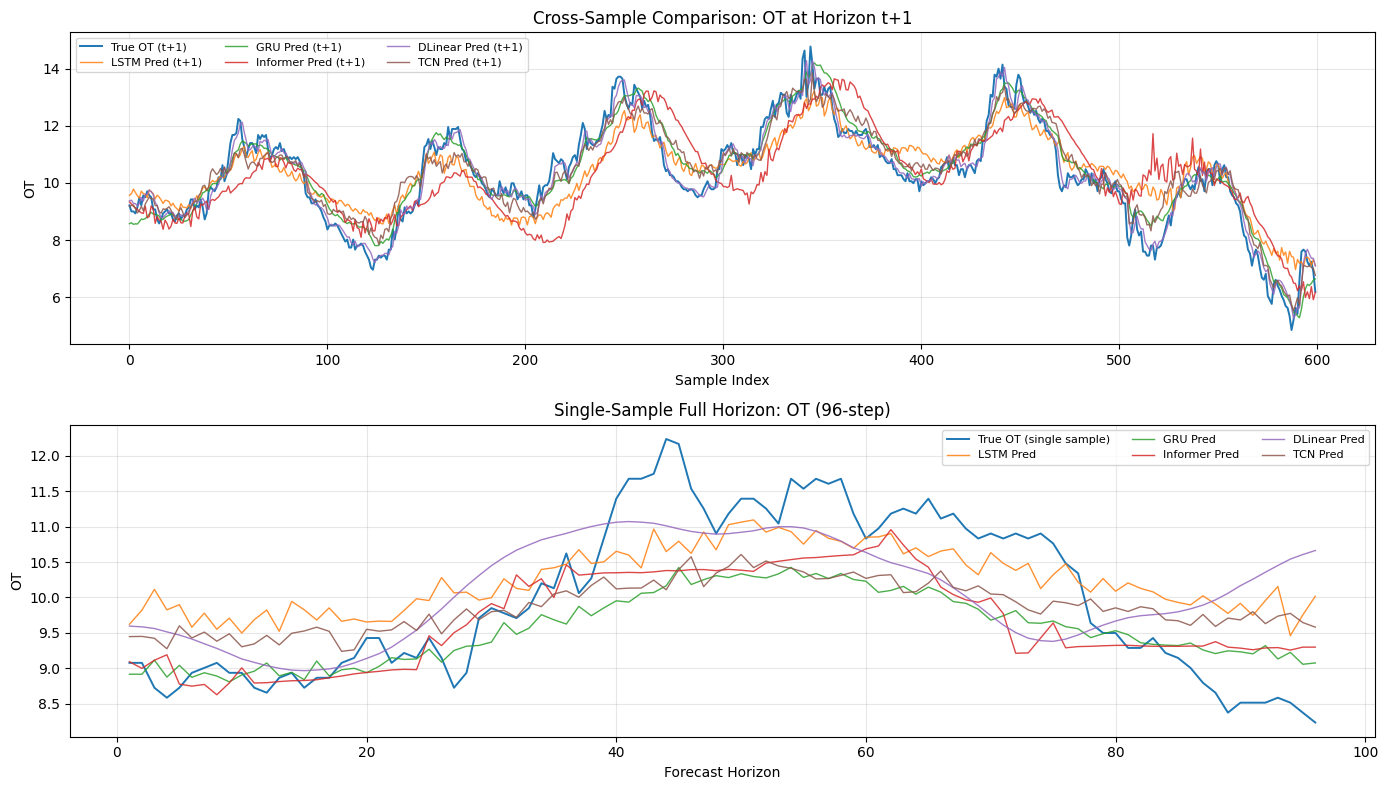

Figure written: outputs/figures/dl_prediction_comparison_ot_h1_and_96step.png


In [33]:
# Visualize the OT variable predictions at horizon t+1 and across the full 96-step horizon for all trained DL models, compared to true values.

if 'dl_outputs' not in globals() or len(dl_outputs) == 0:
    print('DL outputs are unavailable. Run one or more per-model DL training cells first.')
else:
    ot_idx = target_cols.index('OT')
    ot_h1_col = ot_idx
    model_names = list(dl_outputs.keys())
    plot_models = model_names[:min(5, len(model_names))]
    ref_true_inv = dl_outputs[plot_models[0]]['true_inv']

    n_show = min(600, len(ref_true_inv))
    sample_idx = min(12, len(ref_true_inv) - 1)
    h = np.arange(1, pred_len + 1)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

    axes[0].plot(ref_true_inv[:n_show, ot_h1_col], label='True OT (t+1)', linewidth=1.4)
    for name in plot_models:
        axes[0].plot(
            dl_outputs[name]['pred_inv'][:n_show, ot_h1_col],
            label=f'{name} Pred (t+1)',
            linewidth=1.0,
            alpha=0.85
        )
    axes[0].set_title('Cross-Sample Comparison: OT at Horizon t+1')
    axes[0].set_xlabel('Sample Index')
    axes[0].set_ylabel('OT')
    axes[0].grid(alpha=0.3)
    axes[0].legend(ncol=3, fontsize=8)

    true_seq = ref_true_inv[sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
    axes[1].plot(h, true_seq, label='True OT (single sample)', linewidth=1.4)
    for name in plot_models:
        pred_seq = dl_outputs[name]['pred_inv'][sample_idx].reshape(pred_len, target_dim)[:, ot_idx]
        axes[1].plot(h, pred_seq, label=f'{name} Pred', linewidth=1.0, alpha=0.85)
    axes[1].set_title('Single-Sample Full Horizon: OT (96-step)')
    axes[1].set_xlabel('Forecast Horizon')
    axes[1].set_ylabel('OT')
    axes[1].grid(alpha=0.3)
    axes[1].legend(ncol=3, fontsize=8)

    plt.tight_layout()
    plt.savefig(out_path('figures', 'dl_prediction_comparison_ot_h1_and_96step.png'), dpi=150)
    plt.show()
    print('Figure written: outputs/figures/dl_prediction_comparison_ot_h1_and_96step.png')

# 6. Model Comparison and Visualization

This section consolidates model outputs into a unified comparison table and visual trade-off views for accuracy, latency, and training cost.
It generates standardized artifacts used for final selection and reporting.

In [34]:
# Build results DataFrame from all model runs
all_results_df = pd.DataFrame(results)

# Validate required columns exist
required_cols = [
    'Task', 'Model', 'MAE', 'MSE', 'RMSE',
    'TrainTimeSec', 'LatencyMeanMs', 'LatencyP95Ms'
]
missing_cols = [c for c in required_cols if c not in all_results_df.columns]
if missing_cols:
    raise ValueError(f'Missing required columns in results: {missing_cols}')

# Filter to M-96 task and compute latency compliance flag
result_df = all_results_df[all_results_df['Task'] == 'M-96'].reset_index(drop=True)
LATENCY_THRESHOLD_MS = 50.0
result_df['MeetsLatency<50ms'] = result_df['LatencyP95Ms'] < LATENCY_THRESHOLD_MS

# Compute SkillScore_MAE (%) relative to Naive baseline
naive_row = result_df[result_df['Model'] == 'Naive']
if len(naive_row) > 0:
    naive_mae = float(naive_row.iloc[0]['MAE'])
    result_df['SkillScore_MAE (%)'] = (
        (naive_mae - result_df['MAE']) / naive_mae * 100.0
    ).round(2)
else:
    result_df['SkillScore_MAE (%)'] = float('nan')

# ---------------------------------------------------------------------------
# Energy & carbon estimation
# Power assumptions (kW):
#   GPU (CUDA) : 0.25 kW  — conservative single-GPU TDP fraction
#   CPU        : 0.065 kW — typical server CPU under load
# Carbon intensity: 0.475 kgCO2e/kWh (global average)
# Per-model energy = power_kw * (TrainTimeSec / 3600)
# Note: Power/carbon constants are heuristic estimates for relative ranking only, not intended for precise physical accounting.
# ---------------------------------------------------------------------------
run_device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
POWER_KW = 0.25 if run_device.type == 'cuda' else 0.065
CARBON_INTENSITY = 0.475  # kgCO2e per kWh

result_df['EnergyKWh'] = (result_df['TrainTimeSec'] / 3600.0 * POWER_KW).round(8)
result_df['CO2g'] = (result_df['EnergyKWh'] * CARBON_INTENSITY * 1000.0).round(4)

total_energy_kwh = float(result_df['EnergyKWh'].sum())
total_co2_g = float(result_df['CO2g'].sum())


def style_top3(df):
    """Highlight top-3 performers per metric; works on both dark and light backgrounds."""
    low_is_better = [
        'MAE', 'MSE', 'RMSE', 'TrainTimeSec',
        'LatencyMeanMs', 'LatencyP95Ms', 'EnergyKWh', 'CO2g'
    ]
    high_is_better = ['SkillScore_MAE (%)']
    metric_cols = low_is_better + high_is_better

    # Rank 1: deep teal  |  Rank 2: steel blue  |  Rank 3: slate purple
    colors = {1: '#1a7a6e', 2: '#2a6496', 3: '#5b4a8a'}

    def color_col(col):
        """Apply background color to top 3 rows based on column value."""
        style = ['' for _ in col]
        if col.name in metric_cols and len(col) > 0:
            ascending = col.name in low_is_better
            order = np.argsort(col.values if ascending else -col.values)
            for rank, idx in enumerate(order[:min(3, len(col))], start=1):
                style[idx] = (
                    f'background-color: {colors[rank]}; '
                    f'color: #ffffff; font-weight: 700;'
                )
        return style

    fmt = {
        'MAE': '{:.6f}', 'MSE': '{:.6f}', 'RMSE': '{:.6f}',
        'SkillScore_MAE (%)': '{:.2f}%',
        'TrainTimeSec': '{:.3f}', 'LatencyMeanMs': '{:.3f}', 'LatencyP95Ms': '{:.3f}',
        'EnergyKWh': '{:.6f}', 'CO2g': '{:.4f}'
    }
    fmt = {k: v for k, v in fmt.items() if k in df.columns}
    return df.style.apply(color_col, axis=0).format(fmt)


# Sort by MAE and display comparison table
m_df = result_df.sort_values(['MAE', 'MSE']).reset_index(drop=True)

if len(m_df) == 0:
    print('No M-96 results found.')
else:
    print('Final comparison table (M-96, multivariate-to-multivariate):')
    display(style_top3(m_df))

    # Best model summary — safe column selection
    best_row_m = m_df.iloc[0]
    summary_cols = ['Model', 'MAE', 'RMSE', 'LatencyP95Ms', 'MeetsLatency<50ms',
                    'EnergyKWh', 'CO2g']
    if 'SkillScore_MAE (%)' in m_df.columns:
        summary_cols.insert(2, 'SkillScore_MAE (%)')
    print('\nTop-Ranked Model Summary:')
    display(pd.DataFrame([best_row_m[summary_cols]]))

    # Latency compliance report
    compliant = m_df[m_df['MeetsLatency<50ms'] == True]
    non_compliant = m_df[m_df['MeetsLatency<50ms'] == False]
    print(f'\nLatency Compliance Report (threshold: {LATENCY_THRESHOLD_MS} ms P95):')
    print(f'  Compliant models  : {len(compliant)} — {list(compliant["Model"])}')
    print(f'  Non-compliant     : {len(non_compliant)} — {list(non_compliant["Model"])}')

# Summary footer
print(f'\nTotal train time  (M-96): {result_df["TrainTimeSec"].sum():.2f} sec')
print(f'Total energy      (M-96): {total_energy_kwh:.6f} kWh'
      f'  (device={run_device.type}, power={POWER_KW} kW)')
print(f'Total CO2 emitted (M-96): {total_co2_g:.4f} g CO2e'
      f'  (intensity={CARBON_INTENSITY} kgCO2e/kWh)')
print('Note: Energy and carbon estimates are heuristic and intended for relative comparison, not precise accounting.')

# Persist metric tables
result_df.to_csv(out_path('tables', 'final_metrics_m96.csv'), index=False)
all_results_df.to_csv(out_path('tables', 'final_metrics_table_all_tasks.csv'), index=False)
print('Metric tables written: outputs/tables/final_metrics_m96.csv'
      ' and outputs/tables/final_metrics_table_all_tasks.csv')


Final comparison table (M-96, multivariate-to-multivariate):


,Task,Model,MAE,MSE,RMSE,TrainTimeSec,LatencyMeanMs,LatencyP95Ms,Explainability,MeetsLatency<50ms,SkillScore_MAE (%),EnergyKWh,CO2g
0,M-96,iTransformer,0.352830,0.326142,0.571089,61.105,1.886,2.610,Model-dependent (post-hoc),True,46.93%,0.004243,2.0156
1,M-96,DLinear,0.357350,0.337840,0.581240,13.311,0.762,1.047,Model-dependent (post-hoc),True,46.25%,0.000924,0.4391
2,M-96,MLP,0.367928,0.337725,0.581141,11.814,0.494,0.808,Model-dependent (post-hoc),True,44.65%,0.000820,0.3897
3,M-96,GRU,0.392483,0.362066,0.601719,31.191,0.701,0.889,Model-dependent (post-hoc),True,40.96%,0.002166,1.0289
4,M-96,TCN,0.407607,0.390405,0.624824,53.072,1.393,1.825,Model-dependent (post-hoc),True,38.69%,0.003686,1.7506
5,M-96,LSTM,0.408655,0.390498,0.624898,24.512,0.640,0.742,Model-dependent (post-hoc),True,38.53%,0.001702,0.8086
6,M-96,Informer,0.434482,0.436938,0.661013,644.441,7.465,9.682,Model-dependent (post-hoc),True,34.64%,0.044753,21.2576
7,M-96,Ridge,0.447693,0.437603,0.661516,1.029,0.202,0.308,High (linear coefficients),True,32.66%,0.000071,0.0339
8,M-96,KNN,0.653379,0.760602,0.872125,0.056,116.612,153.543,Low (Instance-based),False,1.72%,0.000004,0.0018
9,M-96,Naive,0.664785,1.213897,1.101770,0.008,0.005,0.005,High (Last-step repeat),True,0.00%,0.000001,0.0003



Top-Ranked Model Summary:


,Model,MAE,SkillScore_MAE (%),RMSE,LatencyP95Ms,MeetsLatency<50ms,EnergyKWh,CO2g
0,iTransformer,0.35283,46.93,0.571089,2.60978,True,0.004243,2.0156



Latency Compliance Report (threshold: 50.0 ms P95):
  Compliant models  : 9 — ['iTransformer', 'DLinear', 'MLP', 'GRU', 'TCN', 'LSTM', 'Informer', 'Ridge', 'Naive']
  Non-compliant     : 1 — ['KNN']

Total train time  (M-96): 840.54 sec
Total energy      (M-96): 0.058371 kWh  (device=cuda, power=0.25 kW)
Total CO2 emitted (M-96): 27.7261 g CO2e  (intensity=0.475 kgCO2e/kWh)
Note: Energy and carbon estimates are heuristic and intended for relative comparison, not precise accounting.
Metric tables written: outputs/tables/final_metrics_m96.csv and outputs/tables/final_metrics_table_all_tasks.csv


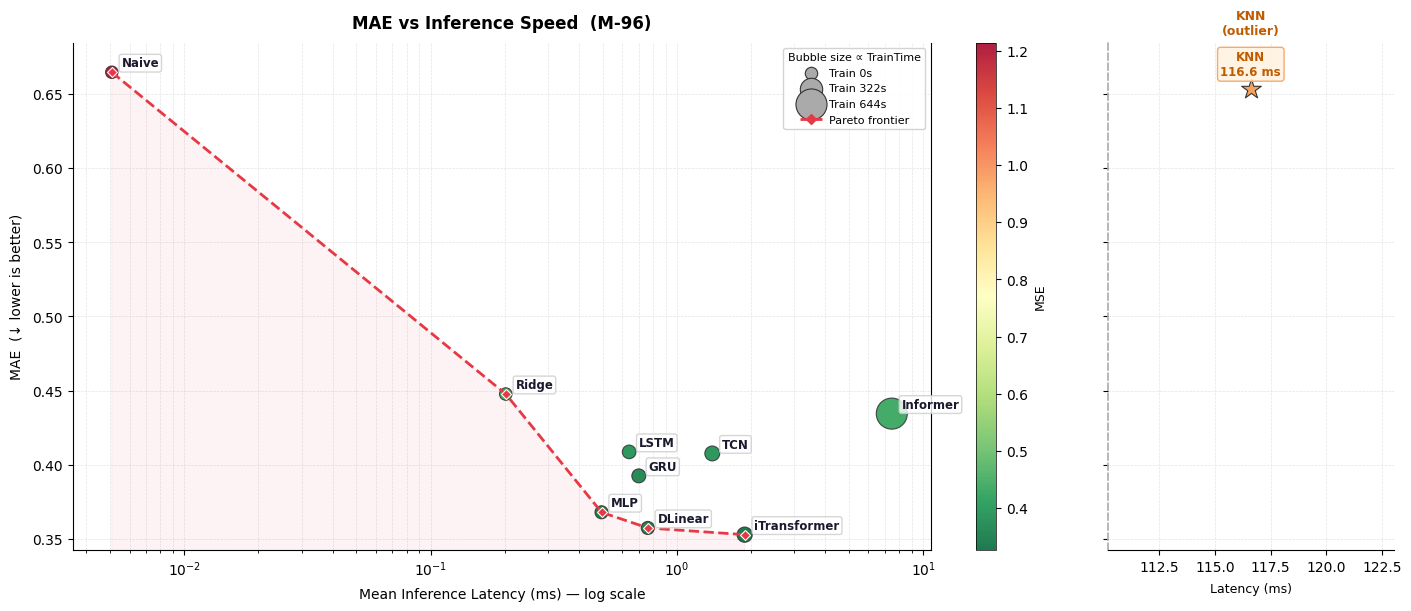

Figure written: outputs/figures/mae_vs_latencymean_tradeoff_m96.png
log_x=True | pareto_points=5 | knn_panel=True


In [35]:
# MAE vs Inference Speed Trade-off (M-96)
# Bubble size encodes training time; color encodes MSE; Pareto frontier marks optimal models.

if 'm_df' not in globals() or len(m_df) == 0:
    print('m_df is unavailable. Run the final comparison cell first.')
else:
    trade_df = m_df.dropna(subset=['MAE', 'LatencyMeanMs']).copy()

    # Separate KNN as a high-latency outlier to avoid axis compression
    knn_mask  = trade_df['Model'].astype(str).str.upper() == 'KNN'
    main_df   = trade_df[~knn_mask].reset_index(drop=True)
    knn_df    = trade_df[knn_mask].reset_index(drop=True)

    if len(main_df) == 0:
        print('No plottable rows after excluding KNN.')
    else:
        use_log_x = bool(CONFIG.get('tradeoff_use_log_x', True))

        if len(knn_df) > 0:
            fig, (ax_main, ax_knn) = plt.subplots(
                1, 2, figsize=(14, 6),
                gridspec_kw={'width_ratios': [3, 1], 'wspace': 0.08},
                layout='constrained'
            )
        else:
            fig, ax_main = plt.subplots(figsize=(11, 6), layout='constrained')
            ax_knn = None

        fig.patch.set_facecolor('white')

        # Bubble size: min-max normalised TrainTimeSec → [80, 500]
        t = np.asarray(main_df['TrainTimeSec'], dtype=float)
        t_range = max(t.max() - t.min(), 1e-6)
        sizes = 80 + 420 * (t - t.min()) / t_range

        # Colour: MSE (lower = cooler colour)
        c_vals = main_df['MSE'].values if 'MSE' in main_df.columns else main_df['MAE'].values
        cmap   = plt.cm.RdYlGn_r          # red = high MSE, green = low MSE

        sc = ax_main.scatter(
            main_df['LatencyMeanMs'], main_df['MAE'],
            s=sizes, c=c_vals, cmap=cmap,
            alpha=0.88, edgecolors='#333333', linewidths=0.8,
            zorder=3
        )

        # Pareto frontier (lower-left dominance)
        pf = main_df.sort_values('LatencyMeanMs').reset_index(drop=True)
        px, py, best = [], [], np.inf
        for _, r in pf.iterrows():
            if float(r['MAE']) < best:
                px.append(float(r['LatencyMeanMs']))
                py.append(float(r['MAE']))
                best = float(r['MAE'])

        if len(px) >= 2:
            ax_main.plot(px, py,
                         color='#E63946', lw=2.0, ls='--',
                         marker='D', ms=5,
                         mfc='#E63946', mec='white', mew=0.8,
                         zorder=4, label='Pareto frontier')
            ax_main.fill_between(px, py, alpha=0.06, color='#E63946', zorder=2)

        # Model labels
        for _, r in main_df.iterrows():
            ax_main.annotate(
                str(r['Model']),
                xy=(float(r['LatencyMeanMs']), float(r['MAE'])),
                xytext=(7, 4), textcoords='offset points',
                fontsize=8.5, fontweight='semibold', color='#1a1a2e',
                bbox=dict(boxstyle='round,pad=0.2', fc='white',
                          ec='#cccccc', alpha=0.80),
                zorder=5
            )

        # Axes formatting
        if use_log_x:
            ax_main.set_xscale('log')

        ax_main.set_xlabel(
            'Mean Inference Latency (ms)' + (' — log scale' if use_log_x else ''),
            fontsize=10, labelpad=6
        )
        ax_main.set_ylabel('MAE  (↓ lower is better)', fontsize=10, labelpad=6)
        ax_main.set_title('MAE vs Inference Speed  (M-96)',
                          fontsize=12, fontweight='bold', pad=10)
        ax_main.grid(True, which='both', ls='--', lw=0.5,
                     color='#dddddd', alpha=0.8)
        ax_main.set_axisbelow(True)
        ax_main.spines[['top', 'right']].set_visible(False)

        # Colour bar 
        cbar = fig.colorbar(sc, ax=ax_main, pad=0.02, fraction=0.03, aspect=25)
        cbar.set_label('MSE', fontsize=9)
        cbar.outline.set_linewidth(0.5)

        # Bubble-size legend
        t_lo = float(main_df['TrainTimeSec'].min())
        t_hi = float(main_df['TrainTimeSec'].max())
        t_md = (t_lo + t_hi) / 2
        legend_items = [
            plt.scatter([], [], s=80,  c='#aaaaaa', ec='#333333', lw=0.8,
                        label=f'Train {t_lo:.0f}s'),
            plt.scatter([], [], s=260, c='#aaaaaa', ec='#333333', lw=0.8,
                        label=f'Train {t_md:.0f}s'),
            plt.scatter([], [], s=500, c='#aaaaaa', ec='#333333', lw=0.8,
                        label=f'Train {t_hi:.0f}s'),
        ]
        pareto_line = plt.Line2D([0], [0], color='#E63946', lw=2,
                                 ls='--', marker='D', ms=5,
                                 label='Pareto frontier')
        ax_main.legend(
            handles=legend_items + [pareto_line],
            title='Bubble size ∝ TrainTime',
            title_fontsize=8, fontsize=8,
            loc='upper right', framealpha=0.85,
            edgecolor='#cccccc', handletextpad=0.6
        )

        # KNN panel (right subplot)
        if ax_knn is not None and len(knn_df) > 0:
            for _, r in knn_df.iterrows():
                ax_knn.scatter(
                    [float(r['LatencyMeanMs'])], [float(r['MAE'])],
                    s=220, marker='*', color='#F4A261',
                    edgecolors='#333333', lw=0.8, zorder=3
                )
                ax_knn.annotate(
                    f"KNN\n{float(r['LatencyMeanMs']):.1f} ms",
                    xy=(float(r['LatencyMeanMs']), float(r['MAE'])),
                    xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=8.5, fontweight='bold',
                    color='#c05c00',
                    bbox=dict(boxstyle='round,pad=0.25', fc='#fff3e0',
                              ec='#F4A261', alpha=0.9),
                    zorder=5
                )

            ax_knn.set_xlabel('Latency (ms)', fontsize=9, labelpad=6)
            ax_knn.set_title('KNN\n(outlier)', fontsize=9,
                             fontweight='bold', color='#c05c00')
            ax_knn.grid(True, ls='--', lw=0.5, color='#dddddd', alpha=0.8)
            ax_knn.set_axisbelow(True)
            ax_knn.spines[['top', 'right']].set_visible(False)
            ax_knn.yaxis.set_tick_params(labelleft=False)

            # Shared y-axis range for visual consistency
            y_lo = min(main_df['MAE'].min(), knn_df['MAE'].min()) * 0.97
            y_hi = max(main_df['MAE'].max(), knn_df['MAE'].max()) * 1.03
            ax_main.set_ylim(y_lo, y_hi)
            ax_knn.set_ylim(y_lo, y_hi)

            # Broken-axis indicator
            for spine in ['left', 'right']:
                ax_main.spines[spine].set_visible(True)
            ax_knn.spines['left'].set_linestyle((0, (4, 2)))
            ax_knn.spines['left'].set_linewidth(1.2)
            ax_knn.spines['left'].set_color('#aaaaaa')

        plt.savefig(
            out_path('figures', 'mae_vs_latencymean_tradeoff_m96.png'),
            dpi=150, bbox_inches='tight', facecolor='white'
        )
        plt.show()
        print('Figure written: outputs/figures/mae_vs_latencymean_tradeoff_m96.png')
        print(f'log_x={use_log_x} | pareto_points={len(px)} | knn_panel={len(knn_df)>0}')


# 7. Interpretability and Error Diagnostics

This section provides global and local interpretability analysis (Ridge coefficients, SHAP, and LIME when available) to explain model behavior.
It complements aggregate scores with feature-level attribution and error-focused diagnostics.

Top Ridge coefficients (absolute, averaged across outputs):


,Feature,MeanAbsCoef,BaseFeature,Lag
0,OT_t-0,0.108363,OT,0
1,LULL_t-0,0.072756,LULL,0
2,HUFL_t-0,0.060921,HUFL,0
3,HULL_t-0,0.054025,HULL,0
4,LUFL_t-0,0.053528,LUFL,0
5,MUFL_t-0,0.052259,MUFL,0
6,month_sin_t-0,0.048926,month_sin,0
7,LUFL_t-95,0.044889,LUFL,95
8,LULL_t-95,0.044529,LULL,95
9,month_sin_t-1,0.043255,month_sin,1


Aggregated coefficient importance by base feature:


,BaseFeature,MeanAbsCoef
6,OT,0.183881
8,month_sin,0.164769
3,LULL,0.154733
2,LUFL,0.098417
0,HUFL,0.095298
1,HULL,0.086979
7,month_cos,0.075908
4,MUFL,0.052259
5,MULL,0.041251


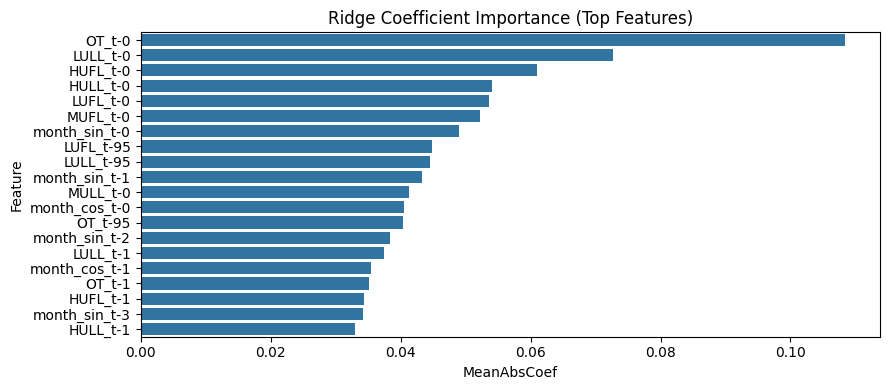

In [36]:
# Ridge explainability: coefficient importance aggregated over all horizons
if 'ridge_model' in globals():
    coef = np.asarray(ridge_model.coef_)  # shape: (pred_len*target_dim, seq_len*feature_dim)
    mean_abs_coef = np.mean(np.abs(coef), axis=0)

    feature_names_flat = []
    for t in range(seq_len):
        for c in feature_cols:
            feature_names_flat.append(f'{c}_t-{seq_len-1-t}')

    top_k = min(20, len(mean_abs_coef))
    top_idx = np.argsort(mean_abs_coef)[::-1][:top_k]
    coef_df = pd.DataFrame({
        'Feature': [feature_names_flat[i] for i in top_idx],
        'MeanAbsCoef': mean_abs_coef[top_idx]
    })
    coef_df[['BaseFeature', 'Lag']] = coef_df['Feature'].str.extract(r'(.+)_t-(\d+)')
    coef_df['Lag'] = coef_df['Lag'].astype(int)

    print('Top Ridge coefficients (absolute, averaged across outputs):')
    display(coef_df)

    agg = coef_df.groupby('BaseFeature', as_index=False)['MeanAbsCoef'].sum().sort_values('MeanAbsCoef', ascending=False)
    print('Aggregated coefficient importance by base feature:')
    display(agg)

    plt.figure(figsize=(9, 4))
    sns.barplot(data=coef_df, x='MeanAbsCoef', y='Feature', orient='h')
    plt.title('Ridge Coefficient Importance (Top Features)')
    plt.tight_layout()
    plt.savefig(out_path('figures', 'ridge_coef_importance.png'), dpi=150)
    plt.show()
else:
    print('Ridge model is unavailable. Execute the Ridge training cell first.')

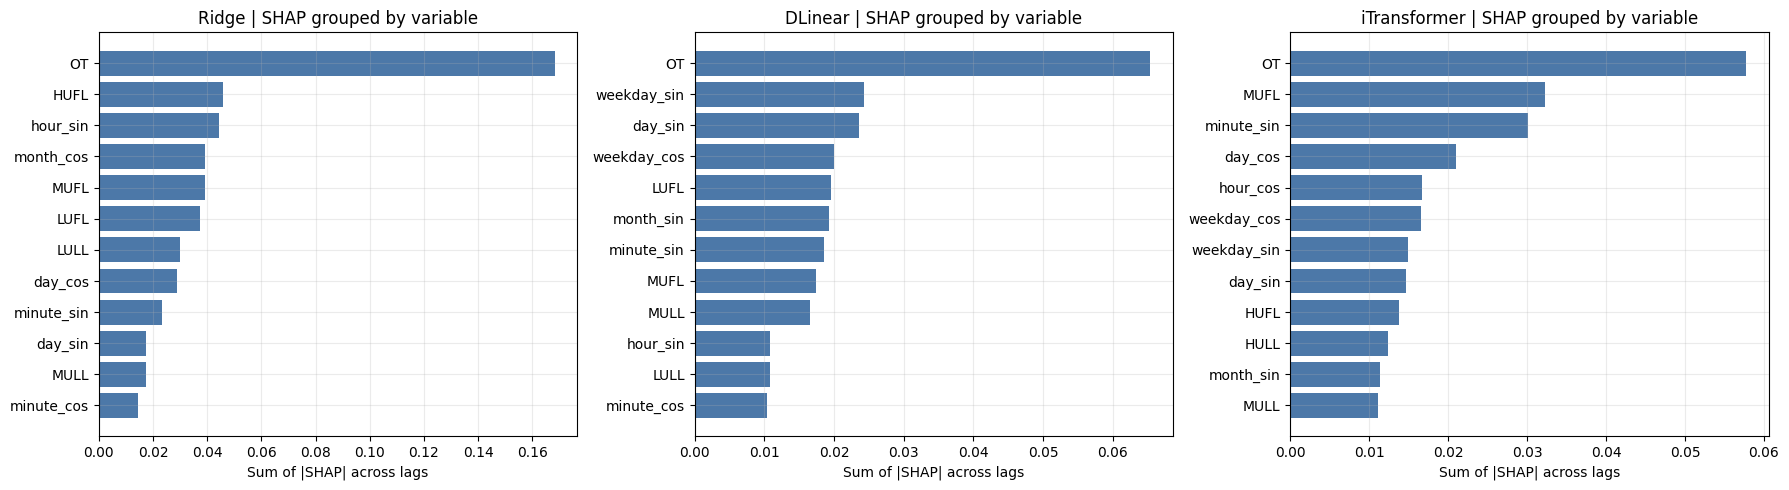

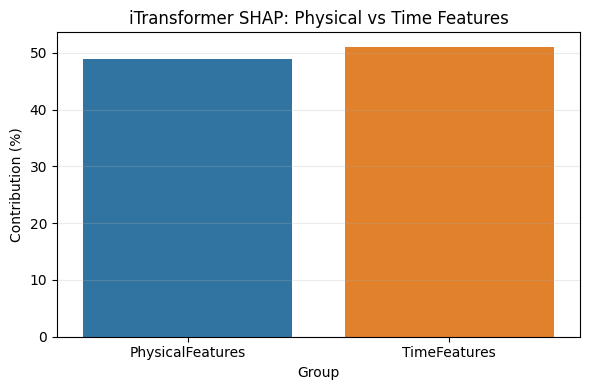

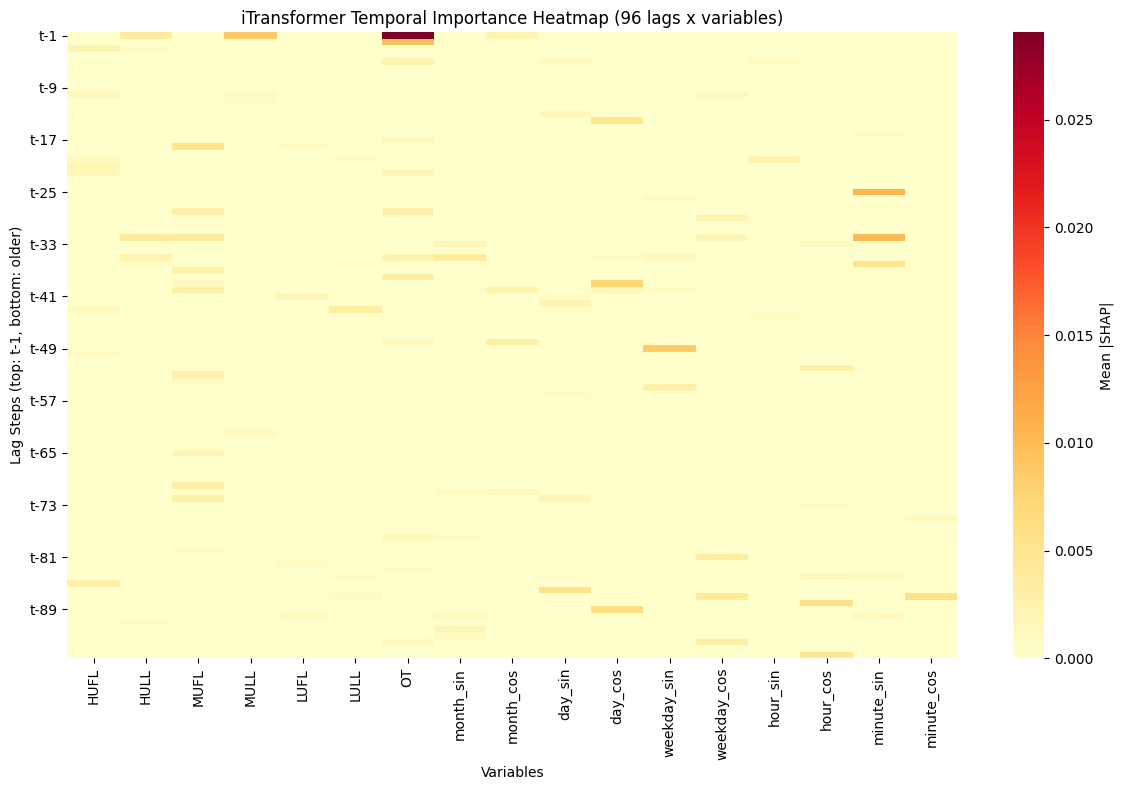

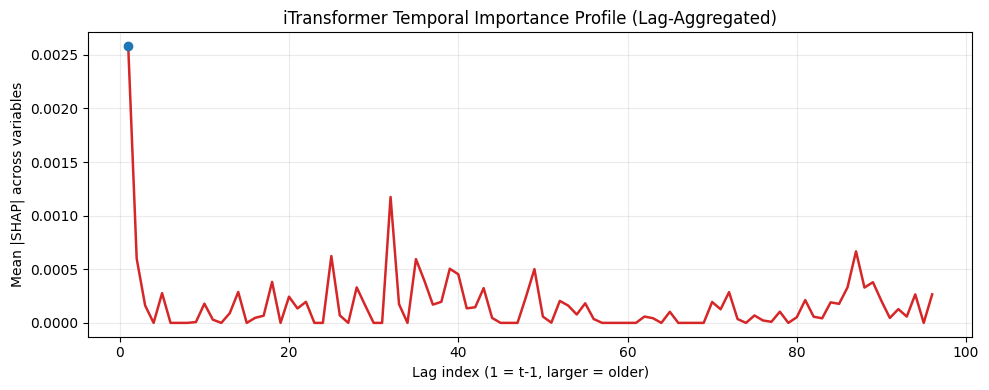

SHAP completed | background=32 | explained=6 | nsamples=200 | l1_reg=num_features(24)


,BaseFeature,AbsSHAP,ContributionPct
6,OT,0.057732,20.299279
4,MUFL,0.032286,11.352128
12,minute_sin,0.030066,10.571612
7,day_cos,0.020963,7.370638
9,hour_cos,0.016651,5.854718
15,weekday_cos,0.016568,5.825596
16,weekday_sin,0.014895,5.237196
8,day_sin,0.014684,5.163099
0,HUFL,0.013794,4.850027
1,HULL,0.012359,4.345625


In [37]:
# SHAP global interpretability analysis for all models (ridge, dlinear, itransformer) with available prerequisites.

if not SHAP_AVAILABLE:
    print('SHAP unavailable: global interpretability analysis skipped.')
else:
    required = [
        'X_train', 'X_test', 'feature_cols', 'seq_len', 'target_dim',
        'ridge_model', 'dlinear_model', 'itransformer_model'
    ]
    missing = [k for k in required if k not in globals()]
    if missing:
        print(f'SHAP prerequisites missing: {missing}')
    else:
        import warnings
        try:
            from sklearn.exceptions import ConvergenceWarning
        except Exception:
            ConvergenceWarning = Warning

        rng = np.random.RandomState(int(CONFIG.get('seed', 42)))

        feat_dim = int(X_test.shape[-1])

        n_bg = max(int(CONFIG.get('xai_kernel_background', 20)), 32)
        n_exp = max(int(CONFIG.get('xai_kernel_explain', 4)), 6)
        nsamp = max(int(CONFIG.get('xai_kernel_nsamples', 40)), 200)
        l1_topk = min(max(int(CONFIG.get('xai_shap_l1_topk', 24)), 12), 64)

        X_train_flat_local = np.asarray(X_train, dtype=np.float32).reshape(len(X_train), -1)
        X_test_flat_local = np.asarray(X_test, dtype=np.float32).reshape(len(X_test), -1)

        bg_idx = rng.choice(len(X_train_flat_local), size=min(n_bg, len(X_train_flat_local)), replace=False)
        exp_idx = rng.choice(len(X_test_flat_local), size=min(n_exp, len(X_test_flat_local)), replace=False)
        X_bg = X_train_flat_local[bg_idx]
        X_exp = X_test_flat_local[exp_idx]

        feature_names_flat = []
        for t in range(int(seq_len)):
            lag = int(seq_len) - 1 - t
            for c in feature_cols:
                feature_names_flat.append(f'{c}_t-{lag}')

        def _group_abs_shap(shap_mat):
            """Group SHAP values by base feature (ignoring lag)."""
            abs_mean = np.mean(np.abs(shap_mat), axis=0)
            rows = []
            for i, val in enumerate(abs_mean):
                base = feature_cols[i % feat_dim]
                rows.append((base, float(val)))
            df_g = pd.DataFrame(rows, columns=['BaseFeature', 'AbsSHAP'])
            out = df_g.groupby('BaseFeature', as_index=False)['AbsSHAP'].sum().sort_values('AbsSHAP', ascending=False)
            s = out['AbsSHAP'].sum()
            out['ContributionPct'] = (out['AbsSHAP'] / s * 100.0) if s > 0 else 0.0
            return out

        def _make_ridge_predict_fn():
            """Make a prediction function for Ridge that returns scalar output."""
            def _pred(Xf):
                y = ridge_model.predict(np.asarray(Xf, dtype=np.float32))
                y = np.asarray(y, dtype=np.float32).reshape(len(Xf), -1)
                return y.mean(axis=1)
            return _pred

        def _make_dl_predict_fn(model_obj):
            """Make a prediction function for a DL model that returns scalar output."""
            try:
                run_dev = next(model_obj.parameters()).device
            except Exception:
                run_dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

            def _pred(Xf):
                x = np.asarray(Xf, dtype=np.float32).reshape(-1, int(seq_len), feat_dim)
                xt = torch.from_numpy(x).to(run_dev)
                with torch.no_grad():
                    y = model_obj(xt).detach().cpu().numpy()
                y = np.asarray(y, dtype=np.float32).reshape(len(x), -1)
                return y.mean(axis=1)
            return _pred

        model_pred_map = {
            'Ridge': _make_ridge_predict_fn(),
            'DLinear': _make_dl_predict_fn(dlinear_model),
            'iTransformer': _make_dl_predict_fn(itransformer_model),
        }

        def _kernel_shap_values(explainer, X_local):
            """Compute SHAP values with fallbacks."""
            try:
                return explainer.shap_values(
                    X_local,
                    nsamples=nsamp,
                    l1_reg=f'num_features({l1_topk})',
                    silent=True
                )
            except TypeError:
                try:
                    return explainer.shap_values(
                        X_local,
                        nsamples=nsamp,
                        l1_reg=f'num_features({l1_topk})'
                    )
                except TypeError:
                    return explainer.shap_values(X_local, nsamples=nsamp)

        shap_group_tables = {}
        shap_raw = {}

        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', category=ConvergenceWarning)
            warnings.filterwarnings('ignore', category=UserWarning, module='shap.explainers._kernel')

            for mname, pfn in model_pred_map.items():
                explainer = shap.KernelExplainer(pfn, X_bg)
                shap_vals = _kernel_shap_values(explainer, X_exp)
                shap_mat = np.asarray(shap_vals, dtype=np.float32)
                if shap_mat.ndim == 1:
                    shap_mat = shap_mat.reshape(1, -1)
                shap_raw[mname] = shap_mat
                shap_group_tables[mname] = _group_abs_shap(shap_mat)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)
        for i, mname in enumerate(['Ridge', 'DLinear', 'iTransformer']):
            ax = axes[i]
            tab = shap_group_tables[mname].head(12).sort_values('AbsSHAP', ascending=True)
            ax.barh(tab['BaseFeature'], tab['AbsSHAP'], color='#4C78A8')
            ax.set_title(f'{mname} | SHAP grouped by variable')
            ax.set_xlabel('Sum of |SHAP| across lags')
            ax.grid(alpha=0.25)
        plt.tight_layout()
        plt.savefig(out_path('xai', 'xai_shap_grouped_by_variable_three_models.png'), dpi=150)
        plt.show()

        itr_tab = shap_group_tables['iTransformer'].copy()
        if 'time_cols' in globals() and isinstance(time_cols, list) and len(time_cols) > 0:
            time_set = set(time_cols)
        else:
            time_set = {
                c for c in feature_cols
                if ('sin' in c.lower()) or ('cos' in c.lower()) or ('hour' in c.lower()) or ('day' in c.lower()) or ('month' in c.lower())
            }

        itr_tab['Group'] = itr_tab['BaseFeature'].apply(lambda x: 'TimeFeatures' if x in time_set else 'PhysicalFeatures')
        grp = itr_tab.groupby('Group', as_index=False)['AbsSHAP'].sum()
        s = grp['AbsSHAP'].sum()
        grp['ContributionPct'] = (grp['AbsSHAP'] / s * 100.0) if s > 0 else 0.0

        plt.figure(figsize=(6, 4))
        sns.barplot(data=grp, x='Group', y='ContributionPct', hue='Group', dodge=False, legend=False)
        plt.ylabel('Contribution (%)')
        plt.title('iTransformer SHAP: Physical vs Time Features')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.savefig(out_path('xai', 'xai_shap_itransformer_physical_vs_time.png'), dpi=150)
        plt.show()

        itr_abs = np.mean(np.abs(shap_raw['iTransformer']), axis=0).reshape(int(seq_len), feat_dim)
        heat = itr_abs[::-1, :]
        ytick_step = max(1, int(seq_len // 12))
        ytick_pos = np.arange(0, int(seq_len), ytick_step)
        ytick_lab = [f't-{i+1}' for i in ytick_pos]

        plt.figure(figsize=(12, 8))
        sns.heatmap(
            heat,
            cmap='YlOrRd',
            xticklabels=feature_cols,
            yticklabels=False,
            cbar_kws={'label': 'Mean |SHAP|'}
        )
        plt.yticks(ytick_pos + 0.5, ytick_lab, rotation=0)
        plt.xlabel('Variables')
        plt.ylabel('Lag Steps (top: t-1, bottom: older)')
        plt.title('iTransformer Temporal Importance Heatmap (96 lags x variables)')
        plt.tight_layout()
        plt.savefig(out_path('xai', 'xai_temporal_importance_heatmap_itransformer.png'), dpi=150)
        plt.show()

        lag_profile = heat.mean(axis=1)
        lag_axis = np.arange(1, int(seq_len) + 1)
        plt.figure(figsize=(10, 4))
        plt.plot(lag_axis, lag_profile, color='#D62728', linewidth=1.8)
        plt.scatter(lag_axis[0], lag_profile[0], color='#1F77B4', s=36, zorder=3)
        plt.xlabel('Lag index (1 = t-1, larger = older)')
        plt.ylabel('Mean |SHAP| across variables')
        plt.title('iTransformer Temporal Importance Profile (Lag-Aggregated)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.savefig(out_path('xai', 'xai_temporal_importance_profile_itransformer.png'), dpi=150)
        plt.show()

        print(
            f'SHAP completed | background={len(X_bg)} | explained={len(X_exp)} | '
            f'nsamples={nsamp} | l1_reg=num_features({l1_topk})'
        )
        display(shap_group_tables['iTransformer'].head(12))

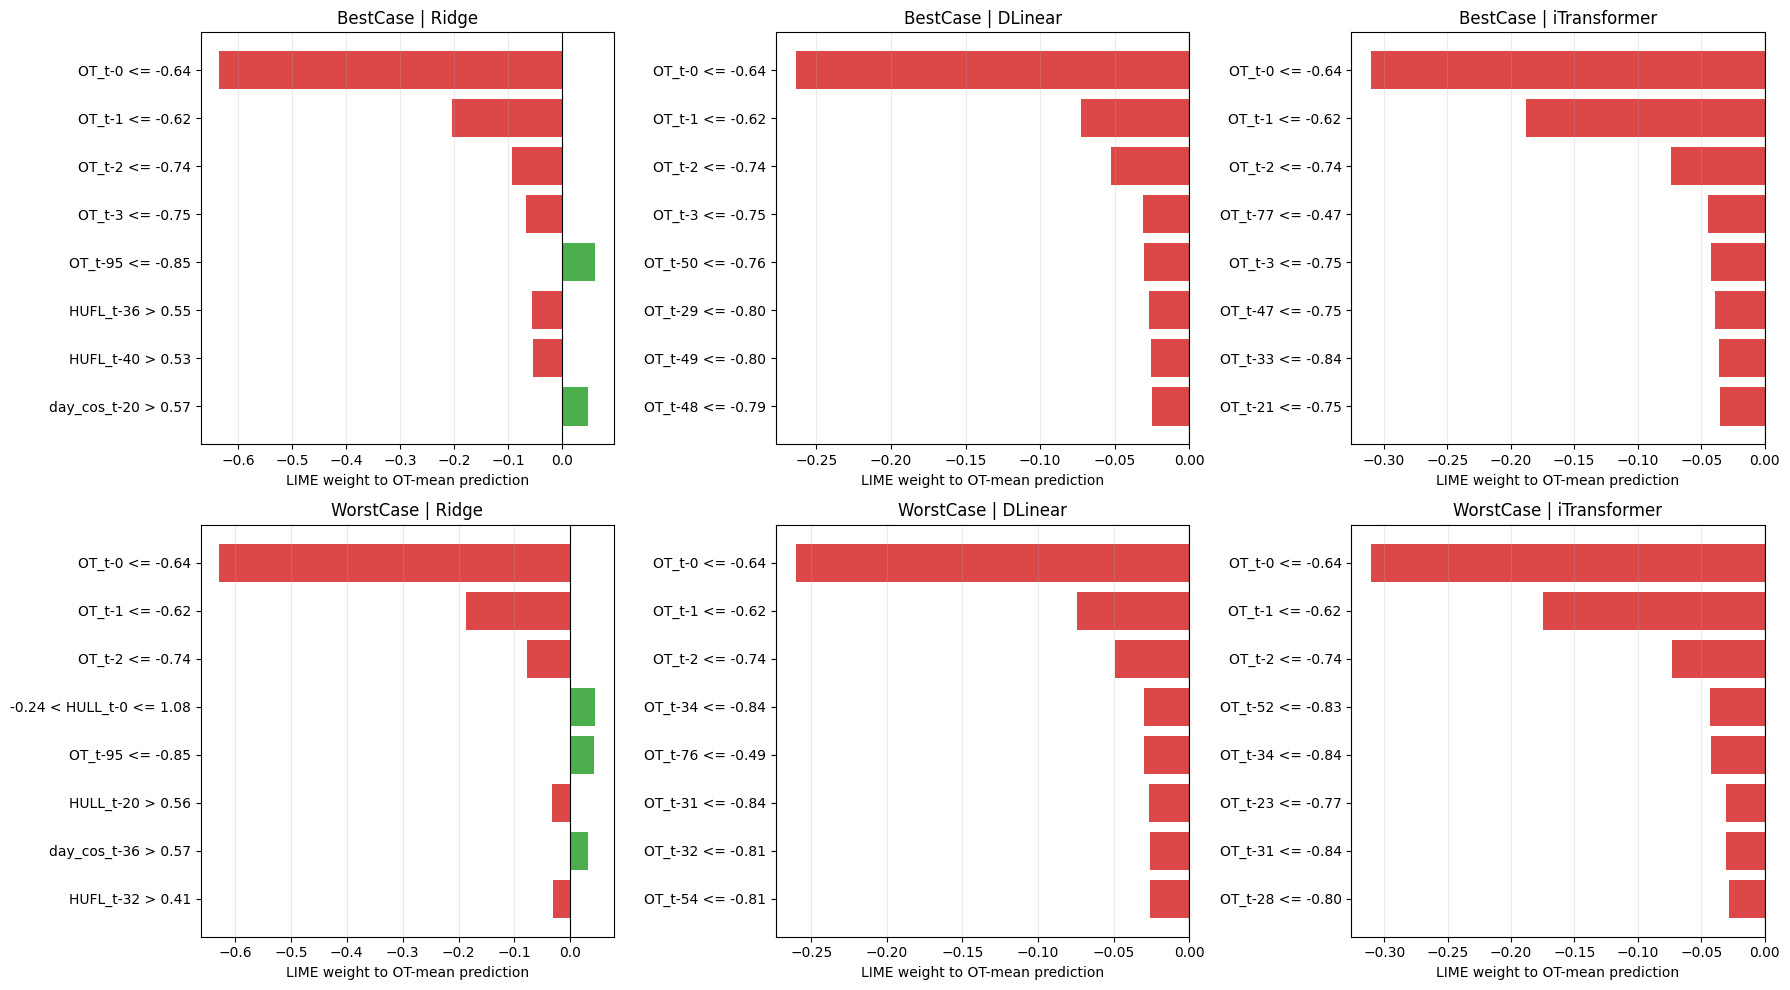

LIME completed | background=40 | num_features=10 | best_idx=6578 | worst_idx=6843


,Case,Model,TopRule,TopWeight
0,BestCase,Ridge,OT_t-0 <= -0.64,-0.634556
1,BestCase,DLinear,OT_t-0 <= -0.64,-0.263931
2,BestCase,iTransformer,OT_t-0 <= -0.64,-0.309999
3,WorstCase,Ridge,OT_t-0 <= -0.64,-0.627716
4,WorstCase,DLinear,OT_t-0 <= -0.64,-0.260273
5,WorstCase,iTransformer,OT_t-0 <= -0.64,-0.310466


In [38]:
# LIME local interpretability analysis for best and worst cases based on OT prediction error, across Ridge, DLinear, and iTransformer models.

try:
    from lime.lime_tabular import LimeTabularExplainer
    LIME_AVAILABLE = True
except Exception:
    LIME_AVAILABLE = False

if not LIME_AVAILABLE:
    print('LIME unavailable: local interpretability analysis skipped.')
else:
    required = [
        'X_train', 'X_test', 'feature_cols', 'seq_len', 'pred_len', 'target_dim',
        'target_cols', 'ridge_model', 'dlinear_model', 'itransformer_model'
    ]
    missing = [k for k in required if k not in globals()]
    if missing:
        print(f'LIME prerequisites missing: {missing}')
    else:
        seed = int(CONFIG.get('seed', 42))
        rng = np.random.RandomState(seed)

        feat_dim = int(X_test.shape[-1])
        X_train_flat_local = np.asarray(X_train, dtype=np.float32).reshape(len(X_train), -1)
        X_test_flat_local = np.asarray(X_test, dtype=np.float32).reshape(len(X_test), -1)

        bg_n = min(max(40, int(CONFIG.get('xai_kernel_background', 20))), len(X_train_flat_local))
        bg_idx = rng.choice(len(X_train_flat_local), size=bg_n, replace=False)

        feature_names_flat = []
        for t in range(int(seq_len)):
            lag = int(seq_len) - 1 - t
            for c in feature_cols:
                feature_names_flat.append(f'{c}_t-{lag}')

        ot_idx = int(target_cols.index('OT')) if 'OT' in target_cols else 0

        if 'itransformer_pred_inv' in globals() and 'itransformer_true_inv' in globals():
            y_pred_ref = np.asarray(itransformer_pred_inv, dtype=np.float32).reshape(-1, int(pred_len), int(target_dim))
            y_true_ref = np.asarray(itransformer_true_inv, dtype=np.float32).reshape(-1, int(pred_len), int(target_dim))
        else:
            y_pred_ref = np.asarray(itransformer_pred_scaled, dtype=np.float32).reshape(-1, int(pred_len), int(target_dim))
            y_true_ref = np.asarray(itransformer_true_scaled, dtype=np.float32).reshape(-1, int(pred_len), int(target_dim))

        ot_err = np.mean(np.abs(y_pred_ref[:, :, ot_idx] - y_true_ref[:, :, ot_idx]), axis=1)
        best_idx = int(np.argmin(ot_err))
        worst_idx = int(np.argmax(ot_err))
        case_map = {'BestCase': best_idx, 'WorstCase': worst_idx}

        def _predict_ot_mean_ridge(Xf):
            """Predict function for Ridge that returns mean OT across all horizons."""
            y = ridge_model.predict(np.asarray(Xf, dtype=np.float32))
            y = np.asarray(y, dtype=np.float32).reshape(len(Xf), int(pred_len), int(target_dim))
            return y[:, :, ot_idx].mean(axis=1)

        def _predict_ot_mean_dl(model_obj, Xf):
            """Predict function for Deep Learning models that returns mean OT across all horizons."""
            try:
                run_dev = next(model_obj.parameters()).device
            except Exception:
                run_dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
            x = np.asarray(Xf, dtype=np.float32).reshape(-1, int(seq_len), feat_dim)
            xt = torch.from_numpy(x).to(run_dev)
            with torch.no_grad():
                y = model_obj(xt).detach().cpu().numpy()
            y = np.asarray(y, dtype=np.float32).reshape(len(x), int(pred_len), int(target_dim))
            return y[:, :, ot_idx].mean(axis=1)

        pred_fn_map = {
            'Ridge': _predict_ot_mean_ridge,
            'DLinear': lambda Xf: _predict_ot_mean_dl(dlinear_model, Xf),
            'iTransformer': lambda Xf: _predict_ot_mean_dl(itransformer_model, Xf),
        }

        explainer = LimeTabularExplainer(
            training_data=X_train_flat_local[bg_idx],
            feature_names=feature_names_flat,
            mode='regression',
            discretize_continuous=True,
            random_state=seed
        )

        lime_tables = {}
        num_features = int(CONFIG.get('xai_lime_num_features', 10))
        model_order = ['Ridge', 'DLinear', 'iTransformer']
        case_order = ['BestCase', 'WorstCase']

        for cname, idx in case_map.items():
            x0 = X_test_flat_local[idx]
            for mname in model_order:
                pfn = pred_fn_map[mname]
                exp = explainer.explain_instance(
                    data_row=x0,
                    predict_fn=pfn,
                    num_features=num_features
                )
                rows = exp.as_list()
                df_l = pd.DataFrame(rows, columns=['FeatureRule', 'Weight'])
                df_l['AbsWeight'] = np.abs(df_l['Weight'])
                df_l = df_l.sort_values('AbsWeight', ascending=False).reset_index(drop=True)
                lime_tables[(cname, mname)] = df_l

        fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=False)
        for r, cname in enumerate(case_order):
            for c, mname in enumerate(model_order):
                ax = axes[r, c]
                tab = lime_tables[(cname, mname)].head(8).copy().iloc[::-1]
                colors = ['#2ca02c' if w > 0 else '#d62728' for w in tab['Weight']]
                ax.barh(tab['FeatureRule'], tab['Weight'], color=colors, alpha=0.85)
                ax.axvline(0.0, color='black', linewidth=0.8)
                ax.set_title(f'{cname} | {mname}')
                ax.set_xlabel('LIME weight to OT-mean prediction')
                ax.grid(axis='x', alpha=0.25)

        plt.tight_layout()
        plt.savefig(out_path('xai', 'xai_lime_local_extreme_windows_three_models.png'), dpi=150)
        plt.show()

        summary_rows = []
        for cname in case_order:
            for mname in model_order:
                top1 = lime_tables[(cname, mname)].iloc[0]
                summary_rows.append({
                    'Case': cname,
                    'Model': mname,
                    'TopRule': top1['FeatureRule'],
                    'TopWeight': float(top1['Weight'])
                })
        lime_summary = pd.DataFrame(summary_rows)
        print(f'LIME completed | background={bg_n} | num_features={num_features} | best_idx={best_idx} | worst_idx={worst_idx}')
        display(lime_summary)

# 8. Ablation Studies

This section runs controlled ablations to quantify the effect of key design choices on forecasting performance.
Each experiment isolates one factor at a time to preserve interpretability of conclusions.

# 8.1 Prediction Horizon Sensitivity

This subsection evaluates how performance changes as prediction horizon increases under consistent settings.
It characterizes short-term versus long-term degradation patterns across models.

In [39]:
# Phase 8.1 | Multi-Horizon Performance Benchmark & Ablation Study

required_vars = [
    'CONFIG', 'make_windows', 'X_scaled', 'y_scaled',
    'border1_train', 'border2_train', 'border1_val', 'border2_val',
    'border1_test', 'border2_test', 'target_dim'
 ]
required_funcs = ['regression_metrics', 'train_with_device_fallback', 'evaluate_loader']
missing_vars = [k for k in required_vars if k not in globals()]
missing_funcs = [k for k in required_funcs if k not in globals()]
if missing_vars or missing_funcs:
    print('Phase 8.1 prerequisites missing. Run previous phases first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_funcs:
        print('Missing functions:', missing_funcs)
else:
    cfg_sentinel = object()
    ot_global_idx = int(target_cols.index('OT')) if ('target_cols' in globals() and 'OT' in target_cols) else int(target_dim - 1)

    def _patch_config(**updates):
        """Temporarily patch CONFIG with given updates, returning backup copy."""
        backup = {}
        for k, v in updates.items():
            backup[k] = CONFIG[k] if k in CONFIG else cfg_sentinel
            CONFIG[k] = v
        return backup

    def _restore_config(backup):
        """Restore CONFIG from backup."""
        for k, v in backup.items():
            if v is cfg_sentinel:
                if k in CONFIG:
                    del CONFIG[k]
            else:
                CONFIG[k] = v

    def _resolve_dl_params(model_name):
        """Resolve best hyperparameters for a given DL model."""
        model_name = str(model_name)
        if 'DL_BEST_CONFIG' in globals() and isinstance(DL_BEST_CONFIG, dict):
            block = DL_BEST_CONFIG.get('DL-M96', {})
            if isinstance(block, dict) and model_name in block and isinstance(block[model_name], dict):
                return block[model_name].copy()
        if 'BEST_CONFIG' in globals() and isinstance(BEST_CONFIG, dict):
            block = BEST_CONFIG.get('DL-M96', {})
            if isinstance(block, dict) and model_name in block and isinstance(block[model_name], dict):
                return block[model_name].copy()
        return get_default_dl_params(model_name).copy()

    def _make_split_windows_with_target(feature_mat, target_mat, seq_len_local, pred_len_local):
        """Make windows with explicit target handling."""
        X_tr, y_tr, _ = make_windows(feature_mat, target_mat, border1_train, border2_train, seq_len_local, pred_len_local)
        X_va, y_va, _ = make_windows(feature_mat, target_mat, border1_val, border2_val, seq_len_local, pred_len_local)
        X_te, y_te, _ = make_windows(feature_mat, target_mat, border1_test, border2_test, seq_len_local, pred_len_local)
        if len(X_tr) == 0 or len(X_va) == 0 or len(X_te) == 0:
            raise ValueError(f'Empty windows for seq_len={seq_len_local}, pred_len={pred_len_local}')
        return X_tr, y_tr, X_va, y_va, X_te, y_te

    def _compute_metrics_with_ot(y_true_flat, y_pred_flat, pred_len_local, target_dim_local, ot_pos_in_target):
        """Compute standard and OT-specific metrics."""
        metrics, y_true, y_pred = regression_metrics(y_true_flat, y_pred_flat)
        y_true = np.asarray(y_true, dtype=np.float32)
        y_pred = np.asarray(y_pred, dtype=np.float32)
        if y_true.shape != y_pred.shape:
            raise ValueError(f'Shape mismatch: y_true={y_true.shape}, y_pred={y_pred.shape}')
        expected_dim = int(pred_len_local) * int(target_dim_local)
        if y_true.ndim != 2 or y_true.shape[1] != expected_dim:
            raise ValueError(f'Flatten dim mismatch: got {y_true.shape}, expected second dim={expected_dim}')
        y_true_3d = y_true.reshape(-1, int(pred_len_local), int(target_dim_local))
        y_pred_3d = y_pred.reshape(-1, int(pred_len_local), int(target_dim_local))
        ot_pos = int(np.clip(ot_pos_in_target, 0, int(target_dim_local) - 1))
        ot_true = y_true_3d[:, :, ot_pos].reshape(-1)
        ot_pred = y_pred_3d[:, :, ot_pos].reshape(-1)
        metrics['OT_MAE'] = float(mean_absolute_error(ot_true, ot_pred))
        return metrics

    def _run_ridge(X_tr, y_tr, X_te, y_te, pred_len_local, target_dim_local, ot_pos_in_target):
        """Run Ridge regression and return metrics."""
        model = Ridge(alpha=float(CONFIG.get('ridge_alpha', 100.0)), solver='svd')
        model.fit(X_tr.reshape(len(X_tr), -1), y_tr)
        pred = model.predict(X_te.reshape(len(X_te), -1)).astype(np.float32)
        return _compute_metrics_with_ot(y_te, pred, pred_len_local, target_dim_local, ot_pos_in_target)

    def _run_dl(model_name, params, X_tr, y_tr, X_va, y_va, X_te, y_te, seq_len_local, pred_len_local, target_dim_local, ot_pos_in_target):
        """Run deep learning model and return metrics."""
        input_dim_local = int(X_tr.shape[-1])
        output_dim_local = int(pred_len_local * target_dim_local)

        try:
            model, _, _, _, test_loader_local, run_device = train_with_device_fallback(
                model_name=model_name,
                params=params,
                X_tr=X_tr, y_tr=y_tr,
                X_va=X_va, y_va=y_va,
                X_te=X_te, y_te=y_te,
                input_dim=input_dim_local,
                output_dim=output_dim_local,
                seq_len=seq_len_local,
                pred_len=pred_len_local,
                target_dim=target_dim_local
            )
        except RuntimeError as e:
            msg = str(e).lower()
            if ('dataloader worker' in msg) or ('exited unexpectedly' in msg):
                print(f'{model_name}: DataLoader worker crash detected, retry with dl_num_workers=0')
                backup_loader_cfg = _patch_config(dl_num_workers=0, dl_pin_memory=False)
                try:
                    model, _, _, _, test_loader_local, run_device = train_with_device_fallback(
                        model_name=model_name,
                        params=params,
                        X_tr=X_tr, y_tr=y_tr,
                        X_va=X_va, y_va=y_va,
                        X_te=X_te, y_te=y_te,
                        input_dim=input_dim_local,
                        output_dim=output_dim_local,
                        seq_len=seq_len_local,
                        pred_len=pred_len_local,
                        target_dim=target_dim_local
                    )
                finally:
                    _restore_config(backup_loader_cfg)
            else:
                raise

        _, pred_scaled, true_scaled = evaluate_loader(model, test_loader_local, nn.SmoothL1Loss(beta=0.5), run_device)
        return _compute_metrics_with_ot(true_scaled, pred_scaled, pred_len_local, target_dim_local, ot_pos_in_target)

    seq_len_local = 96
    pred_len_grid = [24, 48, 96, 288, 672]
    horizon_rows = []

    for pred_len_local in pred_len_grid:
        for model_name in ['Ridge', 'iTransformer', 'DLinear']:
            backup_cfg = _patch_config(seq_len=seq_len_local, pred_len=int(pred_len_local))
            try:
                X_tr, y_tr, X_va, y_va, X_te, y_te = _make_split_windows_with_target(X_scaled, y_scaled, seq_len_local, pred_len_local)
                if model_name == 'Ridge':
                    metrics = _run_ridge(
                        X_tr, y_tr, X_te, y_te,
                        pred_len_local=pred_len_local,
                        target_dim_local=int(target_dim),
                        ot_pos_in_target=ot_global_idx
                    )
                else:
                    params = _resolve_dl_params(model_name)
                    metrics = _run_dl(
                        model_name=model_name,
                        params=params,
                        X_tr=X_tr, y_tr=y_tr,
                        X_va=X_va, y_va=y_va,
                        X_te=X_te, y_te=y_te,
                        seq_len_local=seq_len_local,
                        pred_len_local=pred_len_local,
                        target_dim_local=int(target_dim),
                        ot_pos_in_target=ot_global_idx
                    )

                horizon_rows.append({
                    'Experiment': '8.1-Horizon',
                    'Model': model_name,
                    'PredLen': int(pred_len_local),
                    'SeqLen': int(seq_len_local),
                    'InputDim': int(X_tr.shape[-1]),
                    'TargetDim': int(target_dim),
                    'NTrain': int(X_tr.shape[0]),
                    'NVal': int(X_va.shape[0]),
                    'NTest': int(X_te.shape[0]),
                    'MAE': float(metrics['MAE']),
                    'OT_MAE': float(metrics['OT_MAE']),
                    'MSE': float(metrics['MSE']),
                    'RMSE': float(metrics['RMSE']),
                    'Status': 'ok',
                    'Error': ''
                })
                print(f'[8.1] {model_name} | pred_len={pred_len_local} | MAE={metrics["MAE"]:.6f} | OT_MAE={metrics["OT_MAE"]:.6f}')
            except Exception as e:
                horizon_rows.append({
                    'Experiment': '8.1-Horizon',
                    'Model': model_name,
                    'PredLen': int(pred_len_local),
                    'SeqLen': int(seq_len_local),
                    'InputDim': int(X_tr.shape[-1]),
                    'TargetDim': int(target_dim),
                    'NTrain': int(X_tr.shape[0]),
                    'NVal': int(X_va.shape[0]),
                    'NTest': int(X_te.shape[0]),
                    'MAE': np.nan,
                    'OT_MAE': np.nan,
                    'MSE': np.nan,
                    'RMSE': np.nan,
                    'Status': 'failed',
                    'Error': str(e)[:280]
                })
                print(f'[8.1][FAIL] {model_name} | pred_len={pred_len_local} | {e}')
            finally:
                _restore_config(backup_cfg)

    ablation81_df = pd.DataFrame(horizon_rows).sort_values(['Model', 'PredLen']).reset_index(drop=True)
    ablation81_df['ImprovementPct_vs96'] = np.nan
    ablation81_df['OT_ImprovementPct_vs96'] = np.nan
    for model_name in ablation81_df['Model'].unique():
        msk_ok = (ablation81_df['Model'] == model_name) & (ablation81_df['Status'] == 'ok')
        base_row = ablation81_df[msk_ok & (ablation81_df['PredLen'] == 96)]
        if len(base_row) > 0:
            base_mae = float(base_row.iloc[0]['MAE'])
            base_ot_mae = float(base_row.iloc[0]['OT_MAE'])
            ablation81_df.loc[msk_ok, 'ImprovementPct_vs96'] = (base_mae - ablation81_df.loc[msk_ok, 'MAE']) / (base_mae + 1e-8) * 100.0
            ablation81_df.loc[msk_ok, 'OT_ImprovementPct_vs96'] = (base_ot_mae - ablation81_df.loc[msk_ok, 'OT_MAE']) / (base_ot_mae + 1e-8) * 100.0

    expected_pairs = pd.MultiIndex.from_product([['Ridge', 'iTransformer', 'DLinear'], pred_len_grid], names=['Model', 'PredLen'])
    observed_pairs = pd.MultiIndex.from_frame(ablation81_df[['Model', 'PredLen']].drop_duplicates())
    missing_pairs = expected_pairs.difference(observed_pairs)
    if len(missing_pairs) > 0:
        print('8.1 warning: missing model-horizon combinations:', [tuple(x) for x in missing_pairs.tolist()])

    ok_mask = ablation81_df['Status'] == 'ok'
    finite_mask = np.isfinite(ablation81_df['MAE']) & np.isfinite(ablation81_df['OT_MAE']) & np.isfinite(ablation81_df['MSE']) & np.isfinite(ablation81_df['RMSE'])
    if bool((ok_mask & (~finite_mask)).any()):
        print('8.1 warning: some rows are Status=ok but contain non-finite metrics.')

    print('8.1 result table (model outputs):')
    display(ablation81_df)

[8.1] Ridge | pred_len=24 | MAE=0.339837 | OT_MAE=0.088038
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.24384, val=0.21397
iTransformer epoch 05: train=0.16358, val=0.16920
iTransformer epoch 10: train=0.15057, val=0.16477
[8.1] iTransformer | pred_len=24 | MAE=0.297621 | OT_MAE=0.091342
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.20601, val=0.19848
DLinear epoch 05: train=0.15492, val=0.16933
[8.1] DLinear | pred_len=24 | MAE=0.304996 | OT_MAE=0.088666
[8.1] Ridge | pred_len=48 | MAE=0.409320 | OT_MAE=0.119100
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.27108, val=0.24733
iTransformer epoch 05: train=0.20453, val=0.20808
iTransformer epoch 10: train=0.19113, val=0.20184
[8.1] iTransformer | pred_len=48 | MAE=0.334040 | OT_MAE=0.117747
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.22826, val=0.22747
DLinear epoch 05: tr

,Experiment,Model,PredLen,SeqLen,InputDim,TargetDim,NTrain,NVal,NTest,MAE,OT_MAE,MSE,RMSE,Status,Error,ImprovementPct_vs96,OT_ImprovementPct_vs96
0,8.1-Horizon,DLinear,24,96,17,7,34441,11497,11497,0.304996,0.088666,0.244639,0.494610,ok,,14.823660,35.984735
1,8.1-Horizon,DLinear,48,96,17,7,34417,11473,11473,0.341407,0.117195,0.307729,0.554733,ok,,4.655248,15.387771
2,8.1-Horizon,DLinear,96,96,17,7,34369,11425,11425,0.358076,0.138508,0.338869,0.582124,ok,,0.000000,0.000000
3,8.1-Horizon,DLinear,288,96,17,7,34177,11233,11233,0.394705,0.184956,0.404361,0.635894,ok,,-10.229427,-33.534548
4,8.1-Horizon,DLinear,672,96,17,7,33793,10849,10849,0.434065,0.218185,0.477003,0.690654,ok,,-21.221290,-57.524866
5,8.1-Horizon,Ridge,24,96,17,7,34441,11497,11497,0.339837,0.088038,0.270594,0.520187,ok,,24.286836,42.272330
6,8.1-Horizon,Ridge,48,96,17,7,34417,11473,11473,0.409320,0.119100,0.381699,0.617818,ok,,8.806563,21.904326
7,8.1-Horizon,Ridge,96,96,17,7,34369,11425,11425,0.448848,0.152506,0.440454,0.663667,ok,,0.000000,0.000000
8,8.1-Horizon,Ridge,288,96,17,7,34177,11233,11233,0.502443,0.235904,0.513751,0.716764,ok,,-11.940720,-54.685333
9,8.1-Horizon,Ridge,672,96,17,7,33793,10849,10849,0.586829,0.273883,0.660512,0.812719,ok,,-30.741323,-79.588665


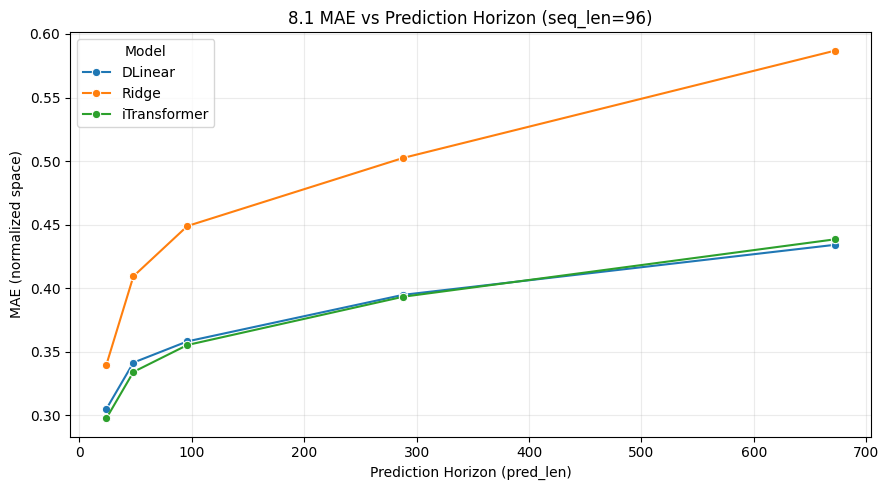

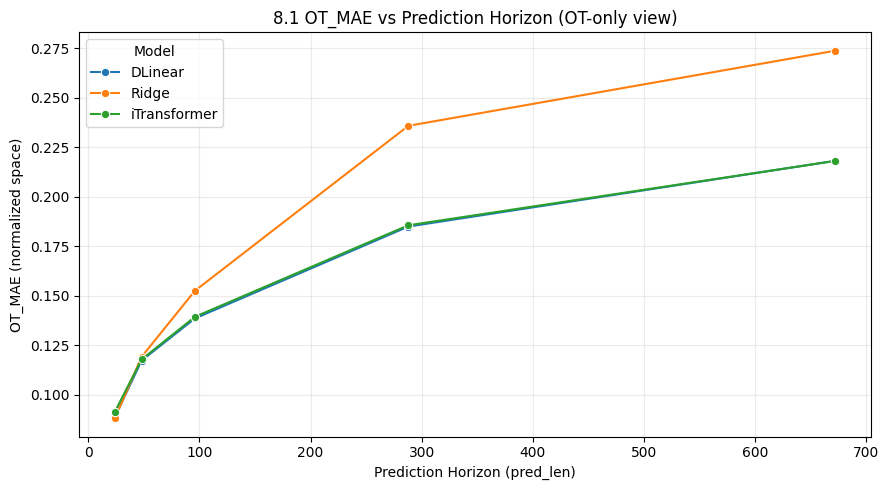

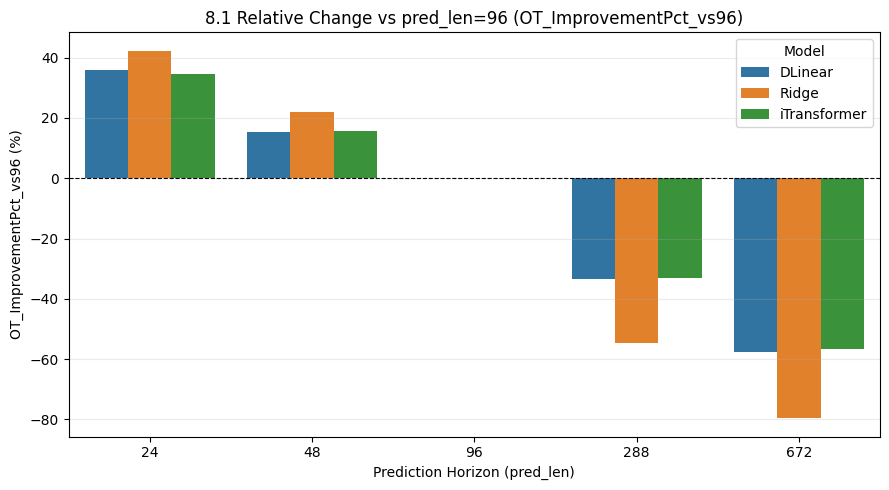

8.1 interpretability summary (lower degradation is better horizon robustness):


,Model,MAE@24,MAE@96,MAE@672,OT_MAE@24,OT_MAE@96,OT_MAE@672,Slope(MAE/pred_step),Degradation96to672(%),OT_Degradation96to672(%)
2,iTransformer,0.297621,0.355231,0.438377,0.091342,0.139333,0.218143,0.000188,23.406133,56.562403
0,DLinear,0.304996,0.358076,0.434065,0.088666,0.138508,0.218185,0.000171,21.221290,57.524866
1,Ridge,0.339837,0.448848,0.586829,0.088038,0.152506,0.273883,0.000322,30.741323,79.588665


In [40]:
# Horizon sensitivity visualization and interpretability analysis
if 'ablation81_df' not in globals() or len(ablation81_df) == 0:
    print('ablation81_df is missing. Run 8.1 Cell 1 first.')
else:
    ok_df = ablation81_df[ablation81_df['Status'] == 'ok'].copy() if 'Status' in ablation81_df.columns else ablation81_df.copy()
    if len(ok_df) == 0:
        print('No successful 8.1 runs available for analysis.')
    else:
        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='PredLen', y='MAE', hue='Model', marker='o')
        plt.title('8.1 MAE vs Prediction Horizon (seq_len=96)')
        plt.xlabel('Prediction Horizon (pred_len)')
        plt.ylabel('MAE (normalized space)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

        if 'OT_MAE' in ok_df.columns:
            plt.figure(figsize=(9, 5))
            sns.lineplot(data=ok_df, x='PredLen', y='OT_MAE', hue='Model', marker='o')
            plt.title('8.1 OT_MAE vs Prediction Horizon (OT-only view)')
            plt.xlabel('Prediction Horizon (pred_len)')
            plt.ylabel('OT_MAE (normalized space)')
            plt.grid(alpha=0.25)
            plt.tight_layout()
            plt.show()

        y_col = 'OT_ImprovementPct_vs96' if 'OT_ImprovementPct_vs96' in ok_df.columns else 'ImprovementPct_vs96'
        plt.figure(figsize=(9, 5))
        sns.barplot(data=ok_df, x='PredLen', y=y_col, hue='Model')
        plt.axhline(0.0, color='black', linewidth=0.8, linestyle='--')
        plt.title(f'8.1 Relative Change vs pred_len=96 ({y_col})')
        plt.xlabel('Prediction Horizon (pred_len)')
        plt.ylabel(f'{y_col} (%)')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.show()

        explain_rows = []
        for model_name, grp in ok_df.groupby('Model'):
            grp = grp.sort_values('PredLen')
            mae_24 = float(grp.loc[grp['PredLen'] == 24, 'MAE'].iloc[0]) if (grp['PredLen'] == 24).any() else np.nan
            mae_96 = float(grp.loc[grp['PredLen'] == 96, 'MAE'].iloc[0]) if (grp['PredLen'] == 96).any() else np.nan
            mae_672 = float(grp.loc[grp['PredLen'] == 672, 'MAE'].iloc[0]) if (grp['PredLen'] == 672).any() else np.nan
            ot_mae_24 = float(grp.loc[grp['PredLen'] == 24, 'OT_MAE'].iloc[0]) if ('OT_MAE' in grp.columns and (grp['PredLen'] == 24).any()) else np.nan
            ot_mae_96 = float(grp.loc[grp['PredLen'] == 96, 'OT_MAE'].iloc[0]) if ('OT_MAE' in grp.columns and (grp['PredLen'] == 96).any()) else np.nan
            ot_mae_672 = float(grp.loc[grp['PredLen'] == 672, 'OT_MAE'].iloc[0]) if ('OT_MAE' in grp.columns and (grp['PredLen'] == 672).any()) else np.nan
            slope = np.polyfit(grp['PredLen'].values, grp['MAE'].values, 1)[0] if len(grp) >= 2 else np.nan
            degrade_96_to_672 = ((mae_672 - mae_96) / (mae_96 + 1e-8) * 100.0) if np.isfinite(mae_96) and np.isfinite(mae_672) else np.nan
            ot_degrade_96_to_672 = ((ot_mae_672 - ot_mae_96) / (ot_mae_96 + 1e-8) * 100.0) if np.isfinite(ot_mae_96) and np.isfinite(ot_mae_672) else np.nan
            explain_rows.append({
                'Model': model_name,
                'MAE@24': mae_24,
                'MAE@96': mae_96,
                'MAE@672': mae_672,
                'OT_MAE@24': ot_mae_24,
                'OT_MAE@96': ot_mae_96,
                'OT_MAE@672': ot_mae_672,
                'Slope(MAE/pred_step)': slope,
                'Degradation96to672(%)': degrade_96_to_672,
                'OT_Degradation96to672(%)': ot_degrade_96_to_672
            })

        ablation81_explain_df = pd.DataFrame(explain_rows).sort_values('OT_Degradation96to672(%)')
        print('8.1 interpretability summary (lower degradation is better horizon robustness):')
        display(ablation81_explain_df)

# 8.2 Coupling Strength Effect

This subsection compares M7->M7, M7->OT1, and OT1->OT1 settings to quantify dependence on cross-variable coupling.
It includes OT-focused metrics for fair cross-mode interpretation.

OT channel alignment check (for single-target DL): True
[8.2] M7->M7 | Ridge | MAE=0.431907 | OT_MAE=0.166903
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.28612, val=0.27482
iTransformer epoch 05: train=0.22632, val=0.23373
iTransformer epoch 10: train=0.21570, val=0.22874
[8.2] M7->M7 | iTransformer | MAE=0.359644 | OT_MAE=0.138648
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.24158, val=0.24660
DLinear epoch 05: train=0.21501, val=0.23629
[8.2] M7->M7 | DLinear | MAE=0.357509 | OT_MAE=0.138993
[8.2] M7->OT1 | Ridge | MAE=0.166903 | OT_MAE=0.166903
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.10468, val=0.05468
iTransformer epoch 05: train=0.08533, val=0.05056
iTransformer epoch 10: train=0.08189, val=0.05011
[8.2] M7->OT1 | iTransformer | MAE=0.126889 | OT_MAE=0.126889
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.09385,

,Experiment,CouplingMode,Model,SeqLen,PredLen,InputDim,TargetDim,NTrain,NVal,NTest,OTAsFirstChannel,MAE,OT_MAE,MSE,RMSE,Status,Error,ImprovementPct_vs_M7toM7,OT_ImprovementPct_vs_M7toM7
0,.2-Coupling,M7->M7,DLinear,96,96,7,7,34369,11425,11425,False,0.357509,0.138993,0.337998,0.581376,ok,,0.000000,0.000000
1,.2-Coupling,M7->OT1,DLinear,96,96,7,1,34369,11425,11425,True,0.127018,0.127018,0.029193,0.170861,ok,,64.471293,8.615287
2,.2-Coupling,OT1->OT1,DLinear,96,96,1,1,34369,11425,11425,True,0.126804,0.126804,0.029145,0.170719,ok,,64.531309,8.769656
3,.2-Coupling,M7->M7,Ridge,96,96,7,7,34369,11425,11425,False,0.431907,0.166903,0.422509,0.650007,ok,,0.000000,0.000000
4,.2-Coupling,M7->OT1,Ridge,96,96,7,1,34369,11425,11425,True,0.166903,0.166903,0.048146,0.219423,ok,,61.356814,0.000000
5,.2-Coupling,OT1->OT1,Ridge,96,96,1,1,34369,11425,11425,True,0.130333,0.130333,0.031644,0.177887,ok,,69.823937,21.911038
6,.2-Coupling,M7->M7,iTransformer,96,96,7,7,34369,11425,11425,False,0.359644,0.138648,0.336453,0.580046,ok,,0.000000,0.000000
7,.2-Coupling,M7->OT1,iTransformer,96,96,7,1,34369,11425,11425,True,0.126889,0.126889,0.028727,0.169491,ok,,64.718092,8.481427
8,.2-Coupling,OT1->OT1,iTransformer,96,96,1,1,34369,11425,11425,True,0.128257,0.128257,0.029630,0.172135,ok,,64.337873,7.495167


Fairness note: MAE is retained for completeness, but cross-mode comparison should use OT_MAE.


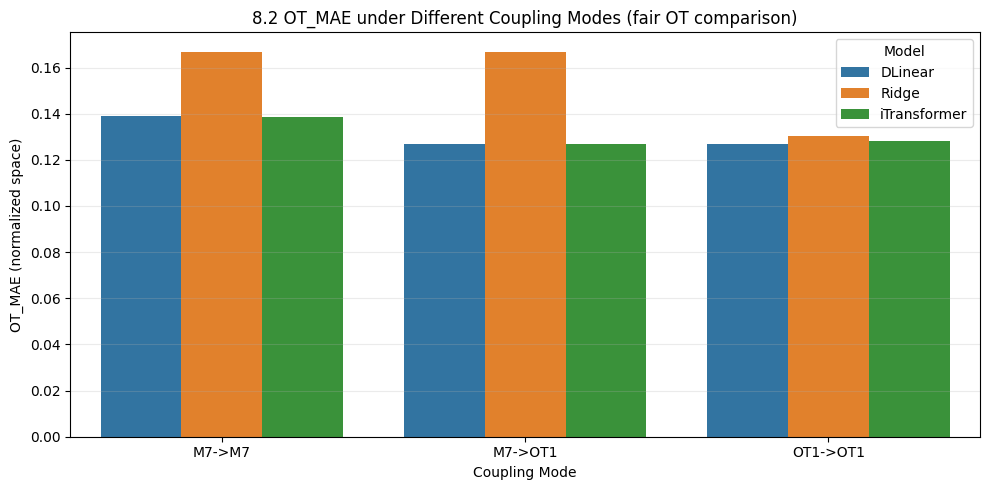

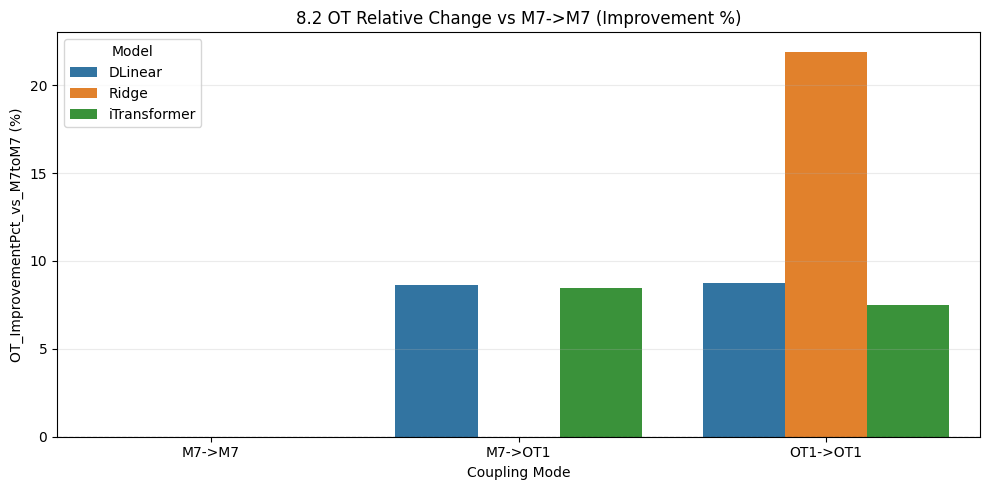

8.2 interpretability summary (OT-only fairness view):


,Model,OT_MAE_M7toM7,OT_MAE_M7toOT1,OT_MAE_OT1toOT1,Delta_OT1toOT1_vs_M7toOT1(%)
0,DLinear,0.138993,0.127018,0.126804,0.168922
1,Ridge,0.166903,0.166903,0.130333,21.911038
2,iTransformer,0.138648,0.126889,0.128257,-1.077661


In [41]:
# 8.2 | Multivariate coupling strength ablation
required_vars = ['X_phys_scaled', 'y_scaled', 'target_dim']
required_helpers = ['_patch_config', '_restore_config', '_resolve_dl_params', '_make_split_windows_with_target', '_run_ridge', '_run_dl']
missing_vars = [k for k in required_vars if k not in globals()]
missing_helpers = [k for k in required_helpers if k not in globals()]
if missing_vars or missing_helpers:
    print('8.2 prerequisites missing. Run previous phases first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_helpers:
        print('Missing helper functions (run 8.1 Cell 1 first):', missing_helpers)
else:
    if 'target_cols' in globals() and ('OT' in target_cols):
        ot_idx = int(target_cols.index('OT'))
    else:
        ot_idx = int(target_dim - 1)

    seq_len_local = 96
    pred_len_local = 96
    coupling_rows = []

    # For target_dim=1 DL modes, ensure OT channel is first input channel.
    ot_first_order = [ot_idx] + [i for i in range(X_phys_scaled.shape[1]) if i != ot_idx]
    X_phys_ot_first = X_phys_scaled[:, ot_first_order]
    ot_aligned = np.allclose(X_phys_ot_first[:, 0], X_phys_scaled[:, ot_idx])
    print(f'OT channel alignment check (for single-target DL): {ot_aligned}')

    coupling_settings = [
        {
            'CouplingMode': 'M7->M7',
            'feature_mat': X_phys_scaled,
            'target_mat': y_scaled,
            'target_dim_local': int(target_dim),
            'ot_as_first_channel': False,
            'ot_pos_in_target': int(ot_idx)
        },
        {
            'CouplingMode': 'M7->OT1',
            'feature_mat': X_phys_ot_first,
            'target_mat': y_scaled[:, [ot_idx]],
            'target_dim_local': 1,
            'ot_as_first_channel': True,
            'ot_pos_in_target': 0
        },
        {
            'CouplingMode': 'OT1->OT1',
            'feature_mat': X_phys_scaled[:, [ot_idx]],
            'target_mat': y_scaled[:, [ot_idx]],
            'target_dim_local': 1,
            'ot_as_first_channel': True,
            'ot_pos_in_target': 0
        }
    ]

    for setting in coupling_settings:
        mode = setting['CouplingMode']
        feat_mat = setting['feature_mat']
        tgt_mat = setting['target_mat']
        target_dim_local = int(setting['target_dim_local'])
        ot_first_flag = bool(setting['ot_as_first_channel'])
        ot_pos_in_target = int(setting['ot_pos_in_target'])

        backup_cfg = _patch_config(seq_len=seq_len_local, pred_len=pred_len_local)
        try:
            X_tr, y_tr, X_va, y_va, X_te, y_te = _make_split_windows_with_target(
                feat_mat, tgt_mat, seq_len_local, pred_len_local
            )

            for model_name in ['Ridge', 'iTransformer', 'DLinear']:
                try:
                    if model_name == 'Ridge':
                        metrics = _run_ridge(
                            X_tr, y_tr, X_te, y_te,
                            pred_len_local=pred_len_local,
                            target_dim_local=target_dim_local,
                            ot_pos_in_target=ot_pos_in_target
                        )
                    else:
                        params = _resolve_dl_params(model_name)
                        metrics = _run_dl(
                            model_name=model_name,
                            params=params,
                            X_tr=X_tr, y_tr=y_tr,
                            X_va=X_va, y_va=y_va,
                            X_te=X_te, y_te=y_te,
                            seq_len_local=seq_len_local,
                            pred_len_local=pred_len_local,
                            target_dim_local=target_dim_local,
                            ot_pos_in_target=ot_pos_in_target
                        )

                    coupling_rows.append({
                        'Experiment': '.2-Coupling',
                        'CouplingMode': mode,
                        'Model': model_name,
                        'SeqLen': seq_len_local,
                        'PredLen': pred_len_local,
                        'InputDim': int(X_tr.shape[-1]),
                        'TargetDim': int(target_dim_local),
                        'NTrain': int(X_tr.shape[0]),
                        'NVal': int(X_va.shape[0]),
                        'NTest': int(X_te.shape[0]),
                        'OTAsFirstChannel': ot_first_flag,
                        'MAE': float(metrics['MAE']),
                        'OT_MAE': float(metrics['OT_MAE']),
                        'MSE': float(metrics['MSE']),
                        'RMSE': float(metrics['RMSE']),
                        'Status': 'ok',
                        'Error': ''
                    })
                    print(f'[8.2] {mode} | {model_name} | MAE={metrics["MAE"]:.6f} | OT_MAE={metrics["OT_MAE"]:.6f}')
                except Exception as e:
                    coupling_rows.append({
                        'Experiment': '8.2-Coupling',
                        'CouplingMode': mode,
                        'Model': model_name,
                        'SeqLen': seq_len_local,
                        'PredLen': pred_len_local,
                        'InputDim': int(X_tr.shape[-1]),
                        'TargetDim': int(target_dim_local),
                        'NTrain': int(X_tr.shape[0]),
                        'NVal': int(X_va.shape[0]),
                        'NTest': int(X_te.shape[0]),
                        'OTAsFirstChannel': ot_first_flag,
                        'MAE': np.nan,
                        'OT_MAE': np.nan,
                        'MSE': np.nan,
                        'RMSE': np.nan,
                        'Status': 'failed',
                        'Error': str(e)[:280]
                    })
                    print(f'[8.2][FAIL] {mode} | {model_name} | {e}')
        finally:
            _restore_config(backup_cfg)

    ablation82_df = pd.DataFrame(coupling_rows).sort_values(['Model', 'CouplingMode']).reset_index(drop=True)
    ablation82_df['ImprovementPct_vs_M7toM7'] = np.nan
    ablation82_df['OT_ImprovementPct_vs_M7toM7'] = np.nan
    for model_name in ablation82_df['Model'].unique():
        msk_ok = (ablation82_df['Model'] == model_name) & (ablation82_df['Status'] == 'ok')
        base_row = ablation82_df[msk_ok & (ablation82_df['CouplingMode'] == 'M7->M7')]
        if len(base_row) > 0:
            base_mae = float(base_row.iloc[0]['MAE'])
            base_ot_mae = float(base_row.iloc[0]['OT_MAE'])
            ablation82_df.loc[msk_ok, 'ImprovementPct_vs_M7toM7'] = (base_mae - ablation82_df.loc[msk_ok, 'MAE']) / (base_mae + 1e-8) * 100.0
            ablation82_df.loc[msk_ok, 'OT_ImprovementPct_vs_M7toM7'] = (base_ot_mae - ablation82_df.loc[msk_ok, 'OT_MAE']) / (base_ot_mae + 1e-8) * 100.0

    expected_pairs = pd.MultiIndex.from_product([['Ridge', 'iTransformer', 'DLinear'], ['M7->M7', 'M7->OT1', 'OT1->OT1']], names=['Model', 'CouplingMode'])
    observed_pairs = pd.MultiIndex.from_frame(ablation82_df[['Model', 'CouplingMode']].drop_duplicates())
    missing_pairs = expected_pairs.difference(observed_pairs)
    if len(missing_pairs) > 0:
        print('8.2 warning: missing model-mode combinations:', [tuple(x) for x in missing_pairs.tolist()])

    ok_mask = ablation82_df['Status'] == 'ok'
    finite_mask = np.isfinite(ablation82_df['MAE']) & np.isfinite(ablation82_df['OT_MAE']) & np.isfinite(ablation82_df['MSE']) & np.isfinite(ablation82_df['RMSE'])
    if bool((ok_mask & (~finite_mask)).any()):
        print('8.2 warning: some rows are Status=ok but contain non-finite metrics.')

    print('8.2 result table: coupling-strength ablation')
    display(ablation82_df)
    print('Fairness note: MAE is retained for completeness, but cross-mode comparison should use OT_MAE.')

    ok_df = ablation82_df[ablation82_df['Status'] == 'ok'].copy()
    if len(ok_df) > 0:
        # Fair cross-mode comparison uses OT_MAE because OT is shared across M7->M7 / M7->OT1 / OT1->OT1.

        plt.figure(figsize=(10, 5))
        sns.barplot(data=ok_df, x='CouplingMode', y='OT_MAE', hue='Model')
        plt.title('8.2 OT_MAE under Different Coupling Modes (fair OT comparison)')
        plt.xlabel('Coupling Mode')
        plt.ylabel('OT_MAE (normalized space)')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(10, 5))
        sns.barplot(data=ok_df, x='CouplingMode', y='OT_ImprovementPct_vs_M7toM7', hue='Model')
        plt.axhline(0.0, color='black', linewidth=0.8, linestyle='--')
        plt.title('8.2 OT Relative Change vs M7->M7 (Improvement %)')
        plt.xlabel('Coupling Mode')
        plt.ylabel('OT_ImprovementPct_vs_M7toM7 (%)')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.show()

    coupling_interp = []
    for model_name, grp in ablation82_df[ablation82_df['Status'] == 'ok'].groupby('Model'):
        grp = grp.set_index('CouplingMode')
        m7_ot_mae = float(grp.loc['M7->OT1', 'OT_MAE']) if 'M7->OT1' in grp.index else np.nan
        ot_ot_mae = float(grp.loc['OT1->OT1', 'OT_MAE']) if 'OT1->OT1' in grp.index else np.nan
        full_ot_mae = float(grp.loc['M7->M7', 'OT_MAE']) if 'M7->M7' in grp.index else np.nan
        coupling_interp.append({
            'Model': model_name,
            'OT_MAE_M7toM7': full_ot_mae,
            'OT_MAE_M7toOT1': m7_ot_mae,
            'OT_MAE_OT1toOT1': ot_ot_mae,
            'Delta_OT1toOT1_vs_M7toOT1(%)': ((m7_ot_mae - ot_ot_mae) / (m7_ot_mae + 1e-8) * 100.0) if np.isfinite(m7_ot_mae) and np.isfinite(ot_ot_mae) else np.nan
        })
    ablation82_explain_df = pd.DataFrame(coupling_interp)
    print('8.2 interpretability summary (OT-only fairness view):')
    display(ablation82_explain_df)

# 8.3 Sequence Length Sensitivity

This subsection tests how encoder context length affects forecasting quality with a fixed prediction horizon.
It identifies useful history range and diminishing-return behavior by model.

[8.3] seq_len=48 | Ridge | MAE=0.489263 | OT_MAE=0.152825
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.31151, val=0.33855
iTransformer epoch 05: train=0.25753, val=0.29876
iTransformer epoch 10: train=0.24576, val=0.29057
[8.3] seq_len=48 | iTransformer | MAE=0.429832 | OT_MAE=0.140503
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.28803, val=0.33044
DLinear epoch 05: train=0.25130, val=0.30100
[8.3] seq_len=48 | DLinear | MAE=0.434821 | OT_MAE=0.134385
[8.3] seq_len=96 | Ridge | MAE=0.448848 | OT_MAE=0.152506
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.28801, val=0.27866
iTransformer epoch 05: train=0.22899, val=0.23671
iTransformer epoch 10: train=0.21729, val=0.23109
[8.3] seq_len=96 | iTransformer | MAE=0.355487 | OT_MAE=0.139131
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.24158, val=0.24622
DLinear epoch 05: train=0

,Experiment,Model,SeqLen,PredLen,InputDim,TargetDim,NTrain,NVal,NTest,MAE,OT_MAE,MSE,RMSE,Status,Error,ImprovementPct_vs96,OT_ImprovementPct_vs96
0,8.3-SeqLen,DLinear,48,96,17,7,34417,11473,11473,0.434821,0.134385,0.517487,0.719365,ok,,-21.516826,3.064163
1,8.3-SeqLen,DLinear,96,96,17,7,34369,11425,11425,0.357828,0.138633,0.338442,0.581758,ok,,0.000000,0.000000
2,8.3-SeqLen,DLinear,192,96,17,7,34273,11329,11329,0.340183,0.139075,0.306138,0.553298,ok,,4.930946,-0.318676
3,8.3-SeqLen,Ridge,48,96,17,7,34417,11473,11473,0.489263,0.152825,0.522015,0.722506,ok,,-9.004194,-0.209713
4,8.3-SeqLen,Ridge,96,96,17,7,34369,11425,11425,0.448848,0.152506,0.440454,0.663667,ok,,0.000000,0.000000
5,8.3-SeqLen,Ridge,192,96,17,7,34273,11329,11329,0.404294,0.158695,0.364261,0.603541,ok,,9.926156,-4.058753
6,8.3-SeqLen,iTransformer,48,96,17,7,34417,11473,11473,0.429832,0.140503,0.495771,0.704110,ok,,-20.913481,-0.985589
7,8.3-SeqLen,iTransformer,96,96,17,7,34369,11425,11425,0.355487,0.139131,0.330423,0.574824,ok,,0.000000,0.000000
8,8.3-SeqLen,iTransformer,192,96,17,7,34273,11329,11329,0.343432,0.137820,0.301023,0.548656,ok,,3.391182,0.942235


8.3 failure diagnostic: 0 failed runs out of 9 total.


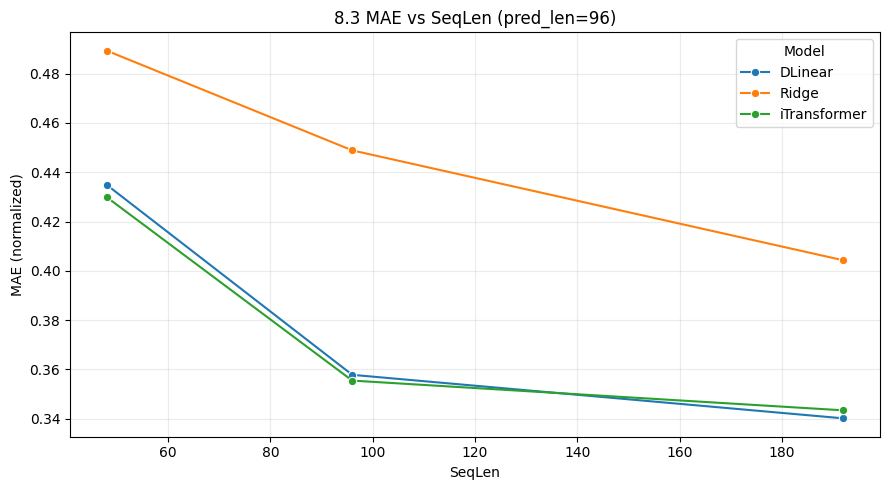

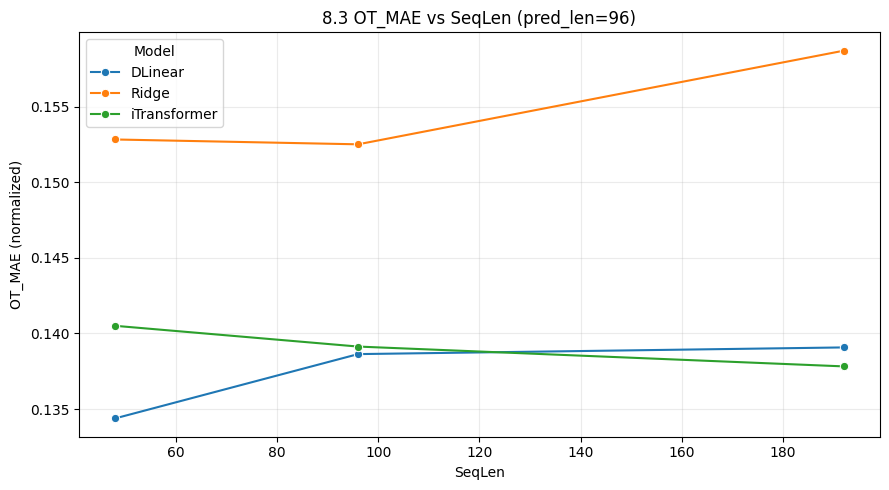

In [42]:
# 8.3 | Sequence length ablation (pred_len fixed to 96)
required_vars = ['X_scaled', 'y_scaled', 'target_dim']
required_helpers = ['_patch_config', '_restore_config', '_resolve_dl_params', '_make_split_windows_with_target', '_run_ridge', '_run_dl']
missing_vars = [k for k in required_vars if k not in globals()]
missing_helpers = [k for k in required_helpers if k not in globals()]
if missing_vars or missing_helpers:
    print('8.3 prerequisites missing. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_helpers:
        print('Missing helper functions:', missing_helpers)
else:
    ot_idx = int(target_cols.index('OT')) if ('target_cols' in globals() and 'OT' in target_cols) else int(target_dim - 1)
    seq_len_grid = [48, 96, 192]
    pred_len_local = 96
    seq_rows = []

    for seq_len_local in seq_len_grid:
        backup_cfg = _patch_config(seq_len=int(seq_len_local), pred_len=int(pred_len_local))
        try:
            X_tr, y_tr, X_va, y_va, X_te, y_te = _make_split_windows_with_target(
                X_scaled, y_scaled, seq_len_local, pred_len_local
            )

            for model_name in ['Ridge', 'iTransformer', 'DLinear']:
                try:
                    if model_name == 'Ridge':
                        metrics = _run_ridge(
                            X_tr, y_tr, X_te, y_te,
                            pred_len_local=pred_len_local,
                            target_dim_local=int(target_dim),
                            ot_pos_in_target=ot_idx
                        )
                    else:
                        params = _resolve_dl_params(model_name)
                        metrics = _run_dl(
                            model_name=model_name,
                            params=params,
                            X_tr=X_tr, y_tr=y_tr,
                            X_va=X_va, y_va=y_va,
                            X_te=X_te, y_te=y_te,
                            seq_len_local=seq_len_local,
                            pred_len_local=pred_len_local,
                            target_dim_local=int(target_dim),
                            ot_pos_in_target=ot_idx
                        )

                    seq_rows.append({
                        'Experiment': '8.3-SeqLen',
                        'Model': model_name,
                        'SeqLen': int(seq_len_local),
                        'PredLen': int(pred_len_local),
                        'InputDim': int(X_tr.shape[-1]),
                        'TargetDim': int(target_dim),
                        'NTrain': int(X_tr.shape[0]),
                        'NVal': int(X_va.shape[0]),
                        'NTest': int(X_te.shape[0]),
                        'MAE': float(metrics['MAE']),
                        'OT_MAE': float(metrics['OT_MAE']),
                        'MSE': float(metrics['MSE']),
                        'RMSE': float(metrics['RMSE']),
                        'Status': 'ok',
                        'Error': ''
                    })
                    print(f'[8.3] seq_len={seq_len_local} | {model_name} | MAE={metrics["MAE"]:.6f} | OT_MAE={metrics["OT_MAE"]:.6f}')
                except Exception as e:
                    seq_rows.append({
                        'Experiment': '8.3-SeqLen',
                        'Model': model_name,
                        'SeqLen': int(seq_len_local),
                        'PredLen': int(pred_len_local),
                        'InputDim': int(X_tr.shape[-1]),
                        'TargetDim': int(target_dim),
                        'NTrain': int(X_tr.shape[0]),
                        'NVal': int(X_va.shape[0]),
                        'NTest': int(X_te.shape[0]),
                        'MAE': np.nan,
                        'OT_MAE': np.nan,
                        'MSE': np.nan,
                        'RMSE': np.nan,
                        'Status': 'failed',
                        'Error': str(e)[:280]
                    })
                    print(f'[8.3][FAIL] seq_len={seq_len_local} | {model_name} | {e}')
        finally:
            _restore_config(backup_cfg)

    ablation83_df = pd.DataFrame(seq_rows).sort_values(['Model', 'SeqLen']).reset_index(drop=True)
    ablation83_df['ImprovementPct_vs96'] = np.nan
    ablation83_df['OT_ImprovementPct_vs96'] = np.nan
    for model_name in ablation83_df['Model'].unique():
        msk_ok = (ablation83_df['Model'] == model_name) & (ablation83_df['Status'] == 'ok')
        base_row = ablation83_df[msk_ok & (ablation83_df['SeqLen'] == 96)]
        if len(base_row) > 0:
            base_mae = float(base_row.iloc[0]['MAE'])
            base_ot = float(base_row.iloc[0]['OT_MAE'])
            ablation83_df.loc[msk_ok, 'ImprovementPct_vs96'] = (base_mae - ablation83_df.loc[msk_ok, 'MAE']) / (base_mae + 1e-8) * 100.0
            ablation83_df.loc[msk_ok, 'OT_ImprovementPct_vs96'] = (base_ot - ablation83_df.loc[msk_ok, 'OT_MAE']) / (base_ot + 1e-8) * 100.0

    expected_pairs = pd.MultiIndex.from_product([['Ridge', 'iTransformer', 'DLinear'], [48, 96, 192]], names=['Model', 'SeqLen'])
    observed_pairs = pd.MultiIndex.from_frame(ablation83_df[['Model', 'SeqLen']].drop_duplicates())
    missing_pairs = expected_pairs.difference(observed_pairs)
    if len(missing_pairs) > 0:
        print('8.3 warning: missing model-seq_len combinations:', [tuple(x) for x in missing_pairs.tolist()])

    ok_mask = ablation83_df['Status'] == 'ok'
    finite_mask = np.isfinite(ablation83_df['MAE']) & np.isfinite(ablation83_df['OT_MAE']) & np.isfinite(ablation83_df['MSE']) & np.isfinite(ablation83_df['RMSE'])
    if bool((ok_mask & (~finite_mask)).any()):
        print('8.3 warning: some rows are Status=ok but contain non-finite metrics.')

    print('8.3 result table: seq_len ablation')
    display(ablation83_df)

    failed_df = ablation83_df[ablation83_df['Status'] == 'failed'].copy()
    print(f'8.3 failure diagnostic: {len(failed_df)} failed runs out of {len(ablation83_df)} total.')
    if len(failed_df) > 0:
        display(failed_df[['Model', 'SeqLen', 'Error']])
        err_text = ' '.join(failed_df['Error'].fillna('').astype(str).tolist()).lower()
        if ('dataloader worker' in err_text) or ('exited unexpectedly' in err_text):
            print('Likely cause: DataLoader multiprocessing instability on Windows. _run_dl already has worker=0 retry path.')
        if ('out of memory' in err_text) or ('cuda' in err_text and 'memory' in err_text):
            print('Likely cause: GPU memory pressure at current batch/sequence settings.')

    ok_df = ablation83_df[ablation83_df['Status'] == 'ok'].copy()
    if len(ok_df) > 0:
        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='SeqLen', y='MAE', hue='Model', marker='o')
        plt.title('8.3 MAE vs SeqLen (pred_len=96)')
        plt.xlabel('SeqLen')
        plt.ylabel('MAE (normalized)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='SeqLen', y='OT_MAE', hue='Model', marker='o')
        plt.title('8.3 OT_MAE vs SeqLen (pred_len=96)')
        plt.xlabel('SeqLen')
        plt.ylabel('OT_MAE (normalized)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

# 8.4 Tokenization Strategy Comparison

This subsection compares variable-token and time-token proxy formulations within a controlled iTransformer-family setup.
The goal is to isolate tokenization effects from unrelated training changes.

[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.29004, val=0.27952
iTransformer epoch 05: train=0.22996, val=0.23731
iTransformer epoch 10: train=0.21724, val=0.23117
[8.4] VToken-Original (iTransformer) | MAE=0.354094 | OT_MAE=0.139500
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.28813, val=0.27677
iTransformer epoch 05: train=0.22899, val=0.23570
iTransformer epoch 10: train=0.21584, val=0.23044
[8.4] VToken-GroupedLoad (iTransformer) | MAE=0.355843 | OT_MAE=0.139708
iTransformer epoch 01: train=0.30461, val=0.42101
iTransformer epoch 05: train=0.27797, val=0.42031
iTransformer: early stopping at epoch 7
[8.4] TToken-Proxy (TimeTokenProxyRegressor) | MAE=0.537209 | OT_MAE=0.152056
8.4 result table: tokenization strategy ablation


,Experiment,Model,ModelImpl,TokenVariant,ComparabilityTag,SeqLenUsed,InputDimUsed,NTrain,NVal,NTest,PredLen,MAE,OT_MAE,MSE,RMSE,Status,Error,ImprovementPct_vs_VToken,OT_ImprovementPct_vs_VToken
0,8.4-TokenStrategy,iTransformer,TimeTokenProxyRegressor,TToken-Proxy,proxy,96,17,34369,11425,11425,96,0.537209,0.152056,0.686239,0.828395,ok,,-51.713662,-9.000389
1,8.4-TokenStrategy,iTransformer,iTransformer,VToken-GroupedLoad,strict,96,20,34369,11425,11425,96,0.355843,0.139708,0.329880,0.574352,ok,,-0.494074,-0.149236
2,8.4-TokenStrategy,iTransformer,iTransformer,VToken-Original,strict,96,17,34369,11425,11425,96,0.354094,0.139500,0.329116,0.573686,ok,,0.000000,0.000000


Note: GroupedLoad now preserves target channels and only adds grouped auxiliaries.
Note: TToken-Proxy now uses a dedicated time-token proxy model (no double transpose).


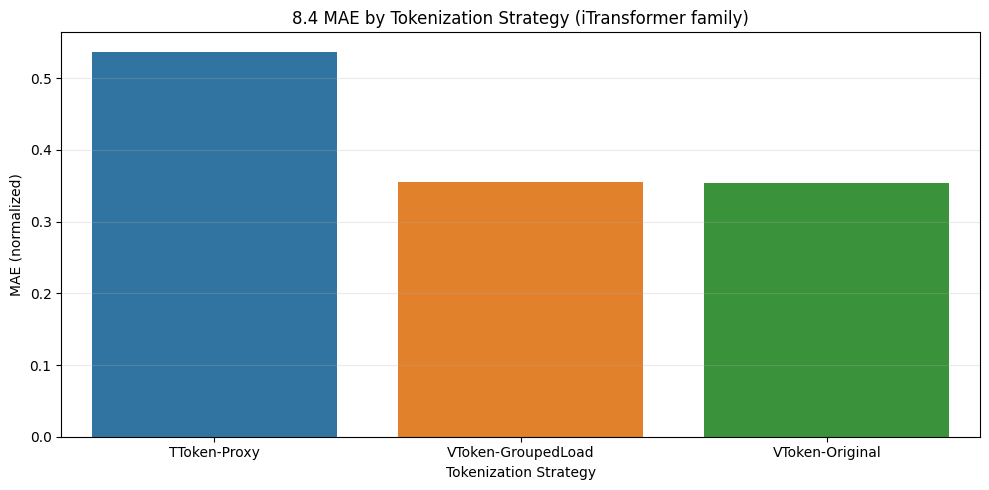

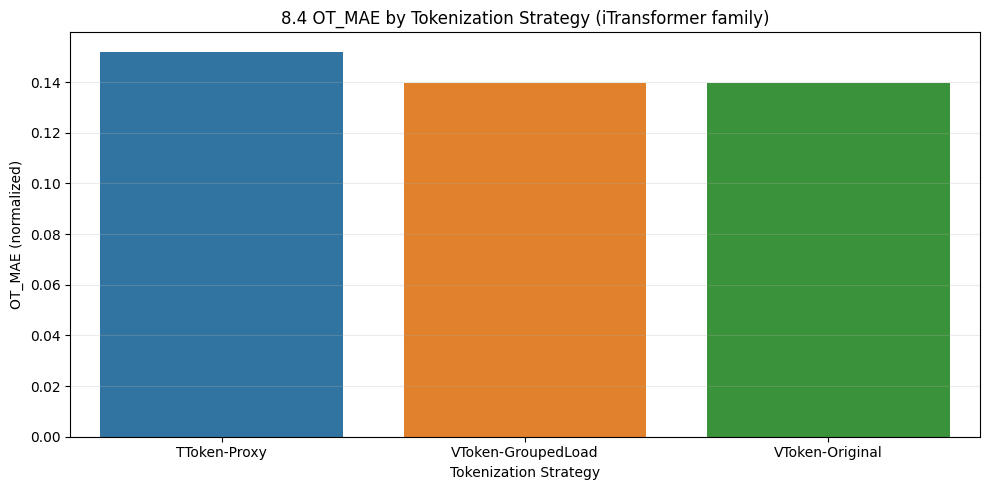

In [43]:
# 8.4 | Tokenization strategy ablation for iTransformer (fixed proxy design)
required_vars = ['X_scaled', 'y_scaled', 'target_dim']
required_helpers = ['_patch_config', '_restore_config', '_resolve_dl_params', '_make_split_windows_with_target', '_run_dl', 'build_dl_model']
missing_vars = [k for k in required_vars if k not in globals()]
missing_helpers = [k for k in required_helpers if k not in globals()]
if missing_vars or missing_helpers:
    print('8.4 prerequisites missing. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_helpers:
        print('Missing helper functions:', missing_helpers)
else:
    ot_idx = int(target_cols.index('OT')) if ('target_cols' in globals() and 'OT' in target_cols) else int(target_dim - 1)
    seq_len_base = 96
    pred_len_local = 96
    token_rows = []

    # Build baseline windows once.
    backup_cfg = _patch_config(seq_len=int(seq_len_base), pred_len=int(pred_len_local))
    try:
        X_tr_b, y_tr_b, X_va_b, y_va_b, X_te_b, y_te_b = _make_split_windows_with_target(
            X_scaled, y_scaled, seq_len_base, pred_len_local
        )
    finally:
        _restore_config(backup_cfg)

    def _grouped_token_windows(X, target_dim_local):
        """Build grouped token windows for iTransformer."""
        if X.ndim != 3:
            raise ValueError(f'Expected 3D input [N, seq_len, C], got shape={X.shape}')
        c = int(X.shape[2])
        td = int(target_dim_local)
        if c < td or td < 7:
            raise ValueError(f'Invalid channel setup for GroupedLoad: channels={c}, target_dim={td}')

        target_part = X[:, :, :td]
        extra_part = X[:, :, td:]

        # Build load-group summaries from the first six load channels, OT channel is preserved in target_part.
        g_h = target_part[:, :, [0, 1]].mean(axis=2, keepdims=True)
        g_m = target_part[:, :, [2, 3]].mean(axis=2, keepdims=True)
        g_l = target_part[:, :, [4, 5]].mean(axis=2, keepdims=True)
        grouped_aux = np.concatenate([g_h, g_m, g_l], axis=2).astype(np.float32)

        out = np.concatenate([target_part, grouped_aux, extra_part], axis=2).astype(np.float32)
        if out.shape[2] < td:
            raise ValueError(f'GroupedLoad output has fewer channels than target_dim: outC={out.shape[2]}, target_dim={td}')
        return out

    class TimeTokenProxyRegressor(nn.Module):
        """Time-token proxy regressor for iTransformer."""
        def __init__(self, input_dim, seq_len, pred_len, target_dim, d_model=96, nhead=4, num_layers=1, ff_dim=192, dropout=0.3, droppath=0.0):
            super().__init__()
            self.pred_len = int(pred_len)
            self.target_dim = int(target_dim)
            self.token_proj = nn.Linear(int(input_dim), int(d_model))
            enc_layer = nn.TransformerEncoderLayer(
                d_model=int(d_model), nhead=int(nhead), dim_feedforward=int(ff_dim), dropout=float(dropout), batch_first=True
            )
            self.encoder = nn.TransformerEncoder(enc_layer, num_layers=int(num_layers))
            self.droppath = DropPath(float(droppath)) if 'DropPath' in globals() else nn.Identity()
            self.head = nn.Linear(int(d_model), int(pred_len * target_dim))

        def forward(self, x):
            # x: [B, seq_len, input_dim], tokens are time steps.
            z = self.token_proj(x)
            z = self.encoder(z)
            z = self.droppath(z)
            z = z.mean(dim=1)
            pred = self.head(z)
            return pred.reshape(pred.size(0), -1)

    variants = [
        {
            'TokenVariant': 'VToken-Original',
            'ComparabilityTag': 'strict',
            'ModelImpl': 'iTransformer',
            'X_tr': X_tr_b, 'X_va': X_va_b, 'X_te': X_te_b,
            'seq_len_local': int(X_tr_b.shape[1]),
            'ot_pos_in_target': int(ot_idx)
        },
        {
            'TokenVariant': 'VToken-GroupedLoad',
            'ComparabilityTag': 'strict',
            'ModelImpl': 'iTransformer',
            'X_tr': _grouped_token_windows(X_tr_b, target_dim),
            'X_va': _grouped_token_windows(X_va_b, target_dim),
            'X_te': _grouped_token_windows(X_te_b, target_dim),
            'seq_len_local': int(X_tr_b.shape[1]),
            'ot_pos_in_target': int(ot_idx)
        },
        {
            'TokenVariant': 'TToken-Proxy',
            'ComparabilityTag': 'proxy',
            'ModelImpl': 'TimeTokenProxyRegressor',
            'X_tr': X_tr_b, 'X_va': X_va_b, 'X_te': X_te_b,
            'seq_len_local': int(X_tr_b.shape[1]),
            'ot_pos_in_target': int(ot_idx)
        }
    ]

    for v in variants:
        vname = v['TokenVariant']
        comparability = v['ComparabilityTag']
        model_impl = v['ModelImpl']
        X_tr = v['X_tr']
        X_va = v['X_va']
        X_te = v['X_te']
        seq_len_local = int(v['seq_len_local'])
        ot_pos = int(v['ot_pos_in_target'])

        backup_cfg = _patch_config(seq_len=seq_len_local, pred_len=int(pred_len_local))
        try:
            params = _resolve_dl_params('iTransformer')
            try:
                if model_impl == 'TimeTokenProxyRegressor':
                    _orig_build_dl_model = build_dl_model

                    def _build_dl_model_ttoken_proxy(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim):
                        """Build the time-token proxy model for iTransformer."""
                        if str(model_name).lower() == 'itransformer':
                            model = TimeTokenProxyRegressor(
                                input_dim=input_dim,
                                seq_len=seq_len,
                                pred_len=pred_len,
                                target_dim=target_dim,
                                d_model=int(params.get('d_model', 96)),
                                nhead=int(params.get('nhead', 4)),
                                num_layers=int(params.get('layers', 1)),
                                ff_dim=int(params.get('ffn', 192)),
                                dropout=float(params.get('dropout', CONFIG.get('itransformer_dropout', 0.25))),
                                droppath=float(params.get('droppath', CONFIG.get('itransformer_droppath', 0.0)))
                            )
                            if bool(CONFIG.get('dl_use_revin_all_models', True)):
                                model = RevINWrapper(model, target_dim=target_dim, pred_len=pred_len)
                            return model
                        return _orig_build_dl_model(model_name, params, input_dim, output_dim, seq_len, pred_len, target_dim)

                    globals()['build_dl_model'] = _build_dl_model_ttoken_proxy
                    try:
                        metrics = _run_dl(
                            model_name='iTransformer',
                            params=params,
                            X_tr=X_tr, y_tr=y_tr_b,
                            X_va=X_va, y_va=y_va_b,
                            X_te=X_te, y_te=y_te_b,
                            seq_len_local=seq_len_local,
                            pred_len_local=pred_len_local,
                            target_dim_local=int(target_dim),
                            ot_pos_in_target=ot_pos
                        )
                    finally:
                        globals()['build_dl_model'] = _orig_build_dl_model
                else:
                    metrics = _run_dl(
                        model_name='iTransformer',
                        params=params,
                        X_tr=X_tr, y_tr=y_tr_b,
                        X_va=X_va, y_va=y_va_b,
                        X_te=X_te, y_te=y_te_b,
                        seq_len_local=seq_len_local,
                        pred_len_local=pred_len_local,
                        target_dim_local=int(target_dim),
                        ot_pos_in_target=ot_pos
                    )

                token_rows.append({
                    'Experiment': '8.4-TokenStrategy',
                    'Model': 'iTransformer',
                    'ModelImpl': model_impl,
                    'TokenVariant': vname,
                    'ComparabilityTag': comparability,
                    'SeqLenUsed': int(seq_len_local),
                    'InputDimUsed': int(X_tr.shape[-1]),
                    'NTrain': int(X_tr.shape[0]),
                    'NVal': int(X_va.shape[0]),
                    'NTest': int(X_te.shape[0]),
                    'PredLen': int(pred_len_local),
                    'MAE': float(metrics['MAE']),
                    'OT_MAE': float(metrics['OT_MAE']),
                    'MSE': float(metrics['MSE']),
                    'RMSE': float(metrics['RMSE']),
                    'Status': 'ok',
                    'Error': ''
                })
                print(f'[8.4] {vname} ({model_impl}) | MAE={metrics["MAE"]:.6f} | OT_MAE={metrics["OT_MAE"]:.6f}')
            except Exception as e:
                token_rows.append({
                    'Experiment': '8.4-TokenStrategy',
                    'Model': 'iTransformer',
                    'ModelImpl': model_impl,
                    'TokenVariant': vname,
                    'ComparabilityTag': comparability,
                    'SeqLenUsed': int(seq_len_local),
                    'InputDimUsed': int(X_tr.shape[-1]),
                    'NTrain': int(X_tr.shape[0]),
                    'NVal': int(X_va.shape[0]),
                    'NTest': int(X_te.shape[0]),
                    'PredLen': int(pred_len_local),
                    'MAE': np.nan,
                    'OT_MAE': np.nan,
                    'MSE': np.nan,
                    'RMSE': np.nan,
                    'Status': 'failed',
                    'Error': str(e)[:280]
                })
                print(f'[8.4][FAIL] {vname} ({model_impl}) | {e}')
        finally:
            _restore_config(backup_cfg)

    ablation84_df = pd.DataFrame(token_rows).sort_values('TokenVariant').reset_index(drop=True)
    ablation84_df['ImprovementPct_vs_VToken'] = np.nan
    ablation84_df['OT_ImprovementPct_vs_VToken'] = np.nan
    msk_ok = ablation84_df['Status'] == 'ok'
    base_row = ablation84_df[msk_ok & (ablation84_df['TokenVariant'] == 'VToken-Original')]
    if len(base_row) > 0:
        base_mae = float(base_row.iloc[0]['MAE'])
        base_ot = float(base_row.iloc[0]['OT_MAE'])
        ablation84_df.loc[msk_ok, 'ImprovementPct_vs_VToken'] = (base_mae - ablation84_df.loc[msk_ok, 'MAE']) / (base_mae + 1e-8) * 100.0
        ablation84_df.loc[msk_ok, 'OT_ImprovementPct_vs_VToken'] = (base_ot - ablation84_df.loc[msk_ok, 'OT_MAE']) / (base_ot + 1e-8) * 100.0

    expected_variants = {'VToken-Original', 'VToken-GroupedLoad', 'TToken-Proxy'}
    observed_variants = set(ablation84_df['TokenVariant'].dropna().unique().tolist())
    missing_variants = sorted(list(expected_variants - observed_variants))
    if len(missing_variants) > 0:
        print('8.4 warning: missing tokenization variants:', missing_variants)

    finite_mask = np.isfinite(ablation84_df['MAE']) & np.isfinite(ablation84_df['OT_MAE']) & np.isfinite(ablation84_df['MSE']) & np.isfinite(ablation84_df['RMSE'])
    if bool((msk_ok & (~finite_mask)).any()):
        print('8.4 warning: some rows are Status=ok but contain non-finite metrics.')

    print('8.4 result table: tokenization strategy ablation')
    display(ablation84_df)
    print('Note: GroupedLoad now preserves target channels and only adds grouped auxiliaries.')
    print('Note: TToken-Proxy now uses a dedicated time-token proxy model (no double transpose).')

    ok_df = ablation84_df[ablation84_df['Status'] == 'ok'].copy()
    if len(ok_df) > 0:
        plt.figure(figsize=(10, 5))
        sns.barplot(data=ok_df, x='TokenVariant', y='MAE', hue='TokenVariant', dodge=False, legend=False)
        plt.title('8.4 MAE by Tokenization Strategy (iTransformer family)')
        plt.xlabel('Tokenization Strategy')
        plt.ylabel('MAE (normalized)')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(10, 5))
        sns.barplot(data=ok_df, x='TokenVariant', y='OT_MAE', hue='TokenVariant', dodge=False, legend=False)
        plt.title('8.4 OT_MAE by Tokenization Strategy (iTransformer family)')
        plt.xlabel('Tokenization Strategy')
        plt.ylabel('OT_MAE (normalized)')
        plt.grid(axis='y', alpha=0.25)
        plt.tight_layout()
        plt.show()

# 9. Robustness and Stress Testing

This section stress-tests trained models under realistic perturbations to evaluate reliability beyond clean-data accuracy.
It focuses on degradation trends and stability characteristics relevant to deployment.

# 9.1 Gaussian Noise Perturbation

This subsection injects Gaussian noise at multiple levels and tracks metric drift for each model.
It measures sensitivity to continuous sensor uncertainty.

In [44]:
# Phase 9| Robustness Analysis: Baseline Model Initialization & Context Setup

required_vars = [
    'CONFIG', 'X_scaled', 'y_scaled', 'target_dim', 'target_cols',
    'border1_train', 'border2_train', 'border1_val', 'border2_val',
    'border1_test', 'border2_test'
 ]
required_funcs = [
    '_patch_config', '_restore_config', '_resolve_dl_params',
    'make_windows', 'train_with_device_fallback', 'evaluate_loader'
 ]
missing_vars = [k for k in required_vars if k not in globals()]
missing_funcs = [k for k in required_funcs if k not in globals()]
if missing_vars or missing_funcs:
    print('Phase prerequisites missing. Run previous phase cells first.')
    if missing_vars:
        print('Missing variables:', missing_vars)
    if missing_funcs:
        print('Missing functions:', missing_funcs)
else:
    seq_len_local = 96
    pred_len_local = 96
    ot_idx = int(target_cols.index('OT')) if ('OT' in target_cols) else int(target_dim - 1)

    def _metrics_with_ot_local(y_true_flat, y_pred_flat, pred_len_local, target_dim_local, ot_pos_in_target):
        """Compute overall and OT-specific metrics from flattened predictions and targets."""
        y_true = np.asarray(y_true_flat, dtype=np.float32)
        y_pred = np.asarray(y_pred_flat, dtype=np.float32)
        mae = float(mean_absolute_error(y_true, y_pred))
        mse = float(mean_squared_error(y_true, y_pred))
        rmse = float(np.sqrt(mse))

        expected_dim = int(pred_len_local) * int(target_dim_local)
        if y_true.ndim != 2 or y_true.shape[1] != expected_dim:
            raise ValueError(f'Unexpected flattened shape {y_true.shape}, expected second dim={expected_dim}')

        y_true_3d = y_true.reshape(-1, int(pred_len_local), int(target_dim_local))
        y_pred_3d = y_pred.reshape(-1, int(pred_len_local), int(target_dim_local))
        ot_pos = int(np.clip(ot_pos_in_target, 0, int(target_dim_local) - 1))
        ot_true = y_true_3d[:, :, ot_pos].reshape(-1)
        ot_pred = y_pred_3d[:, :, ot_pos].reshape(-1)
        ot_mae = float(mean_absolute_error(ot_true, ot_pred))
        return {'MAE': mae, 'OT_MAE': ot_mae, 'MSE': mse, 'RMSE': rmse}

    def _build_eval_loader(X_eval, y_eval, batch_size=512):
        """Build a DataLoader for evaluation from numpy arrays."""
        X_tensor = torch.from_numpy(np.asarray(X_eval, dtype=np.float32))
        y_tensor = torch.from_numpy(np.asarray(y_eval, dtype=np.float32))
        ds = TensorDataset(X_tensor, y_tensor)
        return DataLoader(ds, batch_size=int(batch_size), shuffle=False, num_workers=0, pin_memory=False)

    def _eval_dl_metrics(model, run_device, X_eval, y_eval, pred_len_local, target_dim_local, ot_pos_in_target):
        """Evaluate a DL model and return metrics."""
        loader = _build_eval_loader(X_eval, y_eval, batch_size=int(CONFIG.get('batch_size', 160)))
        _, pred_scaled, true_scaled = evaluate_loader(model, loader, nn.SmoothL1Loss(beta=0.5), run_device)
        return _metrics_with_ot_local(true_scaled, pred_scaled, pred_len_local, target_dim_local, ot_pos_in_target)

    def _eval_ridge_metrics(model, X_eval, y_eval, pred_len_local, target_dim_local, ot_pos_in_target):
        """Evaluate a Ridge model and return metrics."""
        pred = model.predict(X_eval.reshape(len(X_eval), -1)).astype(np.float32)
        return _metrics_with_ot_local(y_eval, pred, pred_len_local, target_dim_local, ot_pos_in_target)

    backup_cfg = _patch_config(seq_len=int(seq_len_local), pred_len=int(pred_len_local))
    try:
        X_tr, y_tr, _ = make_windows(X_scaled, y_scaled, border1_train, border2_train, seq_len_local, pred_len_local)
        X_va, y_va, _ = make_windows(X_scaled, y_scaled, border1_val, border2_val, seq_len_local, pred_len_local)
        X_te, y_te, _ = make_windows(X_scaled, y_scaled, border1_test, border2_test, seq_len_local, pred_len_local)
        if len(X_tr) == 0 or len(X_va) == 0 or len(X_te) == 0:
            raise ValueError('Empty split windows for Phase 9.')

        robust_models = {}

        ridge_model = Ridge(alpha=float(CONFIG.get('ridge_alpha', 100.0)), solver='svd')
        ridge_model.fit(X_tr.reshape(len(X_tr), -1), y_tr)
        robust_models['Ridge'] = {'kind': 'ridge', 'model': ridge_model}
        print('Phase 9 setup: Ridge fitted.')

        for model_name in ['iTransformer', 'DLinear']:
            params = _resolve_dl_params(model_name)
            model, _, _, _, _, run_device = train_with_device_fallback(
                model_name=model_name,
                params=params,
                X_tr=X_tr, y_tr=y_tr,
                X_va=X_va, y_va=y_va,
                X_te=X_te, y_te=y_te,
                input_dim=int(X_tr.shape[-1]),
                output_dim=int(pred_len_local * target_dim),
                seq_len=int(seq_len_local),
                pred_len=int(pred_len_local),
                target_dim=int(target_dim)
            )
            robust_models[model_name] = {'kind': 'dl', 'model': model, 'device': run_device}
            print(f'Phase 9 setup: {model_name} fitted on device={run_device}.')

        robust9_ctx = {
            'seq_len': int(seq_len_local),
            'pred_len': int(pred_len_local),
            'target_dim': int(target_dim),
            'ot_idx': int(ot_idx),
            'X_te': X_te.astype(np.float32),
            'y_te': y_te.astype(np.float32),
            'models': robust_models,
            'metrics_fn': _metrics_with_ot_local,
            'eval_dl_fn': _eval_dl_metrics,
            'eval_ridge_fn': _eval_ridge_metrics
        }
        print('Phase 9 setup complete: robust9_ctx is ready for 9.1 and 9.2.')
    finally:
        _restore_config(backup_cfg)

Phase 9 setup: Ridge fitted.
[DL-INFO] iTransformer: using official THUML implementation.
iTransformer epoch 01: train=0.28615, val=0.27619
iTransformer epoch 05: train=0.22873, val=0.23481
iTransformer epoch 10: train=0.21620, val=0.22846
Phase 9 setup: iTransformer fitted on device=cuda.
[DL-INFO] DLinear: using official THUML implementation.
DLinear epoch 01: train=0.24154, val=0.24648
DLinear epoch 05: train=0.21472, val=0.23635
Phase 9 setup: DLinear fitted on device=cuda.
Phase 9 setup complete: robust9_ctx is ready for 9.1 and 9.2.


std=0.000 | Ridge | MAE=0.448848 | OT_MAE=0.152506
std=0.000 | iTransformer | MAE=0.355757 | OT_MAE=0.138556
std=0.000 | DLinear | MAE=0.357439 | OT_MAE=0.138814
std=0.010 | Ridge | MAE=0.449178 | OT_MAE=0.152819
std=0.010 | iTransformer | MAE=0.355612 | OT_MAE=0.138574
std=0.010 | DLinear | MAE=0.357460 | OT_MAE=0.138854
std=0.050 | Ridge | MAE=0.456556 | OT_MAE=0.158911
std=0.050 | iTransformer | MAE=0.355949 | OT_MAE=0.140741
std=0.050 | DLinear | MAE=0.358090 | OT_MAE=0.140326
std=0.100 | Ridge | MAE=0.478044 | OT_MAE=0.176314
std=0.100 | iTransformer | MAE=0.358216 | OT_MAE=0.147141
std=0.100 | DLinear | MAE=0.360042 | OT_MAE=0.144362
std=0.200 | Ridge | MAE=0.550056 | OT_MAE=0.225773
std=0.200 | iTransformer | MAE=0.366901 | OT_MAE=0.167063
std=0.200 | DLinear | MAE=0.366675 | OT_MAE=0.156358
result table: Gaussian noise robustness


,Experiment,Model,NoiseStd,MAE,OT_MAE,MSE,RMSE,Status,Error,MAE_Delta_vs0(%),OT_MAE_Delta_vs0(%)
0,9.1-GaussianNoise,DLinear,0.00,0.357439,0.138814,0.337692,0.581113,ok,,0.000000,0.000000
1,9.1-GaussianNoise,DLinear,0.01,0.357460,0.138854,0.337707,0.581126,ok,,0.006028,0.028189
2,9.1-GaussianNoise,DLinear,0.05,0.358090,0.140326,0.338028,0.581401,ok,,0.182255,1.088778
3,9.1-GaussianNoise,DLinear,0.10,0.360042,0.144362,0.339338,0.582527,ok,,0.728444,3.996704
4,9.1-GaussianNoise,DLinear,0.20,0.366675,0.156358,0.343986,0.586503,ok,,2.584133,12.637849
5,9.1-GaussianNoise,Ridge,0.00,0.448848,0.152506,0.440454,0.663667,ok,,0.000000,0.000000
6,9.1-GaussianNoise,Ridge,0.01,0.449178,0.152819,0.440860,0.663973,ok,,0.073602,0.205375
7,9.1-GaussianNoise,Ridge,0.05,0.456556,0.158911,0.449914,0.670757,ok,,1.717462,4.200011
8,9.1-GaussianNoise,Ridge,0.10,0.478044,0.176314,0.479084,0.692159,ok,,6.504684,15.611521
9,9.1-GaussianNoise,Ridge,0.20,0.550056,0.225773,0.592589,0.769798,ok,,22.548513,48.042334


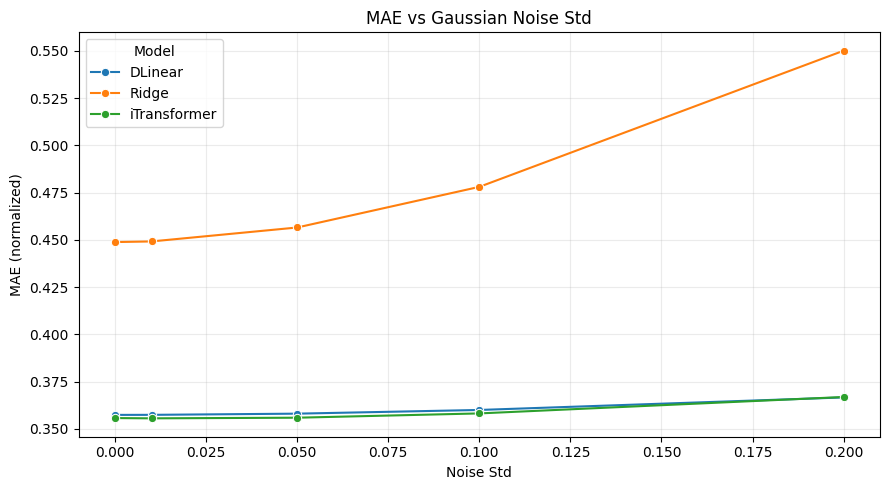

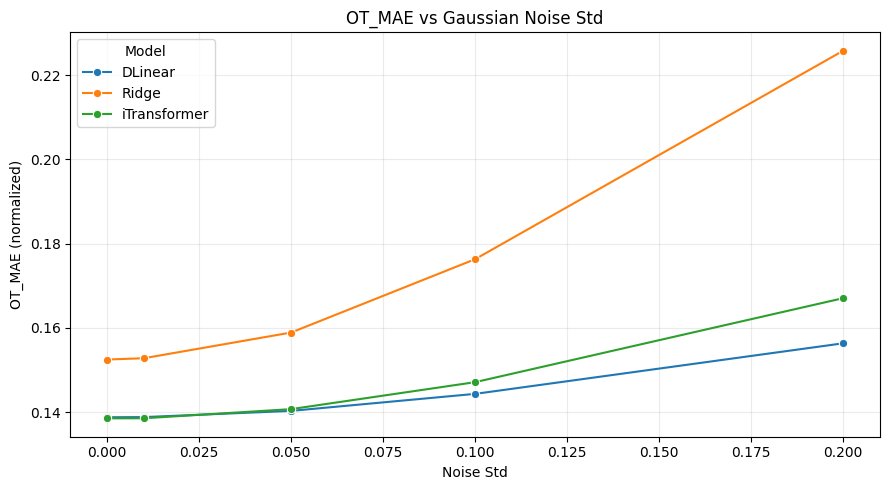

In [45]:
# Phase 9.1 | Robustness to Gaussian Noise in Inputs

if 'robust9_ctx' not in globals():
    print('robust9_ctx is missing. Run previous phase cells first.')
else:
    X_te = robust9_ctx['X_te']
    y_te = robust9_ctx['y_te']
    models = robust9_ctx['models']
    pred_len_local = int(robust9_ctx['pred_len'])
    target_dim_local = int(robust9_ctx['target_dim'])
    ot_idx = int(robust9_ctx['ot_idx'])
    eval_dl_fn = robust9_ctx['eval_dl_fn']
    eval_ridge_fn = robust9_ctx['eval_ridge_fn']

    noise_levels = [0.0, 0.01, 0.05, 0.1, 0.2]
    rng = np.random.RandomState(int(CONFIG.get('seed', 42)))
    noise_rows = []

    for std in noise_levels:
        if std <= 0.0:
            X_eval = X_te.copy()
        else:
            X_eval = (X_te + rng.normal(loc=0.0, scale=float(std), size=X_te.shape).astype(np.float32)).astype(np.float32)

        for model_name in ['Ridge', 'iTransformer', 'DLinear']:
            try:
                entry = models[model_name]
                if entry['kind'] == 'ridge':
                    metrics = eval_ridge_fn(entry['model'], X_eval, y_te, pred_len_local, target_dim_local, ot_idx)
                else:
                    metrics = eval_dl_fn(entry['model'], entry['device'], X_eval, y_te, pred_len_local, target_dim_local, ot_idx)

                noise_rows.append({
                    'Experiment': '9.1-GaussianNoise',
                    'Model': model_name,
                    'NoiseStd': float(std),
                    'MAE': float(metrics['MAE']),
                    'OT_MAE': float(metrics['OT_MAE']),
                    'MSE': float(metrics['MSE']),
                    'RMSE': float(metrics['RMSE']),
                    'Status': 'ok',
                    'Error': ''
                })
                print(f'std={std:.3f} | {model_name} | MAE={metrics["MAE"]:.6f} | OT_MAE={metrics["OT_MAE"]:.6f}')
            except Exception as e:
                noise_rows.append({
                    'Experiment': '9.1-GaussianNoise',
                    'Model': model_name,
                    'NoiseStd': float(std),
                    'MAE': np.nan,
                    'OT_MAE': np.nan,
                    'MSE': np.nan,
                    'RMSE': np.nan,
                    'Status': 'failed',
                    'Error': str(e)[:280]
                })
                print(f'[FAIL] std={std:.3f} | {model_name} | {e}')

    robustness9_noise_df = pd.DataFrame(noise_rows).sort_values(['Model', 'NoiseStd']).reset_index(drop=True)
    robustness9_noise_df['MAE_Delta_vs0(%)'] = np.nan
    robustness9_noise_df['OT_MAE_Delta_vs0(%)'] = np.nan

    for model_name in robustness9_noise_df['Model'].unique():
        msk_ok = (robustness9_noise_df['Model'] == model_name) & (robustness9_noise_df['Status'] == 'ok')
        base_row = robustness9_noise_df[msk_ok & (robustness9_noise_df['NoiseStd'] == 0.0)]
        if len(base_row) > 0:
            base_mae = float(base_row.iloc[0]['MAE'])
            base_ot = float(base_row.iloc[0]['OT_MAE'])
            robustness9_noise_df.loc[msk_ok, 'MAE_Delta_vs0(%)'] = (robustness9_noise_df.loc[msk_ok, 'MAE'] - base_mae) / (base_mae + 1e-8) * 100.0
            robustness9_noise_df.loc[msk_ok, 'OT_MAE_Delta_vs0(%)'] = (robustness9_noise_df.loc[msk_ok, 'OT_MAE'] - base_ot) / (base_ot + 1e-8) * 100.0

    print('result table: Gaussian noise robustness')
    display(robustness9_noise_df)

    ok_df = robustness9_noise_df[robustness9_noise_df['Status'] == 'ok'].copy()
    if len(ok_df) > 0:
        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='NoiseStd', y='MAE', hue='Model', marker='o')
        plt.title('MAE vs Gaussian Noise Std')
        plt.xlabel('Noise Std')
        plt.ylabel('MAE (normalized)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='NoiseStd', y='OT_MAE', hue='Model', marker='o')
        plt.title('OT_MAE vs Gaussian Noise Std')
        plt.xlabel('Noise Std')
        plt.ylabel('OT_MAE (normalized)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

# 9.2 Temporal Masking / Data Dropout

This subsection applies temporal masking to emulate missing observations in input sequences.
It evaluates robustness to incomplete context under consistent test-time settings.

rate=0.00 | Ridge | MAE=0.448848 | OT_MAE=0.152506
rate=0.00 | iTransformer | MAE=0.355757 | OT_MAE=0.138556
rate=0.00 | DLinear | MAE=0.357439 | OT_MAE=0.138814
rate=0.05 | Ridge | MAE=0.505659 | OT_MAE=0.217882
rate=0.05 | iTransformer | MAE=0.366035 | OT_MAE=0.189119
rate=0.05 | DLinear | MAE=0.366501 | OT_MAE=0.168152
rate=0.10 | Ridge | MAE=0.550085 | OT_MAE=0.270394
rate=0.10 | iTransformer | MAE=0.377451 | OT_MAE=0.235986
rate=0.10 | DLinear | MAE=0.377426 | OT_MAE=0.204287
rate=0.20 | Ridge | MAE=0.625400 | OT_MAE=0.394252
rate=0.20 | iTransformer | MAE=0.405571 | OT_MAE=0.337649
rate=0.20 | DLinear | MAE=0.407106 | OT_MAE=0.304086
rate=0.40 | Ridge | MAE=0.727086 | OT_MAE=0.619496
rate=0.40 | iTransformer | MAE=0.474774 | OT_MAE=0.554573
rate=0.40 | DLinear | MAE=0.482045 | OT_MAE=0.541225
result table: data dropout robustness


,Experiment,Model,DropoutRate,MAE,OT_MAE,MSE,RMSE,Status,Error,MAE_Delta_vs0(%),OT_MAE_Delta_vs0(%)
0,9.2-DataDropout,DLinear,0.00,0.357439,0.138814,0.337692,0.581113,ok,,0.000000,0.000000
1,9.2-DataDropout,DLinear,0.05,0.366501,0.168152,0.344490,0.586932,ok,,2.535357,21.134420
2,9.2-DataDropout,DLinear,0.10,0.377426,0.204287,0.353924,0.594915,ok,,5.591715,47.165586
3,9.2-DataDropout,DLinear,0.20,0.407106,0.304086,0.384211,0.619848,ok,,13.895356,119.059265
4,9.2-DataDropout,DLinear,0.40,0.482045,0.541225,0.482180,0.694392,ok,,34.860901,289.891082
5,9.2-DataDropout,Ridge,0.00,0.448848,0.152506,0.440454,0.663667,ok,,0.000000,0.000000
6,9.2-DataDropout,Ridge,0.05,0.505659,0.217882,0.515949,0.718296,ok,,12.657209,42.868536
7,9.2-DataDropout,Ridge,0.10,0.550085,0.270394,0.583849,0.764100,ok,,22.555034,77.300790
8,9.2-DataDropout,Ridge,0.20,0.625400,0.394252,0.711491,0.843499,ok,,39.334700,158.516437
9,9.2-DataDropout,Ridge,0.40,0.727086,0.619496,0.911841,0.954904,ok,,61.989555,306.212239


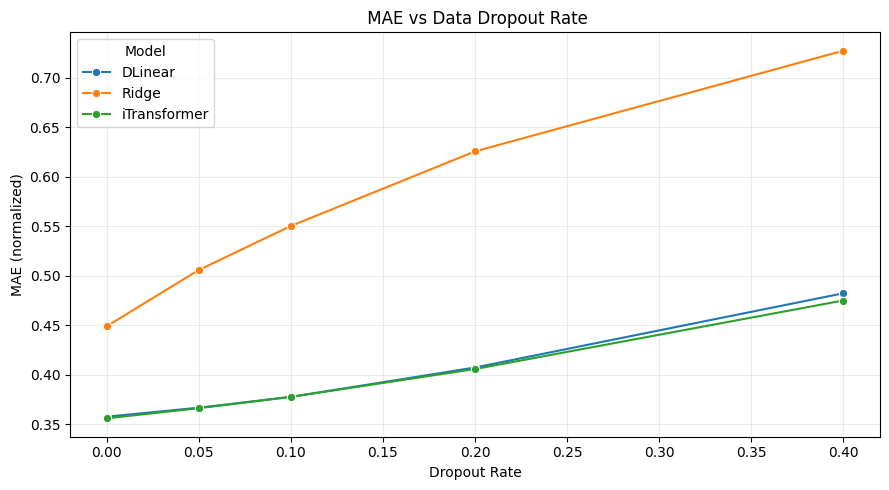

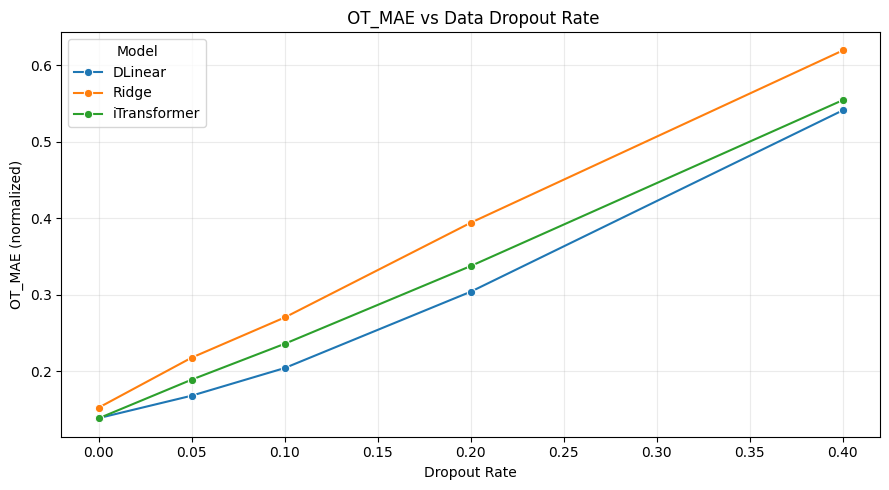

In [46]:
# 9.2 | Data dropout (masking) robustness
if 'robust9_ctx' not in globals():
    print('robust9_ctx is missing. Run previous phase cells first.')
else:
    X_te = robust9_ctx['X_te']
    y_te = robust9_ctx['y_te']
    models = robust9_ctx['models']
    pred_len_local = int(robust9_ctx['pred_len'])
    target_dim_local = int(robust9_ctx['target_dim'])
    ot_idx = int(robust9_ctx['ot_idx'])
    eval_dl_fn = robust9_ctx['eval_dl_fn']
    eval_ridge_fn = robust9_ctx['eval_ridge_fn']

    dropout_rates = [0.0, 0.05, 0.1, 0.2, 0.4]
    rng = np.random.RandomState(int(CONFIG.get('seed', 42)) + 2026)
    dropout_rows = []

    for rate in dropout_rates:
        if rate <= 0.0:
            X_eval = X_te.copy()
        else:
            # Randomly mask full time points (all channels) to simulate sensor outage timestamps.
            mask = (rng.rand(X_te.shape[0], X_te.shape[1], 1) < float(rate))
            X_eval = (X_te * (~mask)).astype(np.float32)

        for model_name in ['Ridge', 'iTransformer', 'DLinear']:
            try:
                entry = models[model_name]
                if entry['kind'] == 'ridge':
                    metrics = eval_ridge_fn(entry['model'], X_eval, y_te, pred_len_local, target_dim_local, ot_idx)
                else:
                    metrics = eval_dl_fn(entry['model'], entry['device'], X_eval, y_te, pred_len_local, target_dim_local, ot_idx)

                dropout_rows.append({
                    'Experiment': '9.2-DataDropout',
                    'Model': model_name,
                    'DropoutRate': float(rate),
                    'MAE': float(metrics['MAE']),
                    'OT_MAE': float(metrics['OT_MAE']),
                    'MSE': float(metrics['MSE']),
                    'RMSE': float(metrics['RMSE']),
                    'Status': 'ok',
                    'Error': ''
                })
                print(f'rate={rate:.2f} | {model_name} | MAE={metrics["MAE"]:.6f} | OT_MAE={metrics["OT_MAE"]:.6f}')
            except Exception as e:
                dropout_rows.append({
                    'Experiment': '9.2-DataDropout',
                    'Model': model_name,
                    'DropoutRate': float(rate),
                    'MAE': np.nan,
                    'OT_MAE': np.nan,
                    'MSE': np.nan,
                    'RMSE': np.nan,
                    'Status': 'failed',
                    'Error': str(e)[:280]
                })
                print(f'[FAIL] rate={rate:.2f} | {model_name} | {e}')

    robustness9_dropout_df = pd.DataFrame(dropout_rows).sort_values(['Model', 'DropoutRate']).reset_index(drop=True)
    robustness9_dropout_df['MAE_Delta_vs0(%)'] = np.nan
    robustness9_dropout_df['OT_MAE_Delta_vs0(%)'] = np.nan

    for model_name in robustness9_dropout_df['Model'].unique():
        msk_ok = (robustness9_dropout_df['Model'] == model_name) & (robustness9_dropout_df['Status'] == 'ok')
        base_row = robustness9_dropout_df[msk_ok & (robustness9_dropout_df['DropoutRate'] == 0.0)]
        if len(base_row) > 0:
            base_mae = float(base_row.iloc[0]['MAE'])
            base_ot = float(base_row.iloc[0]['OT_MAE'])
            robustness9_dropout_df.loc[msk_ok, 'MAE_Delta_vs0(%)'] = (robustness9_dropout_df.loc[msk_ok, 'MAE'] - base_mae) / (base_mae + 1e-8) * 100.0
            robustness9_dropout_df.loc[msk_ok, 'OT_MAE_Delta_vs0(%)'] = (robustness9_dropout_df.loc[msk_ok, 'OT_MAE'] - base_ot) / (base_ot + 1e-8) * 100.0

    print('result table: data dropout robustness')
    display(robustness9_dropout_df)

    ok_df = robustness9_dropout_df[robustness9_dropout_df['Status'] == 'ok'].copy()
    if len(ok_df) > 0:
        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='DropoutRate', y='MAE', hue='Model', marker='o')
        plt.title(' MAE vs Data Dropout Rate')
        plt.xlabel('Dropout Rate')
        plt.ylabel('MAE (normalized)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(9, 5))
        sns.lineplot(data=ok_df, x='DropoutRate', y='OT_MAE', hue='Model', marker='o')
        plt.title(' OT_MAE vs Data Dropout Rate')
        plt.xlabel('Dropout Rate')
        plt.ylabel('OT_MAE (normalized)')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

# 10. Final Conclusions and Deployment Recommendations

This section synthesizes benchmarking, ablation, and robustness evidence into deployment-oriented guidance.
Recommendations are based on observed trade-offs among accuracy, efficiency, and stability.

Final concise conclusion:
- Primary model: DLinear
- Fallback model: Ridge
- Primary online metric: OT_MAE (cross-mode fair metric).
- Decision basis: accuracy + anti-noise + anti-dropout + inference speed + training efficiency.
Deployment recommendations:
1) Deploy DLinear as primary and Ridge as fallback with automatic switch on sustained degradation.
2) Monitor OT_MAE, missing-rate, and noise proxy statistics in real time.
3) Trigger retraining when OT_MAE rolling mean degrades >10% for 7 consecutive days.
4) Use canary rollout (5-10% traffic) before full production release.


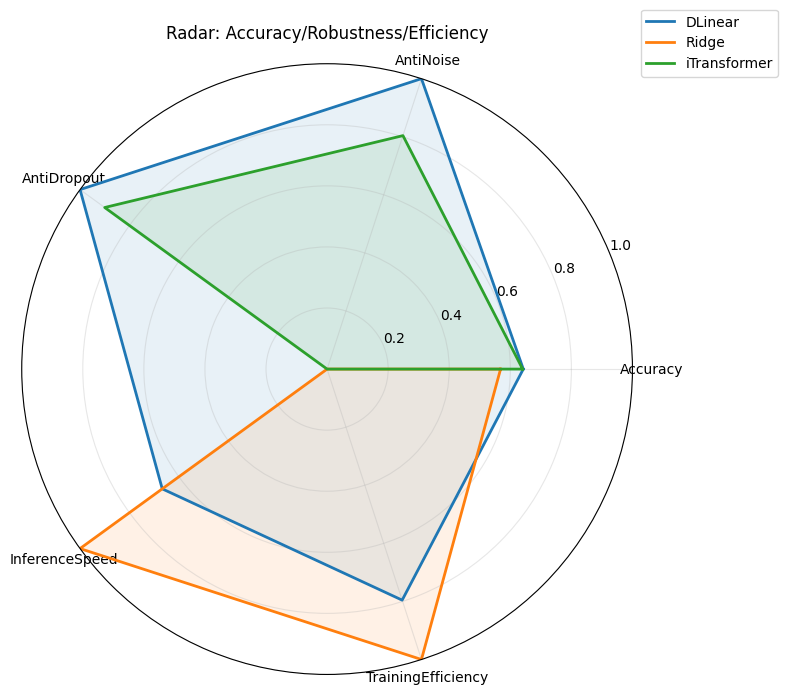

In [47]:
# Phase 10 | Performance Summary Table and Discussion

required_tables = ['ablation82_df', 'robustness9_noise_df', 'robustness9_dropout_df']
missing_tables = [t for t in required_tables if t not in globals()]
if len(missing_tables) > 0:
    print('Phase 10 prerequisites missing. Run previous phase cells first.')
    print('Missing tables:', missing_tables)
else:
    model_order = ['Ridge', 'iTransformer', 'DLinear']

    def _safe_ok(df):
        # Safely extract 'ok' rows (status = 'ok') from a DataFrame.
        if not isinstance(df, pd.DataFrame) or len(df) == 0:
            return pd.DataFrame()
        if 'Status' in df.columns:
            return df[df['Status'] == 'ok'].copy()
        return df.copy()

    ab82 = _safe_ok(ablation82_df)
    n9 = _safe_ok(robustness9_noise_df)
    d9 = _safe_ok(robustness9_dropout_df)

    clean_mae_map = {}
    if len(ab82) > 0 and set(['Model', 'CouplingMode', 'MAE']).issubset(ab82.columns):
        tmp = ab82[ab82['CouplingMode'] == 'M7->M7'][['Model', 'MAE']].drop_duplicates('Model')
        clean_mae_map = {str(r['Model']): float(r['MAE']) for _, r in tmp.iterrows()}

    if len(n9) > 0 and set(['Model', 'NoiseStd', 'MAE']).issubset(n9.columns):
        tmp0 = n9[n9['NoiseStd'] == 0.0][['Model', 'MAE']].drop_duplicates('Model')
        for _, r in tmp0.iterrows():
            m = str(r['Model'])
            if m not in clean_mae_map:
                clean_mae_map[m] = float(r['MAE'])

    # Robustness slopes (lower slope means more robust).
    noise_slope_map = {}
    if len(n9) > 0 and set(['Model', 'NoiseStd', 'OT_MAE']).issubset(n9.columns):
        for m, g in n9.groupby('Model'):
            g = g.sort_values('NoiseStd')
            if len(g) >= 2:
                noise_slope_map[str(m)] = float(np.polyfit(g['NoiseStd'].values.astype(float), g['OT_MAE'].values.astype(float), 1)[0])

    drop_slope_map = {}
    if len(d9) > 0 and set(['Model', 'DropoutRate', 'OT_MAE']).issubset(d9.columns):
        for m, g in d9.groupby('Model'):
            g = g.sort_values('DropoutRate')
            if len(g) >= 2:
                drop_slope_map[str(m)] = float(np.polyfit(g['DropoutRate'].values.astype(float), g['OT_MAE'].values.astype(float), 1)[0])

    # Efficiency metrics: latency and training time.
    latency_map = {}
    train_time_map = {}

    if 'dl_result_df' in globals() and isinstance(dl_result_df, pd.DataFrame) and len(dl_result_df) > 0:
        if set(['Model', 'LatencyMeanMs']).issubset(dl_result_df.columns):
            for _, r in dl_result_df[['Model', 'LatencyMeanMs']].dropna().drop_duplicates('Model').iterrows():
                latency_map[str(r['Model'])] = float(r['LatencyMeanMs'])
        if set(['Model', 'TrainTimeSec']).issubset(dl_result_df.columns):
            for _, r in dl_result_df[['Model', 'TrainTimeSec']].dropna().drop_duplicates('Model').iterrows():
                train_time_map[str(r['Model'])] = float(r['TrainTimeSec'])

    if 'latency_records' in globals() and isinstance(latency_records, dict):
        for m in model_order:
            key = f'{m}_M96'
            if key in latency_records and isinstance(latency_records[key], dict):
                latency_map.setdefault(m, float(latency_records[key].get('mean_ms', np.nan)))

    if 'ridge_lat_mean' in globals():
        latency_map.setdefault('Ridge', float(ridge_lat_mean))
    if 'ridge_train_time' in globals():
        train_time_map.setdefault('Ridge', float(ridge_train_time))

    rows = []
    for m in model_order:
        rows.append({
            'Model': m,
            'CleanMAE': clean_mae_map.get(m, np.nan),
            'NoiseSlope': noise_slope_map.get(m, np.nan),
            'DropSlope': drop_slope_map.get(m, np.nan),
            'LatencyMs': latency_map.get(m, np.nan),
            'TrainSec': train_time_map.get(m, np.nan),
        })
    compact_df = pd.DataFrame(rows)

    def _score_lower_better(series):
        "Convert a lower-is-better metric series into a 0-1 score (higher is better) using min-max scaling with clipping."
        s = pd.to_numeric(series, errors='coerce')
        valid = s[np.isfinite(s)]
        out = pd.Series(np.nan, index=s.index, dtype=np.float64)
        if len(valid) == 0:
            return out.fillna(0.0)
        vmin, vmax = float(valid.min()), float(valid.max())
        if abs(vmax - vmin) < 1e-12:
            return out.fillna(1.0)
        out.loc[np.isfinite(s)] = (vmax - s.loc[np.isfinite(s)]) / (vmax - vmin)
        return out.fillna(0.0)

    # Radar dimensions (all higher is better).
    compact_df['Accuracy'] = (1.0 - pd.to_numeric(compact_df['CleanMAE'], errors='coerce')).clip(lower=0.0, upper=1.0).fillna(0.0)
    compact_df['AntiNoise'] = _score_lower_better(compact_df['NoiseSlope'])
    compact_df['AntiDropout'] = _score_lower_better(compact_df['DropSlope'])
    compact_df['InferenceSpeed'] = _score_lower_better(compact_df['LatencyMs'])
    compact_df['TrainingEfficiency'] = _score_lower_better(compact_df['TrainSec'])

    radar_cols = ['Accuracy', 'AntiNoise', 'AntiDropout', 'InferenceSpeed', 'TrainingEfficiency']
    compact_df['FinalScore'] = compact_df[radar_cols].mean(axis=1)
    compact_df = compact_df.sort_values('FinalScore', ascending=False).reset_index(drop=True)

    # Concise conclusion output.
    best_model = str(compact_df.iloc[0]['Model']) if len(compact_df) > 0 else 'iTransformer'
    backup_model = str(compact_df.iloc[1]['Model']) if len(compact_df) > 1 else 'Ridge'

    print('Final concise conclusion:')
    print(f'- Primary model: {best_model}')
    print(f'- Fallback model: {backup_model}')
    print('- Primary online metric: OT_MAE (cross-mode fair metric).')
    print('- Decision basis: accuracy + anti-noise + anti-dropout + inference speed + training efficiency.')

    deploy_reco = [
        f'1) Deploy {best_model} as primary and {backup_model} as fallback with automatic switch on sustained degradation.',
        '2) Monitor OT_MAE, missing-rate, and noise proxy statistics in real time.',
        '3) Trigger retraining when OT_MAE rolling mean degrades >10% for 7 consecutive days.',
        '4) Use canary rollout (5-10% traffic) before full production release.'
    ]
    print('Deployment recommendations:')
    for line in deploy_reco:
        print(line)

    # Radar chart.
    labels = radar_cols
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]

    fig = plt.figure(figsize=(8, 7))
    ax = plt.subplot(111, polar=True)

    for _, r in compact_df.iterrows():
        vals = [float(r[c]) for c in labels]
        vals += vals[:1]
        ax.plot(angles, vals, linewidth=2, label=str(r['Model']))
        ax.fill(angles, vals, alpha=0.10)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_ylim(0.0, 1.0)
    ax.set_title('Radar: Accuracy/Robustness/Efficiency', pad=18)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.10))
    plt.tight_layout()
    plt.show()

    phase10_compact_df = compact_df[['Model'] + radar_cols + ['FinalScore']].copy()